**Project title:** *Education Insights Lab: Predicting STEM Certification from Institutional Characteristics*

**Full Name:** NKOBIE CHINEDU EMMANUEL

**Learner ID:** ALT/SOD/TIN/025/0168

**Email Address:** micnedu01@gmail.com

**GitHub Repository:** https://github.com/Scriptnedu/AltSchool-Africa-Capstone-Project.git

**Scenario:**

- An education-focused organization wants to understand how STEM certification is distributed across institutions in the United States.

- It holds a dataset of institutions with their school level, ownership, Title I status, staffing, funding, student demographics, socioeconomic indicators, and broadband access.

- The dataset also records whether each institution is STEM-certified (stem_certified_flag).

**Problem Definition:**

*The problem*

- The organization has many recorded characteristics but does not know how informative they are for identifying STEM-certified institutions.

- It also does not know which characteristics matter most.


*Why it Matters*

- It shows whether the organization's existing data can help distinguish certified from non-certified institutions.

- It identifies which characteristics (for example resources, staffing, or technology access) are most associated with certification, so the organization knows where to look next.

- It shows where the model's predictions are unreliable, which tells the organization where better or additional data is needed.

*Stakeholder*

- An education-focused organization that wants to compare institutional patterns and guide further analysis or planning.

**Data Understanding**

*Phase 1: Structure the Data*

In [1]:
# Import Relevant Libraries
# These libraries will be updated when necessary

# Libraries for data handling and visualization
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import itertools

# Libraries for statistical tests & checks
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score
from matplotlib.colors import ListedColormap
# Every test result is stored here and saved at the end for the final report
results = []

# Libraries for Machine Learning
import time
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, VotingClassifier
from sklearn.inspection import partial_dependence
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve, precision_recall_curve)
from sklearn.model_selection import (train_test_split, RandomizedSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_predict, cross_validate)
from sklearn.tree import DecisionTreeClassifier
from scipy.stats import loguniform, randint, uniform

# Set data display options
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

# A fixed seed so every shuffle and bootstrap gives the same answer when rerun
rng = np.random.default_rng(42)

# Saves charts to be reused in the final report
os.makedirs('/content/drive/MyDrive/AltSchool_Africa/reports/figures', exist_ok=True) # makes the directory for saving charts
def save_fig(name):
    plt.savefig(f'/content/drive/MyDrive/AltSchool_Africa/reports/figures/{name}.png', dpi=150, bbox_inches='tight') # saves the chart as an image


In [2]:
# Load the dataset of interest
# The us_education_system_dataset

us_edu_data = pd.read_csv("/content/drive/MyDrive/AltSchool_Africa/4th_Semester/us_education_system_dataset.csv")
print(f"Dataset Loaded Successfully with {us_edu_data.shape[0]:,} institution records and {us_edu_data.shape[1]} features.\n")
us_edu_data.head()

Dataset Loaded Successfully with 5,000 institution records and 35 features.



,institution_id,institution_name,state_code,state_name,county,nces_locale,level,control,title_i_status,total_enrollment,number_of_teachers,student_teacher_ratio,percent_free_reduced_lunch,racial_white_pct,racial_black_pct,racial_hispanic_pct,racial_asian_pct,racial_native_pct,racial_two_or_more_pct,special_education_pct,english_learner_pct,per_pupil_expenditure_usd,federal_funding_pct,state_funding_pct,local_funding_pct,math_proficiency_pct,reading_proficiency_pct,graduation_rate_pct,chronic_absenteeism_pct,avg_sat_score,avg_act_score,ap_ib_participation_pct,postsecondary_enrollment_pct,stem_certified_flag,broadband_access_pct
0,US-EDU-10001,Jefferson Elementary School,MA,Massachusetts,Central County,Suburban - Midsize,Elementary School,Public,Title I Schoolwide,447,30,14.8,48.9,70.9,2.4,15.4,8.1,0.1,3.1,14.4,12.9,12840,15.0,54.8,30.2,58.3,58.1,80.9,18.0,NaN,NaN,NaN,NaN,No,91.6
1,US-EDU-10002,Lakeshore Middle School,FL,Florida,Miami-Dade County,Suburban - Midsize,Middle School,Private Religious,Not Applicable,293,29,10.0,1.2,34.7,8.6,36.1,13.3,1.3,6.0,13.7,19.3,17009,0.0,2.0,98.0,84.8,98.0,93.5,17.8,NaN,NaN,NaN,NaN,No,94.4
2,US-EDU-10003,Meadowbrook Elementary Academy,TX,Texas,Bexar County,City - Large,Elementary School,Private For-Profit,Not Applicable,315,17,18.2,36.0,26.2,29.2,22.9,12.3,1.9,7.5,15.7,11.3,15374,10.7,55.5,33.8,54.6,66.2,80.2,19.5,NaN,NaN,NaN,NaN,No,94.0
3,US-EDU-10004,Roosevelt Primary School,FL,Florida,Palm Beach County,Suburban - Large,Elementary School,Public,Not Title I Eligible,389,34,11.3,15.1,49.2,16.7,4.3,26.4,0.1,3.3,13.8,9.8,17065,6.8,38.3,54.9,66.1,70.5,82.1,20.5,NaN,NaN,NaN,NaN,No,96.4
4,US-EDU-10005,Highland Park Primary School,MI,Michigan,Macomb County,Suburban - Large,Elementary School,Public,Title I Targeted,397,29,13.9,45.6,78.1,3.2,8.0,3.9,2.1,4.7,19.8,5.3,16823,15.0,42.3,42.7,54.6,46.7,90.2,19.9,NaN,NaN,NaN,NaN,No,86.3


In [3]:
# To better understand these features, let's list the column names
us_edu_data.columns

Index(['institution_id', 'institution_name', 'state_code', 'state_name', 'county', 'nces_locale', 'level', 'control', 'title_i_status', 'total_enrollment', 'number_of_teachers',
       'student_teacher_ratio', 'percent_free_reduced_lunch', 'racial_white_pct', 'racial_black_pct', 'racial_hispanic_pct', 'racial_asian_pct', 'racial_native_pct', 'racial_two_or_more_pct',
       'special_education_pct', 'english_learner_pct', 'per_pupil_expenditure_usd', 'federal_funding_pct', 'state_funding_pct', 'local_funding_pct', 'math_proficiency_pct', 'reading_proficiency_pct',
       'graduation_rate_pct', 'chronic_absenteeism_pct', 'avg_sat_score', 'avg_act_score', 'ap_ib_participation_pct', 'postsecondary_enrollment_pct', 'stem_certified_flag', 'broadband_access_pct'],
      dtype='object')

In [4]:
# Get the data overview
us_edu_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 35 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   institution_id                5000 non-null   object 
 1   institution_name              5000 non-null   object 
 2   state_code                    5000 non-null   object 
 3   state_name                    5000 non-null   object 
 4   county                        5000 non-null   object 
 5   nces_locale                   5000 non-null   object 
 6   level                         5000 non-null   object 
 7   control                       5000 non-null   object 
 8   title_i_status                5000 non-null   object 
 9   total_enrollment              5000 non-null   int64  
 10  number_of_teachers            5000 non-null   int64  
 11  student_teacher_ratio         5000 non-null   float64
 12  percent_free_reduced_lunch    5000 non-null   float64
 13  rac

- The dataset has 5,000 rows and 35 columns. Each row is one institution.

- Four columns (avg_sat_score, avg_act_score, ap_ib_participation_pct, postsecondary_enrollment_pct) have fewer than 5,000 values. We investigate them as we proceed to know why some values are missing.

In [5]:
# Split the features into identifiers, categorical and numerical groups to better organize the dataset

identifier_cols = ['institution_id', 'institution_name', 'state_code', 'state_name', 'county']
categorical_cols = ['nces_locale', 'level', 'control', 'title_i_status', 'stem_certified_flag']
numerical_cols = [c for c in us_edu_data.columns if c not in identifier_cols + categorical_cols]

print(f"Identifier columns ({len(identifier_cols)}): {identifier_cols}\n")
print(f"Categorical columns ({len(categorical_cols)}): {categorical_cols}\n")
print(f"Numerical columns ({len(numerical_cols)}): {numerical_cols}")

Identifier columns (5): ['institution_id', 'institution_name', 'state_code', 'state_name', 'county']

Categorical columns (5): ['nces_locale', 'level', 'control', 'title_i_status', 'stem_certified_flag']

Numerical columns (25): ['total_enrollment', 'number_of_teachers', 'student_teacher_ratio', 'percent_free_reduced_lunch', 'racial_white_pct', 'racial_black_pct', 'racial_hispanic_pct', 'racial_asian_pct', 'racial_native_pct', 'racial_two_or_more_pct', 'special_education_pct', 'english_learner_pct', 'per_pupil_expenditure_usd', 'federal_funding_pct', 'state_funding_pct', 'local_funding_pct', 'math_proficiency_pct', 'reading_proficiency_pct', 'graduation_rate_pct', 'chronic_absenteeism_pct', 'avg_sat_score', 'avg_act_score', 'ap_ib_participation_pct', 'postsecondary_enrollment_pct', 'broadband_access_pct']


- **Identifiers (5):** institution ID, name, state code, state name and county. These describe where an institution is and are not expected to be model features.

- **Categorical (5):** locale, school level, ownership, Title I status and the target stem_certified_flag.

- **Numerical (25):** enrollment, staffing, demographics, funding, academic outcomes and broadband access.

In [6]:
# Get statistical information about numerical features
us_edu_data[numerical_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
total_enrollment,5000.0,1375.88,3416.62,80.0,438.0,603.00,914.0,45252.0
number_of_teachers,5000.0,92.46,225.93,5.0,29.0,42.00,66.0,3279.0
student_teacher_ratio,5000.0,14.93,3.33,6.0,12.6,14.90,17.1,30.0
percent_free_reduced_lunch,5000.0,41.28,24.09,0.0,21.7,42.40,59.5,98.0
racial_white_pct,5000.0,48.08,19.63,3.9,33.0,48.85,63.9,92.1
racial_black_pct,5000.0,17.42,11.82,0.8,8.4,15.40,24.5,67.3
racial_hispanic_pct,5000.0,21.17,12.41,1.5,11.5,19.90,29.1,83.2
racial_asian_pct,5000.0,7.75,6.02,0.3,2.8,6.40,11.6,36.0
racial_native_pct,5000.0,1.44,1.34,0.1,0.2,1.20,2.2,9.6
racial_two_or_more_pct,5000.0,4.13,2.11,0.5,2.6,3.90,5.3,25.4


In [7]:
# Get the count of each categorical feature
# A for loop will be used for this

for column in categorical_cols:
    print(f"\nValue counts for {column}:")
    print(us_edu_data[column].value_counts())


Value counts for nces_locale:
nces_locale
Suburban - Large      1496
City - Large          1090
Suburban - Midsize     643
City - Midsize         541
Town - Fringe          395
Rural - Fringe         318
Rural - Remote         270
Town - Distant         247
Name: count, dtype: int64

Value counts for level:
level
Elementary School    2225
High School          1209
Middle School         996
K-12 Combined         212
4-Year University     204
2-Year College        154
Name: count, dtype: int64

Value counts for control:
control
Public                3547
Public Charter         577
Private Non-Profit     499
Private Religious      256
Private For-Profit     121
Name: count, dtype: int64

Value counts for title_i_status:
title_i_status
Title I Schoolwide      2180
Not Applicable          1108
Title I Targeted         945
Not Title I Eligible     767
Name: count, dtype: int64

Value counts for stem_certified_flag:
stem_certified_flag
No     4248
Yes     752
Name: count, dtype: int64


- **School level** has six values: Elementary (2,225), High School (1,209), Middle (996), K-12 Combined (212), 4-Year University (204) and 2-Year College (154). So the dataset mixes K-12 schools with colleges (358 rows).

- **Ownership** is mostly Public (3,547), then Public Charter (577), Private Non-Profit (499), Private Religious (256) and Private For-Profit (121).

- **Title I status** has a "Not Applicable" group of 1,108 rows. We look at who is in it in as we proceed.

*Phase 2: Target Variable*

In [8]:
# Inspect the target variable: stem_certified_flag

target_counts = us_edu_data['stem_certified_flag'].value_counts()
certified_share = (us_edu_data['stem_certified_flag'] == 'Yes').mean()

print(target_counts)
print(f"\nCertified share: {certified_share:.1%} of {len(us_edu_data['stem_certified_flag'])}")
print(f"Non-certified institutions for every certified one: {target_counts['No'] / target_counts['Yes']:.1f}")

stem_certified_flag
No     4248
Yes     752
Name: count, dtype: int64

Certified share: 15.0% of 5000
Non-certified institutions for every certified one: 5.6


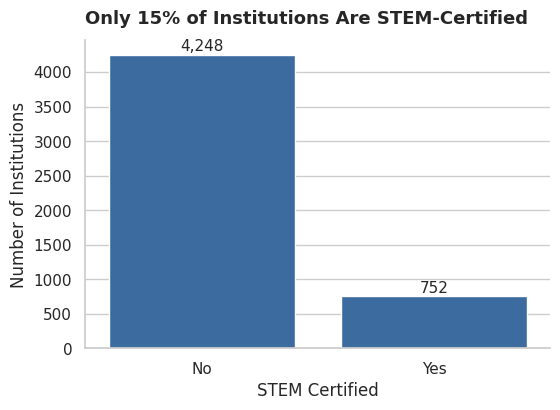

In [9]:
# Make a bar plot to better understand this
# applying Edward Tufte's data-to-ink ratio rule

sns.set_theme(style='whitegrid')
plt.figure(figsize=(6, 4))

ax = sns.barplot(x=target_counts.index,
                 y=target_counts.values,
                 color='#2B6CB0')
for i, v in enumerate(target_counts.values):
    ax.text(i, v + 60, f"{v:,}", ha='center', fontsize=11)

sns.despine() # To declutter

plt.title('Only 15% of Institutions Are STEM-Certified',
          fontsize=13, fontweight='bold', loc='left', pad=12)
plt.xlabel('STEM Certified')
plt.ylabel('Number of Institutions')
plt.show();

**Business Translation: Target Variable**

- 752 of 5,000 institutions (15.0%) are certified, so the target is imbalanced.

- A model that predicted "No" for every institution would be right about 85% of the time and would find no certified institution at all. So accuracy alone would be misleading.

- In the modelling stage we will use stratified splits and judge the model on precision, recall, F1-score and ROC-AUC.

*Phase 3: Missing Values*

In [10]:
# Inspect for missing values in the dataset
# This is to identify gaps that could crash the workflow as we advance

missing_counts = us_edu_data.isnull().sum().sort_values(ascending=False)
missing_report = pd.DataFrame({'Missing': missing_counts,
                               'Percent(%)': (missing_counts / len(us_edu_data) * 100).round(1)})
missing_report[missing_report['Missing'] > 0]

,Missing,Percent(%)
postsecondary_enrollment_pct,3579,71.6
ap_ib_participation_pct,3579,71.6
avg_act_score,3375,67.5
avg_sat_score,3375,67.5


- Missing values were found in four features: postsecondary_enrollment_pct, ap_ib_participation_pct, avg_act_score and avg_sat_score.

- Before deciding what to do, we check where the gaps sit.

In [11]:
# Inspect the share of values missing for each of the four features, by institution level

gap_cols = ['avg_sat_score', 'avg_act_score',
            'ap_ib_participation_pct', 'postsecondary_enrollment_pct']
missing_by_level = us_edu_data.groupby('level')[gap_cols].agg(lambda s: round(s.isna().mean() * 100, 1))
missing_by_level

,avg_sat_score,avg_act_score,ap_ib_participation_pct,postsecondary_enrollment_pct
level,,,,
2-Year College,100.0,100.0,100.0,100.0
4-Year University,0.0,0.0,100.0,100.0
Elementary School,100.0,100.0,100.0,100.0
High School,0.0,0.0,0.0,0.0
K-12 Combined,0.0,0.0,0.0,0.0
Middle School,100.0,100.0,100.0,100.0


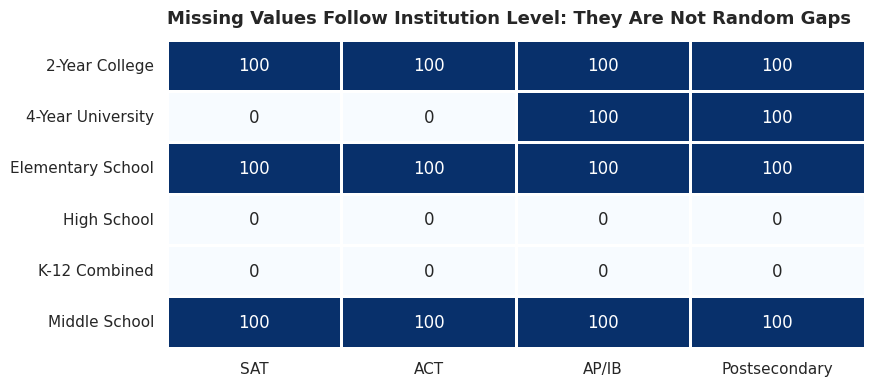

In [12]:
# Visualize the inspection for better understanding

plt.figure(figsize=(9, 4))
sns.heatmap(missing_by_level, annot=True, fmt='.0f', cmap='Blues',
            cbar=False, linewidths=1,
            xticklabels=['SAT', 'ACT', 'AP/IB', 'Postsecondary'])
plt.title('Missing Values Follow Institution Level: They Are Not Random Gaps',
          fontsize=13, fontweight='bold', loc='left', pad=12)
plt.xlabel('')
plt.ylabel('')
plt.show();

In [13]:
print("SAT and ACT are missing in exactly the same rows:",
      (us_edu_data['avg_sat_score'].isna() == us_edu_data['avg_act_score'].isna()).all())
print("AP/IB and postsecondary are missing in exactly the same rows:",
      (us_edu_data['ap_ib_participation_pct'].isna() == us_edu_data['postsecondary_enrollment_pct'].isna()).all())

SAT and ACT are missing in exactly the same rows: True
AP/IB and postsecondary are missing in exactly the same rows: True


**Business Translation: Missing Values**

- The variable missing_by_level shows the percentage of missing values for specific academic indicators (avg_sat_score, avg_act_score, ap_ib_participation_pct, and postsecondary_enrollment_pct) grouped by the institution's school level.

- By checking this, we can see that these missing values are not random gaps. Instead, they are entirely structured by school level:

- High School and K-12 Combined: Have 0% missing values for all of these metrics because standardized tests (SAT/ACT), Advanced Placement/International Baccalaureate (AP/IB) courses, and post-secondary enrollment tracking are standard features of high schools.

- 4-Year University: Has 0% missing for SAT and ACT scores, but 100% missing for AP/IB participation and postsecondary enrollment (as they are already higher education institutions and do not track high school outcomes).

- Elementary School, Middle School, and 2-Year College: Have 100% missing values for all four columns. This is because elementary/middle school students do not take college entrance exams (SAT/ACT) or college-prep courses (AP/IB), nor do they enroll directly into postsecondary institutions, not because someone forgot to record them.

- Ultimately, this analysis shows that these columns have structurally missing values based on school level, meaning we cannot easily impute them across the entire dataset without introducing noise. Filling them with zero or the average would invent data. This is carried into the cleaning stage as a decision to make carefully.

*Phase 4: Potential Anomalies*

In [14]:
# Check 1:
# Percentages must be between 0 and 100
# And related groups must add up to 100

pct_cols = [c for c in us_edu_data.columns if c.endswith('_pct')]
race_cols = [c for c in us_edu_data.columns if c.startswith('racial_')]
funding_cols = ['federal_funding_pct', 'state_funding_pct',
                'local_funding_pct']

out_of_range = {c: int(((us_edu_data[c] < 0) | (us_edu_data[c] > 100)).sum()) for c in pct_cols}

print("Percentage columns outside 0-100:",
      {k: v for k, v in out_of_range.items() if v} or "none")
print("Race columns add up to 100 in every row:",
      us_edu_data[race_cols].sum(axis=1).round(1).eq(100).all())
print("Funding columns add up to 100 in every row:",
      us_edu_data[funding_cols].sum(axis=1).round(1).eq(100).all())

Percentage columns outside 0-100: none
Race columns add up to 100 in every row: True
Funding columns add up to 100 in every row: True


In [15]:
# Check 2:
# Do the staffing columns agree with each other?

implied_ratio = us_edu_data['total_enrollment'] / us_edu_data['number_of_teachers']
ratio_gap = (implied_ratio - us_edu_data['student_teacher_ratio']).abs()
ratio_gap.describe().round(2)

,0
count,5000.00
mean,0.11
std,0.12
min,0.00
25%,0.03
50%,0.07
75%,0.14
max,1.50


In [16]:
# Check 3:
# Duplicates?

print("Fully duplicated rows:",
      us_edu_data.duplicated().sum())
print("Duplicated institution_id:",
      us_edu_data['institution_id'].duplicated().sum())
print(f"Unique institution names: {us_edu_data['institution_name'].nunique()} of {len(us_edu_data):,}")


Fully duplicated rows: 0
Duplicated institution_id: 0
Unique institution names: 780 of 5,000


In [17]:
# Rows that match on name, state, county, level and enrollment

dup_key = ['institution_name', 'state_code', 'county', 'level', 'total_enrollment']
us_edu_data[us_edu_data.duplicated(dup_key, keep=False)][dup_key + ['nces_locale', 'number_of_teachers', 'per_pupil_expenditure_usd']]

,institution_name,state_code,county,level,total_enrollment,nces_locale,number_of_teachers,per_pupil_expenditure_usd
1933,Sunset Elementary Academy,CA,Alameda County,Elementary School,361,Town - Fringe,24,17523
4941,Sunset Elementary Academy,CA,Alameda County,Elementary School,361,Rural - Fringe,21,14603


**Business Translation: Validity and Duplicates**

- No percentage falls outside 0 to 100. Race percentages and funding-source percentages add up to 100 in every row.

- The recorded student-teacher ratio matches enrollment divided by teachers closely (typical gap about 0.07), so the three staffing columns(total_enrollment, number_of_teachers, student_teacher_ratio) agree.

- Every institution_id is unique and no row is fully duplicated. Names repeat often (only 780 unique names for 5,000 rows), but the repeats sit in different counties, levels and sizes, so they look like generic school names and not repeated records.

- One pair matches on name, state, county, level and enrollment but differs on locale, teachers, funding and outcomes. It is flagged for the cleaning stage.

In [18]:
# Check 4:
# Do the values make sense for each institution level?

print("Title I status by level:")
print(pd.crosstab(us_edu_data['level'],
                  us_edu_data['title_i_status']))
print("\nTitle I status by ownership:")
print(pd.crosstab(us_edu_data['control'],
                  us_edu_data['title_i_status']))

Title I status by level:
title_i_status     Not Applicable  Not Title I Eligible  Title I Schoolwide  Title I Targeted
level                                                                                        
2-Year College                154                     0                   0                 0
4-Year University             204                     0                   0                 0
Elementary School             341                   377                1034               473
High School                   211                   185                 584               229
K-12 Combined                  39                    33                 102                38
Middle School                 159                   172                 460               205

Title I status by ownership:
title_i_status      Not Applicable  Not Title I Eligible  Title I Schoolwide  Title I Targeted
control                                                                                       
Pri

In [19]:
us_edu_data.groupby('level').agg(
    institutions=('institution_id', 'count'),
    median_enrollment=('total_enrollment', 'median'),
    avg_per_pupil_spend=('per_pupil_expenditure_usd', 'mean'),
    avg_free_reduced_lunch=('percent_free_reduced_lunch', 'mean'),
    avg_graduation_rate=('graduation_rate_pct', 'mean')
).round(1)

,institutions,median_enrollment,avg_per_pupil_spend,avg_free_reduced_lunch,avg_graduation_rate
level,,,,,
2-Year College,154,5556.0,21555.9,3.5,89.6
4-Year University,204,12625.5,20571.3,3.9,88.3
Elementary School,2225,476.0,16873.6,44.5,84.7
High School,1209,1098.0,16719.6,43.6,84.4
K-12 Combined,212,413.5,16463.0,43.4,84.4
Middle School,996,645.0,16870.5,44.4,84.9


**Business Translation: What Each Level Looks Like**

- **Title I "Not Applicable"** covers every college and every private K-12 school (1,108 rows) and no public or charter school. It is a code for institution type, which is different from "Not Title I Eligible" (a public or charter school that does not qualify). It should be kept as its own category and not treated as missing.

- **Colleges and universities differ sharply from K-12 schools:** far larger enrollment, higher per-pupil spending (about 20,600 to 21,600 USD versus about 16,500 to 16,900 USD) and a free/reduced-lunch share of about 4% versus about 44%. Whether to keep them in one model is a decision for the cleaning stage.

- **Graduation rate is filled for every level**, including elementary and middle schools, where it is not a natural measure. Its meaning should be confirmed before it is used.

In [20]:
# Check 5:
# Outliers using the IQR rule

def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).sum())

for column in ['total_enrollment', 'number_of_teachers',
               'per_pupil_expenditure_usd', 'student_teacher_ratio']:
    print(f"{column:28s} {iqr_outliers(us_edu_data[column]):4d} outliers")

total_enrollment              480 outliers
number_of_teachers            486 outliers
per_pupil_expenditure_usd     152 outliers
student_teacher_ratio          28 outliers


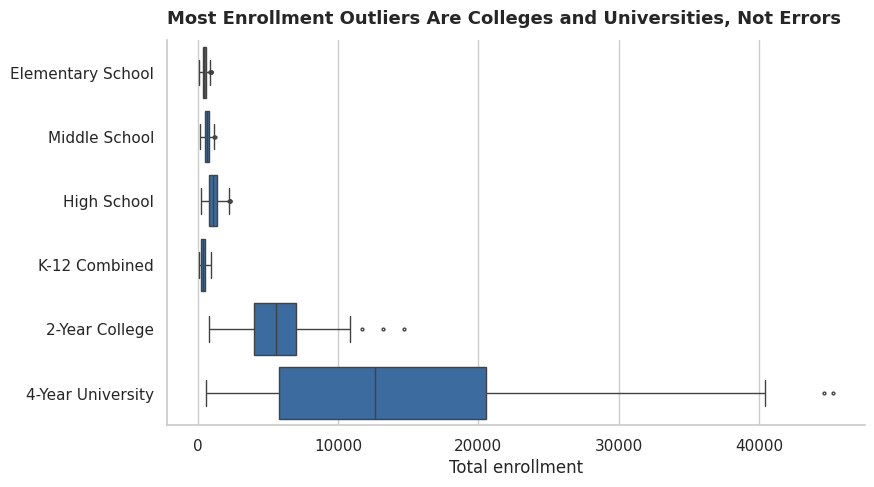

In [21]:
# Visualize levels by total enrollment to better understand the outliers

plt.figure(figsize=(9, 5))
sns.boxplot(data= us_edu_data, y='level', x='total_enrollment',
            color='#2B6CB0', fliersize=2,
            order=['Elementary School', 'Middle School',
                   'High School', 'K-12 Combined',
                   '2-Year College', '4-Year University'])
sns.despine()
plt.title('Most Enrollment Outliers Are Colleges and Universities, Not Errors',
          fontsize=13, fontweight='bold', loc='left', pad=12)
plt.xlabel('Total enrollment')
plt.ylabel('')
plt.show();

**Business Translation: Outliers**

- Enrollment, teacher count and per-pupil spending show hundreds of statistical outliers, but most of them are simply the 2-Year Colleges and 4-Year Universities, which are legitimately much larger and better funded than schools.

- Deleting them would remove real institutions. They are better handled by comparing within each level.

*Phase 5: Investigate Relationships*

In [22]:
# Investigate certification by level, Ownership(control) and Title I status

us_edu_data['is_certified'] = (us_edu_data['stem_certified_flag'] == 'Yes').astype(int)

for column in ['level', 'control', 'title_i_status']:
    summary = us_edu_data.groupby(column)['is_certified'].agg(['mean', 'sum'])
    summary.columns = ['certified_%', 'num_certified']
    summary['certified_%'] = (summary['certified_%'] * 100).round(1)
    print(summary.sort_values('certified_%', ascending=False), "\n")

                   certified_%  num_certified
level                                        
4-Year University         22.5             46
High School               22.2            269
Elementary School         12.5            278
Middle School             11.8            118
K-12 Combined             11.3             24
2-Year College            11.0             17 

                    certified_%  num_certified
control                                       
Private Non-Profit         16.4             82
Private Religious          15.2             39
Public                     15.1            535
Public Charter             14.0             81
Private For-Profit         12.4             15 

                      certified_%  num_certified
title_i_status                                  
Not Applicable               16.1            178
Title I Schoolwide           15.6            339
Title I Targeted             14.0            132
Not Title I Eligible         13.4            103 



In [23]:
# Investigate just level
level_rate = (us_edu_data.groupby('level')['is_certified'].mean() * 100).sort_values(ascending=False).reset_index()
print(level_rate)
print(f"\nOverall Level rate is {level_rate['is_certified'].mean():.1f}%")

               level  is_certified
0  4-Year University     22.549020
1        High School     22.249793
2  Elementary School     12.494382
3      Middle School     11.847390
4      K-12 Combined     11.320755
5     2-Year College     11.038961

Overall Level rate is 15.3%


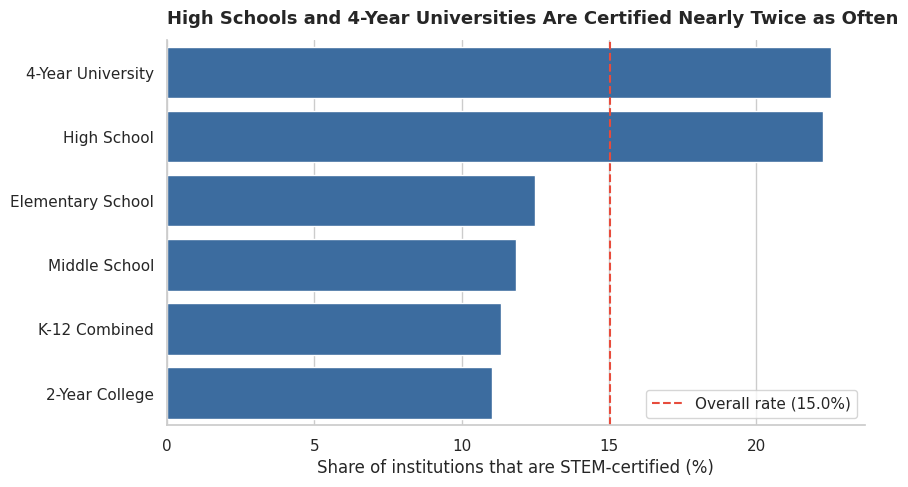

In [24]:
# Visualize

plt.figure(figsize=(9, 5))
sns.barplot(data=level_rate, x='is_certified', y='level', color='#2B6CB0')
plt.axvline(certified_share * 100, color='#E74C3C',
            linestyle='--', label='Overall rate (15.0%)')

sns.despine()

plt.title('High Schools and 4-Year Universities Are Certified Nearly Twice as Often',
          fontsize=13, fontweight='bold', loc='left', pad=12)
plt.xlabel('Share of institutions that are STEM-certified (%)')
plt.ylabel('')
plt.legend()
plt.show();

**Business Translation: First Look at Certification Patterns**

- High Schools (22.2%) and 4-Year Universities (22.5%) are certified at nearly twice the rate of the other levels (11.0% to 12.5%).

- Differences by ownership/control (12.4% to 16.4%) and by Title I status (13.4% to 16.1%) look much smaller. This is only a first look and has not been tested statistically.

- These are patterns in this dataset, not proof that any factor causes certification.

**Relationships to investigated as we proceed:**

1. Certification by school level and ownership, within level so colleges do not distort the picture.
2. Certification and Title I status (chi-square test of independence).
3. Funding, staffing and socioeconomic indicators versus certification.
4. Broadband access versus certification.
5. Whether the readiness measures (SAT, AP/IB) carry signal for the levels where they exist, and whether they risk data leakage.

*Phase 6: Data Dictionary*

In [25]:
# Create a data dictionary

data_dictionary = pd.DataFrame([
 ('institution_id', 'Identifier', 'Unique institution ID', 'Row key (not a model feature)'),
 ('institution_name', 'Identifier', 'Institution name; many names repeat across states', 'Not a model feature'),
 ('state_code', 'Categorical', 'Two-letter state code (51 values)', 'Location context'),
 ('state_name', 'Categorical', 'State name (matches state_code)', 'Location context'),
 ('county', 'Categorical', "County name (104 distinct; names such as 'Washington County' appear in many states)", 'Location context; verify county-state pairs'),
 ('nces_locale', 'Categorical', 'Locale type, for example Suburban - Large, City - Midsize, Rural - Remote (8 values)', 'Context / possible feature'),
 ('level', 'Categorical', 'School level: Elementary, Middle, High, K-12 Combined, 2-Year College, 4-Year University', 'Key segment and feature'),
 ('control', 'Categorical', 'Ownership: Public, Public Charter, Private Non-Profit, Private Religious, Private For-Profit', 'Opportunity / context feature'),
 ('title_i_status', 'Categorical', 'Title I classification: Schoolwide, Targeted, Not Title I Eligible, Not Applicable', 'Opportunity / context feature'),
 ('total_enrollment', 'Numerical', 'Number of enrolled students', 'Institutional size'),
 ('number_of_teachers', 'Numerical', 'Number of teachers', 'Staffing'),
 ('student_teacher_ratio', 'Numerical', 'Students per teacher', 'Staffing'),
 ('percent_free_reduced_lunch', 'Numerical', 'Share of students receiving free or reduced-price lunch', 'Socioeconomic indicator'),
 ('racial_white_pct', 'Numerical', 'Percent of students who are White', 'Demographics'),
 ('racial_black_pct', 'Numerical', 'Percent of students who are Black', 'Demographics'),
 ('racial_hispanic_pct', 'Numerical', 'Percent of students who are Hispanic', 'Demographics'),
 ('racial_asian_pct', 'Numerical', 'Percent of students who are Asian', 'Demographics'),
 ('racial_native_pct', 'Numerical', 'Percent of students who are Native', 'Demographics'),
 ('racial_two_or_more_pct', 'Numerical', 'Percent of students of two or more races', 'Demographics'),
 ('special_education_pct', 'Numerical', 'Percent of students in special education', 'Student needs'),
 ('english_learner_pct', 'Numerical', 'Percent of students who are English learners', 'Student needs'),
 ('per_pupil_expenditure_usd', 'Numerical', 'Spending per pupil in US dollars', 'Funding'),
 ('federal_funding_pct', 'Numerical', 'Share of funding from federal sources', 'Funding mix'),
 ('state_funding_pct', 'Numerical', 'Share of funding from state sources', 'Funding mix'),
 ('local_funding_pct', 'Numerical', 'Share of funding from local sources', 'Funding mix'),
 ('math_proficiency_pct', 'Numerical', 'Percent of students proficient in mathematics', 'Academic outcome'),
 ('reading_proficiency_pct', 'Numerical', 'Percent of students proficient in reading', 'Academic outcome'),
 ('graduation_rate_pct', 'Numerical', 'Graduation rate (populated for every level; meaning below high school to be confirmed)', 'Academic outcome'),
 ('chronic_absenteeism_pct', 'Numerical', 'Percent of students chronically absent', 'Engagement / outcome'),
 ('avg_sat_score', 'Numerical', 'Average SAT score; missing outside High School, K-12 Combined, 4-Year University', 'Readiness (structurally missing)'),
 ('avg_act_score', 'Numerical', 'Average ACT score; same coverage as SAT', 'Readiness (structurally missing)'),
 ('ap_ib_participation_pct', 'Numerical', 'AP/IB participation; present only for High School and K-12 Combined', 'Readiness (structurally missing)'),
 ('postsecondary_enrollment_pct', 'Numerical', 'Postsecondary enrollment; present only for High School and K-12 Combined', 'Readiness (structurally missing)'),
 ('stem_certified_flag', 'Categorical (target)', 'Whether the institution is STEM certified (Yes / No); certification definition not given', 'TARGET'),
 ('broadband_access_pct', 'Numerical', 'Percent with broadband access', 'Technology access'),
], columns=['variable', 'type', 'description', 'expected_use'])


In [26]:
# Safety check:
# The dictionary must cover every column in the dataset (is_certified was added)

assert set(data_dictionary['variable']) == set(us_edu_data.columns) - {'is_certified'}, "dictionary and data columns differ"

data_dictionary['missing_pct'] = data_dictionary['variable'].map((us_edu_data.isna().mean() * 100).round(1))
data_dictionary.to_csv('/content/drive/MyDrive/AltSchool_Africa/4th_Semester/data_dictionary.csv', index=False)
data_dictionary

,variable,type,description,expected_use,missing_pct
0,institution_id,Identifier,Unique institution ID,Row key (not a model feature),0.0
1,institution_name,Identifier,Institution name; many names repeat across states,Not a model feature,0.0
2,state_code,Categorical,Two-letter state code (51 values),Location context,0.0
3,state_name,Categorical,State name (matches state_code),Location context,0.0
4,county,Categorical,County name (104 distinct; names such as 'Wash...,Location context; verify county-state pairs,0.0
5,nces_locale,Categorical,"Locale type, for example Suburban - Large, Cit...",Context / possible feature,0.0
6,level,Categorical,"School level: Elementary, Middle, High, K-12 C...",Key segment and feature,0.0
7,control,Categorical,"Ownership: Public, Public Charter, Private Non...",Opportunity / context feature,0.0
8,title_i_status,Categorical,"Title I classification: Schoolwide, Targeted, ...",Opportunity / context feature,0.0
9,total_enrollment,Numerical,Number of enrolled students,Institutional size,0.0


**What was found:**

- The dataset is complete in structure: 5,000 unique institutions, 35 columns, no duplicate IDs, no impossible percentages and internally consistent staffing and funding columns.

- The only missing values are four readiness measures, and they are missing by institution level, which makes them a feature of how the data is organised, not a recording failure.

- The target is imbalanced (15.0% certified), and a first look shows certification is more common among High Schools and 4-Year Universities.



*Primary Research Question:*

- How well can institutional characteristics predict whether an institution is STEM-certified?

*Supporting Questions:*

- How common is STEM certification in the dataset, and how does it vary by school level and ownership?

- Is STEM certification statistically associated with Title I status?

- Which characteristics contribute most to the model's predictions?

- How reliably does the model identify certified and non-certified institutions, and what kinds of errors does it make?

- Does model performance differ across school levels or ownership types?

*Assumptions:*

- Each row represents one institution, and stem_certified_flag is accurate and consistently recorded.

- The recorded characteristics are available before or independent of certification status. Variables that may be consequences of certification will be reviewed before modeling to avoid misleading results.

- Missing values may reflect school level or data availability rather than random gaps. This would be investigated before deciding to remove, impute, or retain them.


*Limitations:*

- The dataset alone doesn't define how STEM certification is awarded or how the data were collected. This would be verified if possible.

- The data are observational and institution-level, so results may show associations and predictive patterns only. They cannot establish cause and effect or describe individual students.

- Class imbalance or missing data may affect model performance.

- Results apply to this dataset and may not generalize to other institutions or years.

*A Summary of How This Project Would be Approached.*

- **Dataset:** The us_education_system_dataset

- **Task:** Binary classification with stem_certified_flag as the target; each row is one institution.

- **Models:** Logistic Regression as an interpretable baseline, compared with Random Forest.


- **Preparation:** Preprocessing in a scikit-learn pipeline so that cleaning, encoding, and scaling are reproducible and applied only to training data within each split.


- **Evaluation:** Accuracy, precision, recall, F1-score, confusion matrix, and ROC-AUC.

- *If certified institutions are a small share of the data, accuracy alone can be misleading, so precision, recall, and F1 will guide model choice.*

- **Interpretation:** Model coefficients and permutation importance, reported as predictive importance, not causal effect.



**Data Cleaning**

*Here, we will turn the audit from the data understanding stage into clear cleaning decisions/options: What to remove, What to fill in and what to leave alone.*

**Findings from the Data understandung stage:**

1. SAT, ACT, AP/IB and postsecondary enrollment are missing by institution level

2. No impossible percentages, but we only checked a few rules

3. Names repeat often and one near-duplicate pair was flagged

4. 358 colleges and universities sit alongside K-12 schools; most outliers are colleges

5. Title I "Not Applicable" covers colleges and private K-12 schools

6. Graduation rate is filled for every level.

In [27]:
# Create a copy of the original dataset
data_copy = us_edu_data.copy()
data_copy.shape

(5000, 36)

*Phase 1: Missing Values*

In [28]:
# which columns have missing values and how many

gap_cols = ['avg_sat_score', 'avg_act_score', 'ap_ib_participation_pct', 'postsecondary_enrollment_pct']

missing_counts = data_copy[gap_cols].isnull().sum()
missing_report = pd.DataFrame({'missing': missing_counts,
                               'percent': (missing_counts / len(data_copy) * 100).round(1)})
missing_report

,missing,percent
avg_sat_score,3375,67.5
avg_act_score,3375,67.5
ap_ib_participation_pct,3579,71.6
postsecondary_enrollment_pct,3579,71.6


In [29]:
# Investigate why
# share missing in each of the six institution levels

missing_by_level = data_copy.groupby('level')[gap_cols].agg(lambda s: round(s.isna().mean() * 100, 1))
missing_by_level

,avg_sat_score,avg_act_score,ap_ib_participation_pct,postsecondary_enrollment_pct
level,,,,
2-Year College,100.0,100.0,100.0,100.0
4-Year University,0.0,0.0,100.0,100.0
Elementary School,100.0,100.0,100.0,100.0
High School,0.0,0.0,0.0,0.0
K-12 Combined,0.0,0.0,0.0,0.0
Middle School,100.0,100.0,100.0,100.0


In [30]:
# Test the pattern: within any level, is a field either fully present or fully missing?

for col in gap_cols:
    share_missing = data_copy.groupby('level')[col].apply(lambda s: s.isna().mean())
    mixed_levels = share_missing[(share_missing > 0) & (share_missing < 1)]
    print(f"{col:30s} levels with only SOME values missing: {len(mixed_levels)}")

print("\nSAT and ACT missing in exactly the same rows:",
      (data_copy['avg_sat_score'].isna() == data_copy['avg_act_score'].isna()).all())
print("AP/IB and postsecondary missing in exactly the same rows:",
      (data_copy['ap_ib_participation_pct'].isna() == data_copy['postsecondary_enrollment_pct'].isna()).all())

avg_sat_score                  levels with only SOME values missing: 0
avg_act_score                  levels with only SOME values missing: 0
ap_ib_participation_pct        levels with only SOME values missing: 0
postsecondary_enrollment_pct   levels with only SOME values missing: 0

SAT and ACT missing in exactly the same rows: True
AP/IB and postsecondary missing in exactly the same rows: True


In [31]:
# Is the pattern random or does a simple rule explain it?
# Count institutions by what they have recorded

coverage = data_copy.groupby('level').agg(
    institutions=('institution_id', 'count'),
    has_sat_act=('avg_sat_score', lambda s: int(s.notna().sum())),
    # we will ignore avg_act_score because from above we established that
    # avg_act_score and avg_sat_score were missing exactly in the same rows
    has_ap_ib_postsecondary=('ap_ib_participation_pct', lambda s: int(s.notna().sum()))
    # we will ignore postsecondary_enrollment_pct because from above we established that
    # postsecondary_enrollment_pct and ap_ib_participation_pct were missing exactly in the same rows
)
coverage

,institutions,has_sat_act,has_ap_ib_postsecondary
level,,,
2-Year College,154,0,0
4-Year University,204,204,0
Elementary School,2225,0,0
High School,1209,1209,1209
K-12 Combined,212,212,212
Middle School,996,0,0


**Why the Values Are Missing:**

- The gaps follow institution level exactly: every Elementary, Middle and 2-Year College row is missing all four fields, and every High School and K-12 Combined row has all four.

- 4-Year Universities have SAT and ACT but no AP/IB or postsecondary enrollment.

- A random gap would show some missing and some present within each level. Here each level is either 0% or 100% missing, so the values are missing because the measure does not apply to that kind of institution (an elementary school has no SAT score), not because someone failed to record them.

In [32]:
# Let's compare the options.
# What would each treatment cost us?

n_total = len(data_copy)
missing_dropped = data_copy.dropna(subset = gap_cols)
values_missing = int(data_copy[gap_cols].isnull().sum().sum())

# We will read this into a dataframe for better representation
options = pd.DataFrame({
    'Option': ['Remove rows with any missing value',
               'Remove the four columns',
               'Impute (fill with zero, mean or median)',
               'Retain as missing'],
    'Rows kept': [len(missing_dropped), n_total, n_total, n_total],
    'Columns kept': [data_copy.shape[1], data_copy.shape[1] - 4, data_copy.shape[1], data_copy.shape[1]],
    'Values invented': [0, 0, values_missing, 0],
})
options

,Option,Rows kept,Columns kept,Values invented
0,Remove rows with any missing value,1421,36,0
1,Remove the four columns,5000,32,0
2,"Impute (fill with zero, mean or median)",5000,36,13908
3,Retain as missing,5000,36,0


In [33]:
# What would removing the rows do to the dataset?
# who survives.

level_order = ['Elementary School', 'Middle School', 'High School',
               'K-12 Combined','2-Year College', '4-Year University']

before = data_copy['level'].value_counts().reindex(level_order)
after = missing_dropped['level'].value_counts().reindex(level_order).fillna(0).astype(int)
survivors = pd.DataFrame({'before': before, 'after_removing_rows': after})

print(survivors)
print(f"\nCertified share before: {(data_copy['stem_certified_flag'] == 'Yes').mean():.1%}")
print(f"Certified share after:  {(missing_dropped['stem_certified_flag'] == 'Yes').mean():.1%}")

                   before  after_removing_rows
level                                         
Elementary School    2225                    0
Middle School         996                    0
High School          1209                 1209
K-12 Combined         212                  212
2-Year College        154                    0
4-Year University     204                    0

Certified share before: 15.0%
Certified share after:  20.6%


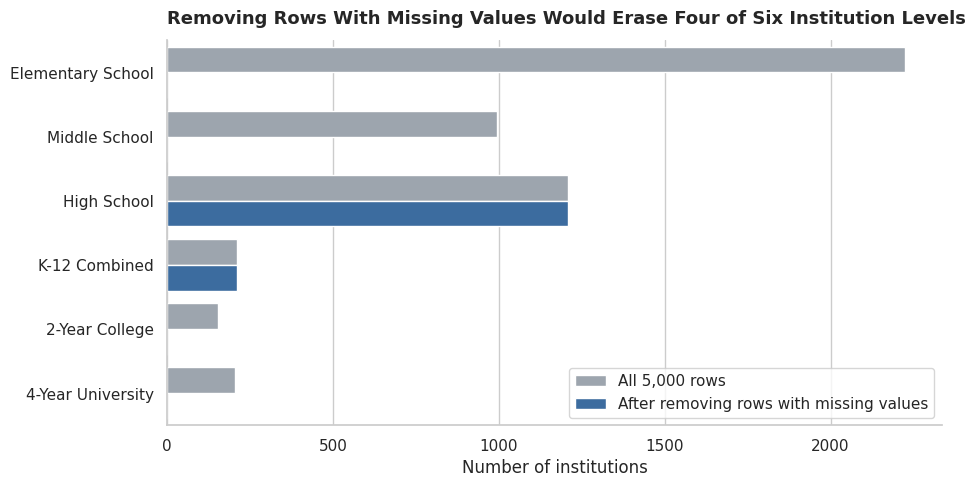

In [34]:
# Let's visualize this
# We will apply Edward Tufte's data-to-ink ratio

plot_data = survivors.reset_index().melt(
    id_vars='level', var_name='dataset', value_name='institutions')
plot_data['dataset'] = plot_data['dataset'].map({'before': 'All 5,000 rows',
                                                 'after_removing_rows': 'After removing rows with missing values'})

plt.figure(figsize =(10, 5))
sns.barplot(data = plot_data, y='level', x='institutions', hue='dataset',
            palette=['#9AA5B1', '#2B6CB0'])

sns.despine()
plt.title('Removing Rows With Missing Values Would Erase Four of Six Institution Levels',
          fontsize=13, fontweight='bold', loc='left', pad=12)
plt.xlabel('Number of institutions')
plt.ylabel('')
plt.legend(title='', loc='lower right')
plt.show();

**Decision on Missing Values**

- **Remove rows:** rejected. It would keep only 1,421 institutions (28.4%), all of them High Schools or K-12 Combined schools. Elementary, Middle and college institutions would disappear, and the question we were asked covers all institutions.

- **Remove the four columns:** rejected for now. It loses information that exists for the 1,421 institutions that have it and could help predict certification at those levels.

- **Impute:** rejected. Filling would invent 13,908 values, for example an SAT score for every elementary school. Zero would be a false score and the average of high schools would be a false score for institutions that do not take the test.

*Decision:*

- Retain the values as missing. No row is removed, no column is removed and nothing is filled in. This follows from the reason the values are missing.

- And add two flag columns,'has_sat_act' and 'has_ap_ib_postsecondary', so later stages can model only the levels where the measures exist or leave them out.

- The modelling stage will decide whether these columns are used at all, because SAT and AP/IB could be consequences of STEM certification and not causes (data leakage).



*Phase 2: Data Validation*

*Here, we will investigate*

- Impossible percentages
- Unusual values
- Duplicate institutions
- Inconsistent categories and outliers
- And check that values suit each institution level.

*Phase 2.1: Impossible Values*

In [35]:
# Create labels to be used for validation

COLLEGE_LEVELS = ["2-Year College", "4-Year University"]
PRIVATE_CONTROLS = ["Private Non-Profit", "Private Religious", "Private For-Profit"]

EXPECTED_LABELS = {
    "level": {"Elementary School", "Middle School", "High School", "K-12 Combined",
              "2-Year College", "4-Year University"},
    "control": {"Public", "Public Charter", "Private Non-Profit", "Private Religious",
                "Private For-Profit"},
    "title_i_status": {"Title I Schoolwide", "Title I Targeted", "Not Title I Eligible",
                       "Not Applicable"},
    "stem_certified_flag": {"Yes", "No"},
}


In [36]:
# We will use a function to create rules for validation and run validation checks

def run_validation_checks(df: pd.DataFrame) -> pd.DataFrame:
    """Return one row per check with the number of rows that break the rule."""
    pct_cols = [c for c in df.columns if c.endswith("_pct")]
    race_cols = [c for c in df.columns if c.startswith("racial_")]
    funding_cols = ["federal_funding_pct", "state_funding_pct", "local_funding_pct"]
    implied_ratio = df["total_enrollment"] / df["number_of_teachers"]
    ratio_gap = (implied_ratio - df["student_teacher_ratio"]).abs() / df["student_teacher_ratio"]
    is_private = df["control"].isin(PRIVATE_CONTROLS)
    is_college = df["level"].isin(COLLEGE_LEVELS)
    not_applicable = df["title_i_status"] == "Not Applicable"

# Rules for validation
    checks = [
        ("Percentages between 0 and 100", "all *_pct columns",
         int(((df[pct_cols] < 0) | (df[pct_cols] > 100)).any(axis=1).sum())),
        ("Race percentages add up to 100", "within 0.15",
         int(((df[race_cols].sum(axis=1) - 100).abs() > 0.15).sum())),
        ("Funding percentages add up to 100", "within 0.15",
         int(((df[funding_cols].sum(axis=1) - 100).abs() > 0.15).sum())),
        ("SAT score in valid range", "400 to 1600 where recorded",
         int(((df["avg_sat_score"] < 400) | (df["avg_sat_score"] > 1600)).sum())),
        ("ACT score in valid range", "1 to 36 where recorded",
         int(((df["avg_act_score"] < 1) | (df["avg_act_score"] > 36)).sum())),
        ("Counts and spending are positive", "enrollment, teachers, spending, ratio > 0",
         int((df[["total_enrollment", "number_of_teachers",
                  "per_pupil_expenditure_usd", "student_teacher_ratio"]] <= 0).any(axis=1).sum())),
        ("Enrollment is at least the number of teachers", "enrollment >= teachers",
         int((df["total_enrollment"] < df["number_of_teachers"]).sum())),
        ("Student-teacher ratio matches enrollment / teachers", "within 10%",
         int((ratio_gap > 0.10).sum())),
        ("Unique institution_id", "no repeated IDs",
         int(df["institution_id"].duplicated().sum())),
        ("No fully duplicated rows", "all columns identical",
         int(df.duplicated().sum())),
        ("Title I 'Not Applicable' only for colleges and private schools", "both directions",
         int((not_applicable != (is_private | is_college)).sum())),
    ]

    for column, allowed in EXPECTED_LABELS.items():
        checks.append((f"Labels in {column} are expected ones", f"{len(allowed)} allowed labels",
                       int((~df[column].isin(allowed)).sum())))
    return pd.DataFrame(checks, columns=["check", "rule", "rows_violating"])




In [37]:
# Run every validity rule at once

validation_report = run_validation_checks(data_copy)
validation_report

,check,rule,rows_violating
0,Percentages between 0 and 100,all *_pct columns,0
1,Race percentages add up to 100,within 0.15,0
2,Funding percentages add up to 100,within 0.15,0
3,SAT score in valid range,400 to 1600 where recorded,0
4,ACT score in valid range,1 to 36 where recorded,0
5,Counts and spending are positive,"enrollment, teachers, spending, ratio > 0",0
6,Enrollment is at least the number of teachers,enrollment >= teachers,0
7,Student-teacher ratio matches enrollment / tea...,within 10%,0
8,Unique institution_id,no repeated IDs,0
9,No fully duplicated rows,all columns identical,0


**Impossible Values**

- All 15 checks pass with zero violations. No percentage is outside 0 to 100, race and funding shares add up to 100, SAT and ACT scores are within their real scales, counts and spending are positive, and the student-teacher ratio agrees with enrollment divided by teachers.

- Title I "Not Applicable" appears for exactly the colleges and the private K-12 schools, with no exceptions in either direction.

- Because nothing impossible was found, nothing needs correcting.

In [38]:
# do SAT and ACT move together?
# We will use a correlation to test for this

sat_act_corr = (data_copy.dropna(subset=['avg_sat_score', 'avg_act_score'])
                .groupby('level')[['avg_sat_score', 'avg_act_score']]
                .apply(lambda g: g['avg_sat_score'].corr(g['avg_act_score'])).round(2))
sat_act_corr

,0
level,
4-Year University,0.60
High School,0.76
K-12 Combined,0.78


- SAT and ACT are strongly related (0.60 to 0.78) at every level where both are recorded, which is what we would expect from real test scores.

*Phase 2.2: Unusual values*

In [39]:
# To check for unsual values, we will
# Count how many rows equal the column's minimum or maximum

limit_checks = {'per_pupil_expenditure_usd': 'min', 'student_teacher_ratio': 'min',
                'graduation_rate_pct': 'max', 'math_proficiency_pct': 'max',
                'reading_proficiency_pct': 'max', 'broadband_access_pct': 'max'}

pileups = []
for column, side in limit_checks.items():
    limit = data_copy[column].min() if side == 'min' else data_copy[column].max()
    count = int((data_copy[column] == limit).sum())
    pileups.append((column, side, limit, count, round(count / len(data_copy) * 100, 1)))

pd.DataFrame(pileups, columns=['column', 'limit_type', 'limit_value', 'rows_at_limit', 'percent_of_rows'])

,column,limit_type,limit_value,rows_at_limit,percent_of_rows
0,per_pupil_expenditure_usd,min,7500.0,34,0.7
1,student_teacher_ratio,min,6.0,7,0.1
2,graduation_rate_pct,max,99.5,49,1.0
3,math_proficiency_pct,max,96.0,84,1.7
4,reading_proficiency_pct,max,98.0,121,2.4
5,broadband_access_pct,max,99.0,223,4.5


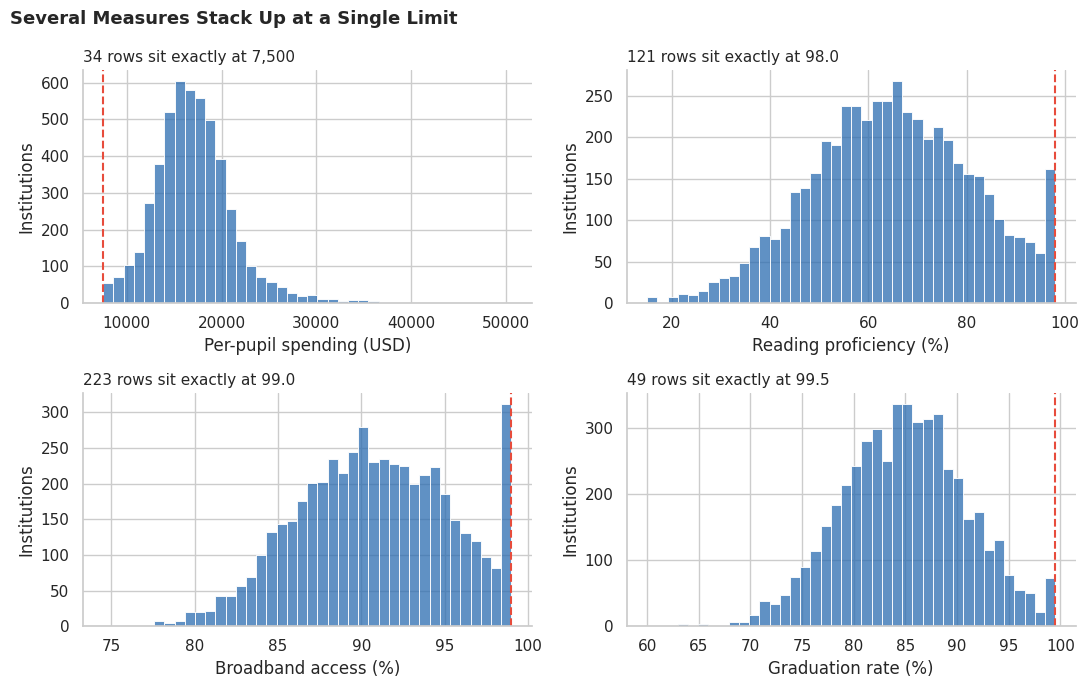

In [40]:
# Let's visualize the four clearest cases

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
panels = [('per_pupil_expenditure_usd', 'Per-pupil spending (USD)'),
          ('reading_proficiency_pct', 'Reading proficiency (%)'),
          ('broadband_access_pct', 'Broadband access (%)'),
          ('graduation_rate_pct', 'Graduation rate (%)')]

for ax, (column, label) in zip(axes.ravel(), panels):
    sns.histplot(data_copy[column], bins=40, color='#2B6CB0', ax=ax)
    limit = data_copy[column].min() if column == 'per_pupil_expenditure_usd' else data_copy[column].max()
    count = int((data_copy[column] == limit).sum())
    ax.axvline(limit, color='#E74C3C', linestyle='--')
    ax.set_title(f"{count} rows sit exactly at {limit:,}", fontsize=11, loc='left')
    ax.set_xlabel(label)
    ax.set_ylabel('Institutions')
    sns.despine(ax=ax)

fig.suptitle('Several Measures Stack Up at a Single Limit', fontsize=13, fontweight='bold', x=0.01, ha='left')
plt.tight_layout()
plt.show();

**Business Translation: Unusual Values**

- Broadband access has 223 institutions (4.5%) at exactly 99, reading proficiency has 121 (2.4%) at 98, graduation rate has 49 (1.0%) at 99.5 and per-pupil spending has 34 (0.7%) at exactly $7,500.

- Natural data spreads out near its extremes and does not pile up at one value, so these look like values that were capped or floored when the data were produced or recorded.

*Decision:*
- Retain them. They are valid numbers, and the share of affected rows is small. We note that the true top values of these measures are not visible, so differences near the limits should not be over-interpreted.

In [41]:
# Let's take a look at Control, funding
# Group the dataset by 'control' ownership and find the average funding sources

funding_by_control = (data_copy.groupby('control')[['federal_funding_pct',
                                                       'state_funding_pct',
                                                       'local_funding_pct']].mean().round(2))
funding_by_control

,federal_funding_pct,state_funding_pct,local_funding_pct
control,,,
Private For-Profit,14.57,45.51,39.91
Private Non-Profit,0.00,2.00,98.00
Private Religious,0.00,2.00,98.00
Public,14.17,45.43,40.40
Public Charter,13.87,45.68,40.46


In [42]:
# Two structural patterns spotted while looking at funding data
# The patterns are visible in Private Non-Profit and Private Religious

is_private_np_rel = data_copy['control'].isin(['Private Non-Profit', 'Private Religious'])

print("Funding mix of Private Non-Profit and Private Religious institutions:")
print(data_copy[is_private_np_rel][['federal_funding_pct', 'state_funding_pct', 'local_funding_pct']]
      .drop_duplicates().to_string(index=False))
print(f"\nRows with these owners: {is_private_np_rel.sum()}")
print(f"Rows with 0% federal funding: {(data_copy['federal_funding_pct'] == 0).sum()}")
print(f"Rows with 0% federal funding that are NOT these owners: "
      f"{((data_copy['federal_funding_pct'] == 0) & ~is_private_np_rel).sum()}")


Funding mix of Private Non-Profit and Private Religious institutions:
 federal_funding_pct  state_funding_pct  local_funding_pct
                 0.0                2.0               98.0

Rows with these owners: 755
Rows with 0% federal funding: 755
Rows with 0% federal funding that are NOT these owners: 0


In [43]:
# Let's take a look at level groups and lunch

is_college = data_copy['level'].isin(COLLEGE_LEVELS)
print("\nFree/reduced lunch among colleges and universities:")
print(f"  rows at 0%: {((data_copy['percent_free_reduced_lunch'] == 0) & is_college).sum()} of {is_college.sum()}")
print(f"  rows at 0% among K-12 schools: {((data_copy['percent_free_reduced_lunch'] == 0) & ~is_college).sum()} of {(~is_college).sum()}")


Free/reduced lunch among colleges and universities:
  rows at 0%: 258 of 358
  rows at 0% among K-12 schools: 32 of 4642


**Business Translation: Two Structural Patterns**

- **Funding mix:** all 755 Private Non-Profit and Private Religious institutions have the identical split of 0% federal, 2% state and 98% local funding, and no other institution has 0% federal funding.

- For these institutions the three funding-share columns carry no information beyond "this is a private non-profit or religious school", which control already says.

- The funding mix can only tell us something about the other 4,245 institutions.

- **Free/reduced lunch:** 258 of the 358 colleges and universities are recorded at 0%, versus 32 of 4,642 K-12 schools. This programme is a K-12 measure, so for colleges it is effectively "not applicable" recorded as a small number or zero.

*Decision for both:*
-  Retain, no change. These are not errors, but they are limits on what the columns can tell us, and the EDA and modelling stages should read these columns within K-12 schools.

*Phase 2.3: Duplicates*

In [44]:
# We will look at the dataset for exact duplicates and repeated IDs

print("Fully duplicated rows:", data_copy.duplicated().sum())
print("Repeated institution_id:", data_copy['institution_id'].duplicated().sum())
print(f"Unique institution names: {data_copy['institution_name'].nunique()} of {len(data_copy):,}")


Fully duplicated rows: 0
Repeated institution_id: 0
Unique institution names: 780 of 5,000


In [45]:
# Names repeat.
# Could repeated names with the same state, county and level be the same institution entered twice?

dup_key = ['institution_name', 'state_code', 'county', 'level']
same_place = data_copy[data_copy.duplicated(dup_key, keep=False)].sort_values(dup_key)

print(f"\nGroups sharing name, state, county and level: {same_place.groupby(dup_key).ngroups} ({len(same_place)} rows)")


Groups sharing name, state, county and level: 112 (229 rows)


In [46]:
# For each such group, count how many of the other columns match exactly

compare_cols = [c for c in data_copy.columns if c != 'institution_id']

def matching_columns(group):
    first, second = group.iloc[0], group.iloc[1]
    return sum((first[c] == second[c]) or (pd.isna(first[c]) and pd.isna(second[c])) for c in compare_cols)

matches = pd.Series({key: matching_columns(group) for key, group in same_place.groupby(dup_key)})
print(f"Columns compared: {len(compare_cols)}")
print(matches.describe().round(1))
print(f"\nMost similar pair matches on {matches.max()} of {len(compare_cols)} columns")

Columns compared: 35
count    112.0
mean      11.3
std        2.1
min        5.0
25%       11.0
50%       12.0
75%       13.0
max       16.0
dtype: float64

Most similar pair matches on 16 of 35 columns


In [47]:
# Look at the most similar group in full

closest = matches.idxmax()
same_place[(same_place[dup_key] == pd.Series(closest, index = dup_key)).all(axis=1)][
    ['institution_id', 'nces_locale', 'control', 'total_enrollment', 'number_of_teachers',
     'per_pupil_expenditure_usd', 'math_proficiency_pct', 'stem_certified_flag']]

,institution_id,nces_locale,control,total_enrollment,number_of_teachers,per_pupil_expenditure_usd,math_proficiency_pct,stem_certified_flag
325,US-EDU-10326,Suburban - Midsize,Private Non-Profit,568,40,22343,77.5,No
1053,US-EDU-11054,Town - Distant,Private Non-Profit,228,19,23749,71.3,No


**Business Translation: Duplicates**

- There are no repeated IDs and no fully duplicated rows. Names repeat a lot (780 unique names for 5,000 rows), which is expected for generic school names.

- 112 groups share name, state, county and level. Even the most similar pair matches on only 16 of 35 columns, and those matches are the name and location fields, locale, ownership, Title I status, the fixed private funding mix and shared blanks.

*Decision:*

- Retain all rows. No institution is removed as a duplicate.

*Phase 2.4: Inconsistent Categories*

In [48]:
# Here, we will check
# if each state code paired with exactly one state name, and vice versa?

print("One state name per state code:", data_copy.groupby('state_code')['state_name'].nunique().max() == 1)
print("One state code per state name:", data_copy.groupby('state_name')['state_code'].nunique().max() == 1)
print("Number of states:", data_copy['state_code'].nunique())

# Do labels in categorical columns match the expected sets?

print("\nLevels:", sorted(data_copy['level'].unique()))

One state name per state code: True
One state code per state name: True
Number of states: 51

Levels: ['2-Year College', '4-Year University', 'Elementary School', 'High School', 'K-12 Combined', 'Middle School']


In [49]:
# Cross-field consistency:
# here, we will compare ownership against Title I status

pd.crosstab(data_copy['control'], data_copy['title_i_status'])

title_i_status,Not Applicable,Not Title I Eligible,Title I Schoolwide,Title I Targeted
control,,,,
Private For-Profit,121,0,0,0
Private Non-Profit,499,0,0,0
Private Religious,256,0,0,0
Public,232,654,1858,803
Public Charter,0,113,322,142


**Business Translation: Categories**

- State codes and state names pair one-to-one across 51 states.

- Title I status is consistent with ownership: every private institution is "Not Applicable", and public and charter K-12 schools hold the three real Title I categories (the 232 "Not Applicable" public rows are the public colleges). "Not Applicable" is a genuine category and not a missing value, so it is kept as it is.

*Phase 2.5: Outliers*

In [50]:
# Here we apply the IQR rule WITHIN each institution level

def iqr_flags(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)

outlier_cols = ['total_enrollment', 'number_of_teachers', 'per_pupil_expenditure_usd',
                'student_teacher_ratio', 'percent_free_reduced_lunch']

outlier_summary = pd.DataFrame({
    'all_levels_together': [int(iqr_flags(data_copy[c]).sum()) for c in outlier_cols],
    'within_level': [int(data_copy.groupby('level')[c].apply(lambda s: iqr_flags(s).sum()).sum())
                     for c in outlier_cols],
}, index=outlier_cols)
outlier_summary

,all_levels_together,within_level
total_enrollment,480,17
number_of_teachers,486,131
per_pupil_expenditure_usd,152,100
student_teacher_ratio,28,23
percent_free_reduced_lunch,0,50


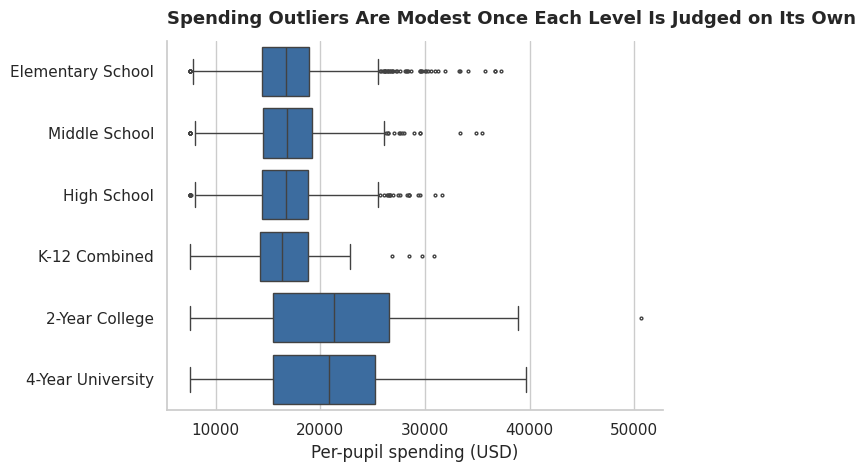

In [51]:
# Let's visualize this

sns.boxplot(data = data_copy, y='level', x='per_pupil_expenditure_usd', order = level_order,
            color='#2B6CB0', fliersize=2)
sns.despine()

plt.title('Spending Outliers Are Modest Once Each Level Is Judged on Its Own',
          fontsize=13, fontweight='bold', loc='left', pad=12)
plt.xlabel('Per-pupil spending (USD)')
plt.ylabel('')
plt.show();


In [52]:
# The most extreme spending values, to check they are plausible

data_copy.nlargest(5, 'per_pupil_expenditure_usd')[['institution_name', 'level', 'control', 'total_enrollment',
                                                    'per_pupil_expenditure_usd']]

,institution_name,level,control,total_enrollment,per_pupil_expenditure_usd
1274,Pine Crest State College,2-Year College,Public,4817,50601
3527,State University - Southland,4-Year University,Public,6038,39632
2851,Franklin Junior College,2-Year College,Private For-Profit,5832,38934
4023,Jefferson Junior College,2-Year College,Public,4383,37924
1868,Marshall Primary School,Elementary School,Private Non-Profit,482,37235


**Business Translation: Outliers**

- Judged all together, enrollment has 480 outliers and teacher counts 486.

- Judged within each level, these fall to 17 and 131. Most of the earlier "outliers" were simply colleges and universities being larger than schools, which is normal.

- *The extreme spending values are plausible:* the highest is a public 2-Year College at 50,601 USD per student, and the highest K-12 value is 37,235 USD, which is high but possible for a small private school.

- Free/reduced lunch shows 50 within-level outliers, all among colleges, where nearly every value is 0 and a few higher values stand out. This is the K-12 measure issue noted in phase 2.2.

*Decision:*

- Retain all outliers. None are impossible, deleting them would remove real institutions, and a one-off decision on each would be arbitrary.

- If a model is sensitive to extreme values, we will handle it there with scaling or a transformation, not by deleting rows.

In [53]:
# Let's take a look at Graduation rate across levels

level_check = data_copy.groupby('level').agg(
    median_enrollment=('total_enrollment', 'median'),
    graduation_rate_mean=('graduation_rate_pct', 'mean'),
    graduation_rate_min=('graduation_rate_pct', 'min'),
    graduation_rate_max=('graduation_rate_pct', 'max'),
).round(1).reindex(level_order)

level_check

,median_enrollment,graduation_rate_mean,graduation_rate_min,graduation_rate_max
level,,,,
Elementary School,476.0,84.7,62.0,99.5
Middle School,645.0,84.9,63.2,99.5
High School,1098.0,84.4,63.9,99.5
K-12 Combined,413.5,84.4,60.0,99.5
2-Year College,5556.0,89.6,77.2,99.5
4-Year University,12625.5,88.3,74.5,99.5


**Business Translation: Level Appropriateness**

- Enrollment fits each level: elementary schools have a median of about 476 students, high schools about 1,100, 2-Year Colleges about 5,600 and 4-Year Universities about 12,600.

- **Graduation rate** looks the same at every level (about 84% to 90%), including for elementary and middle schools where students do not graduate. It is not clear what it measures below high school.

* Decision:*
- Retain, but treat it with caution and do not compare it across levels until its meaning is confirmed.

In [54]:
# We will now proceed to clean the data set with the cleaning rules
# we will use a function for this

def clean_education_data(df: pd.DataFrame) -> pd.DataFrame:
    """Apply the cleaning rules decided and return a new DataFrame."""
    cleaned = df.copy()

    # 1. Standardise text: remove stray spaces from every non-numeric column
    text_cols = [c for c in cleaned.columns if not pd.api.types.is_numeric_dtype(cleaned[c])]
    for column in text_cols:
        cleaned[column] = cleaned[column].str.strip()

    # 2. Stop if any impossible value is present
    report = run_validation_checks(cleaned)
    failed = report[report["rows_violating"] > 0]
    if not failed.empty:
        raise ValueError(f"Validation failed:\n{failed.to_string(index=False)}")

    # 3. Helper columns (no existing value is changed)
    cleaned["is_certified"] = (cleaned["stem_certified_flag"] == "Yes").astype(int)
    cleaned["institution_group"] = np.where(cleaned["level"].isin(COLLEGE_LEVELS),
                                        "College or university", "K-12 school")
    cleaned["readiness_coverage"] = np.select(
        [cleaned["ap_ib_participation_pct"].notna(), cleaned["avg_sat_score"].notna()],
        ["SAT/ACT + AP/IB + postsecondary", "SAT/ACT only"],
        default="None recorded",
    )
    return cleaned

In [55]:
# Applying the cleaning function to the dataset

cleaned_data = clean_education_data(data_copy)
cleaned_data.head()

,institution_id,institution_name,state_code,state_name,county,nces_locale,level,control,title_i_status,total_enrollment,number_of_teachers,student_teacher_ratio,percent_free_reduced_lunch,racial_white_pct,racial_black_pct,racial_hispanic_pct,racial_asian_pct,racial_native_pct,racial_two_or_more_pct,special_education_pct,english_learner_pct,per_pupil_expenditure_usd,federal_funding_pct,state_funding_pct,local_funding_pct,math_proficiency_pct,reading_proficiency_pct,graduation_rate_pct,chronic_absenteeism_pct,avg_sat_score,avg_act_score,ap_ib_participation_pct,postsecondary_enrollment_pct,stem_certified_flag,broadband_access_pct,is_certified,institution_group,readiness_coverage
0,US-EDU-10001,Jefferson Elementary School,MA,Massachusetts,Central County,Suburban - Midsize,Elementary School,Public,Title I Schoolwide,447,30,14.8,48.9,70.9,2.4,15.4,8.1,0.1,3.1,14.4,12.9,12840,15.0,54.8,30.2,58.3,58.1,80.9,18.0,NaN,NaN,NaN,NaN,No,91.6,0,K-12 school,None recorded
1,US-EDU-10002,Lakeshore Middle School,FL,Florida,Miami-Dade County,Suburban - Midsize,Middle School,Private Religious,Not Applicable,293,29,10.0,1.2,34.7,8.6,36.1,13.3,1.3,6.0,13.7,19.3,17009,0.0,2.0,98.0,84.8,98.0,93.5,17.8,NaN,NaN,NaN,NaN,No,94.4,0,K-12 school,None recorded
2,US-EDU-10003,Meadowbrook Elementary Academy,TX,Texas,Bexar County,City - Large,Elementary School,Private For-Profit,Not Applicable,315,17,18.2,36.0,26.2,29.2,22.9,12.3,1.9,7.5,15.7,11.3,15374,10.7,55.5,33.8,54.6,66.2,80.2,19.5,NaN,NaN,NaN,NaN,No,94.0,0,K-12 school,None recorded
3,US-EDU-10004,Roosevelt Primary School,FL,Florida,Palm Beach County,Suburban - Large,Elementary School,Public,Not Title I Eligible,389,34,11.3,15.1,49.2,16.7,4.3,26.4,0.1,3.3,13.8,9.8,17065,6.8,38.3,54.9,66.1,70.5,82.1,20.5,NaN,NaN,NaN,NaN,No,96.4,0,K-12 school,None recorded
4,US-EDU-10005,Highland Park Primary School,MI,Michigan,Macomb County,Suburban - Large,Elementary School,Public,Title I Targeted,397,29,13.9,45.6,78.1,3.2,8.0,3.9,2.1,4.7,19.8,5.3,16823,15.0,42.3,42.7,54.6,46.7,90.2,19.9,NaN,NaN,NaN,NaN,No,86.3,0,K-12 school,None recorded


In [56]:
# Check 1:
# No existing value was changed
print("All original columns identical to the raw data:", data_copy.equals(cleaned_data[data_copy.columns]))

# Check 2:
# Missing values are exactly as before (retained, not filled)
print("Missing values per column unchanged:",
      (data_copy.isnull().sum() == cleaned_data[data_copy.columns].isnull().sum()).all())

# Check 3:
# The validation checks still pass on the cleaned data
print("Validation violations in cleaned data:", int(run_validation_checks(cleaned_data)['rows_violating'].sum()))

All original columns identical to the raw data: True
Missing values per column unchanged: True
Validation violations in cleaned data: 0


In [57]:
# let's ook at what the three helper columns record

print(cleaned_data['institution_group'].value_counts(), "\n")
print(cleaned_data['readiness_coverage'].value_counts(), "\n")
print(cleaned_data.groupby('institution_group')['is_certified'].agg(['count', 'sum', 'mean']).round(3))

institution_group
K-12 school              4642
College or university     358
Name: count, dtype: int64 

readiness_coverage
None recorded                      3375
SAT/ACT + AP/IB + postsecondary    1421
SAT/ACT only                        204
Name: count, dtype: int64 

                       count  sum   mean
institution_group                       
College or university    358   63  0.176
K-12 school             4642  689  0.148


In [58]:
cleaning_log = pd.DataFrame([
 ('Missing SAT/ACT (3,375 rows) and AP/IB/postsecondary (3,579 rows)',
  'Missing exactly by institution level (0% or 100% per level)',
  'Retain as missing',
  'Measure does not apply to those levels; removing rows leaves 28.4% of data and 2 of 6 levels; imputing invents 13,908 values',
  0),
 ('No impossible values',
  '15 validity checks, 0 violations',
  'No correction needed; checks run inside the cleaning function',
  'Nothing to fix; rules protect future reruns',
  0),
 ('Values stacked at a limit (broadband 99, reading 98, graduation 99.5, spending $7,500)',
  '0.7% to 4.5% of rows per column',
  'Retain',
  'Valid numbers, small share; note that true extremes are not visible',
  0),
 ('Identical funding mix for private non-profit and religious institutions',
  '755 rows all 0 / 2 / 98 percent',
  'Retain',
  'Not an error, but the funding shares carry no extra information for these owners; interpret within the other 4,245',
  0),
 ('Free/reduced lunch near zero for colleges',
  '258 of 358 college rows at 0%',
  'Retain',
  'K-12 programme measure; read within K-12 schools',
  0),
 ('Repeated names',
  '112 groups share name, state, county and level; best match is 15 of 34 columns',
  'Retain all rows',
  'Different institutions with generic names, not repeated records',
  0),
 ('Category labels',
  'No stray spaces or variants; Title I consistent with ownership',
  'Standardise spacing (no changes needed); keep "Not Applicable" as its own category',
  'Genuine category, not a missing value',
  0),
 ('Outliers',
  'Within-level counts far below all-levels-together counts',
  'Retain',
  'Plausible values; most were colleges being larger; handle in modelling by scaling, not deletion',
  0),
 ('Graduation rate present for every level',
  'About 84% to 90% mean at all levels, including elementary and middle',
  'Retain with caution',
  'Meaning below high school is unclear; confirm with data owner',
  0),
 ('Need to separate colleges from K-12 and to see which measures exist',
  '358 colleges; 3 coverage patterns',
  'Add helper columns: institution_group, readiness_coverage',
  'Make later subsetting simple without changing any original value',
  0),
 ('Target needs a numeric form for later analysis',
  'stem_certified_flag is Yes/No text',
  'Add is_certified (1 = Yes, 0 = No)',
  'Original column kept; the new column simplifies modelling',
  0),
], columns=['issue', 'evidence', 'decision', 'justification', 'rows_removed'])

cleaning_log.to_csv('/content/drive/MyDrive/AltSchool_Africa/4th_Semester/cleaning_log.csv', index = False)
cleaning_log[['issue', 'decision']]

,issue,decision
0,"Missing SAT/ACT (3,375 rows) and AP/IB/postsec...",Retain as missing
1,No impossible values,No correction needed; checks run inside the cl...
2,"Values stacked at a limit (broadband 99, readi...",Retain
3,Identical funding mix for private non-profit a...,Retain
4,Free/reduced lunch near zero for colleges,Retain
5,Repeated names,Retain all rows
6,Category labels,Standardise spacing (no changes needed); keep ...
7,Outliers,Retain
8,Graduation rate present for every level,Retain with caution
9,Need to separate colleges from K-12 and to see...,"Add helper columns: institution_group, readine..."


**What was found:**

- The dataset was already largely clean: no impossible values, no repeated records and no inconsistent labels. The real cleaning work was deciding how to treat missing values and unusual patterns, and each decision is recorded in a cleaning log.

- The missing values are structural (the measure does not apply), so they are kept missing instead of removing or inventing them.

- No rows were removed and no existing value was changed. We added three helper columns: 'is_certified', 'institution_group' and 'readiness_coverage'.


**Assumptions and system limitations:**

- We assume the numeric values are accurate as recorded, since no checks can confirm them against the source.

- Because the values pile up at limits and the funding mix is identical for private non-profit and religious institutions, some columns carry less information than their names suggest.

- Whether to keep colleges and universities in the model, and whether to use the readiness measures (SAT, ACT, AP/IB, postsecondary) at all, are decisions for the exploratory and modelling stages.

**Exploratory Data Analysis (EDA)**

*Here, we will:*

- Explore the cleaned data to see how single variables behave (univariate).

- How pairs of variables relate (bivariate)

- And whether the relationships survive when a third factor is taken into account (multivariate).

- Look in particular at how STEM certification relates to the other characteristics, because that tells us what a prediction model can realistically achieve.

In [59]:
cleaned_data.head()

,institution_id,institution_name,state_code,state_name,county,nces_locale,level,control,title_i_status,total_enrollment,number_of_teachers,student_teacher_ratio,percent_free_reduced_lunch,racial_white_pct,racial_black_pct,racial_hispanic_pct,racial_asian_pct,racial_native_pct,racial_two_or_more_pct,special_education_pct,english_learner_pct,per_pupil_expenditure_usd,federal_funding_pct,state_funding_pct,local_funding_pct,math_proficiency_pct,reading_proficiency_pct,graduation_rate_pct,chronic_absenteeism_pct,avg_sat_score,avg_act_score,ap_ib_participation_pct,postsecondary_enrollment_pct,stem_certified_flag,broadband_access_pct,is_certified,institution_group,readiness_coverage
0,US-EDU-10001,Jefferson Elementary School,MA,Massachusetts,Central County,Suburban - Midsize,Elementary School,Public,Title I Schoolwide,447,30,14.8,48.9,70.9,2.4,15.4,8.1,0.1,3.1,14.4,12.9,12840,15.0,54.8,30.2,58.3,58.1,80.9,18.0,NaN,NaN,NaN,NaN,No,91.6,0,K-12 school,None recorded
1,US-EDU-10002,Lakeshore Middle School,FL,Florida,Miami-Dade County,Suburban - Midsize,Middle School,Private Religious,Not Applicable,293,29,10.0,1.2,34.7,8.6,36.1,13.3,1.3,6.0,13.7,19.3,17009,0.0,2.0,98.0,84.8,98.0,93.5,17.8,NaN,NaN,NaN,NaN,No,94.4,0,K-12 school,None recorded
2,US-EDU-10003,Meadowbrook Elementary Academy,TX,Texas,Bexar County,City - Large,Elementary School,Private For-Profit,Not Applicable,315,17,18.2,36.0,26.2,29.2,22.9,12.3,1.9,7.5,15.7,11.3,15374,10.7,55.5,33.8,54.6,66.2,80.2,19.5,NaN,NaN,NaN,NaN,No,94.0,0,K-12 school,None recorded
3,US-EDU-10004,Roosevelt Primary School,FL,Florida,Palm Beach County,Suburban - Large,Elementary School,Public,Not Title I Eligible,389,34,11.3,15.1,49.2,16.7,4.3,26.4,0.1,3.3,13.8,9.8,17065,6.8,38.3,54.9,66.1,70.5,82.1,20.5,NaN,NaN,NaN,NaN,No,96.4,0,K-12 school,None recorded
4,US-EDU-10005,Highland Park Primary School,MI,Michigan,Macomb County,Suburban - Large,Elementary School,Public,Title I Targeted,397,29,13.9,45.6,78.1,3.2,8.0,3.9,2.1,4.7,19.8,5.3,16823,15.0,42.3,42.7,54.6,46.7,90.2,19.9,NaN,NaN,NaN,NaN,No,86.3,0,K-12 school,None recorded


*Phase 1: Univariate Analysis:*

- Here, we will understand how each variable(*enrollment, student-teacher ratio, expenditure, broadband access, math proficiency, reading proficiency, graduation rate and absenteeism*) is distributed on its own.

-  We will also look at the three main categories(school level, ownership and Title I status).

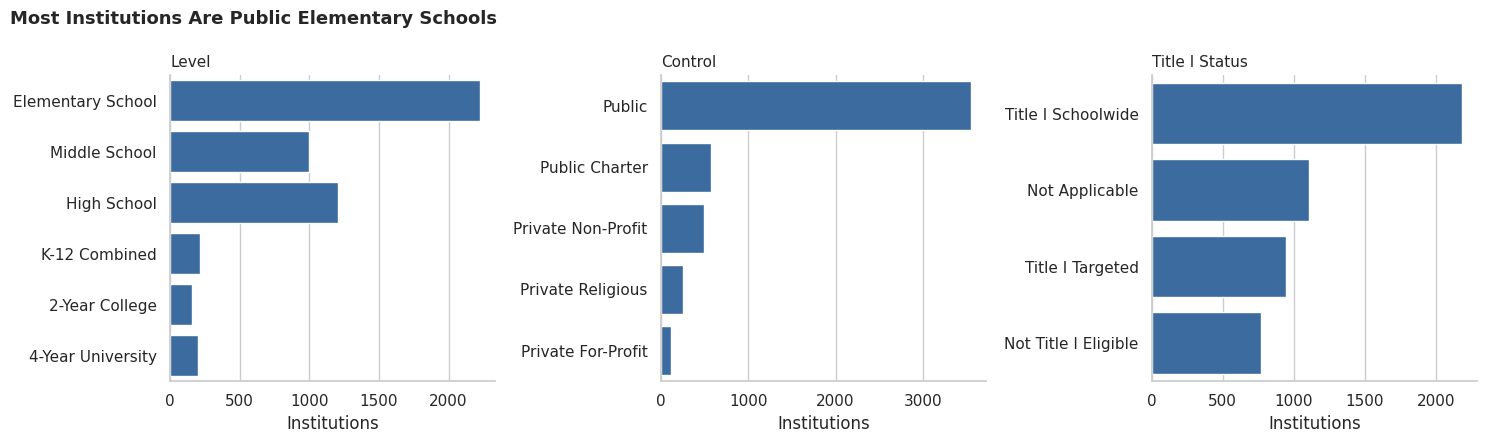

In [60]:
# Visualize the main categories:
# school level, ownership and Title I status

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, column, order in [(axes[0], 'level', level_order),
                          (axes[1], 'control', cleaned_data['control'].value_counts().index),
                          (axes[2], 'title_i_status', cleaned_data['title_i_status'].value_counts().index)]:
    sns.countplot(data = cleaned_data, y = column, order = order, color = '#2B6CB0', ax=ax)
    ax.set_xlabel('Institutions')
    ax.set_ylabel('')
    ax.set_title(column.replace('_', ' ').title(), fontsize=11, loc='left')
    sns.despine(ax=ax)

fig.suptitle('Most Institutions Are Public Elementary Schools', fontsize=13, fontweight='bold', x=0.01, ha='left')
plt.tight_layout()
save_fig('01_categories')
plt.show();

In [61]:
# Numerical Variables of interest for univariate analysis
uni_cols = ['total_enrollment', 'student_teacher_ratio', 'per_pupil_expenditure_usd',
            'broadband_access_pct','math_proficiency_pct', 'reading_proficiency_pct',
            'graduation_rate_pct', 'chronic_absenteeism_pct']

uni_summary = cleaned_data[uni_cols].describe().T[['mean', '50%', 'std', 'min', 'max']].round(1)
k12 = cleaned_data[cleaned_data['institution_group'] == 'K-12 school']

uni_summary.columns = ['mean', 'median', 'std', 'min', 'max']
uni_summary['skew_all'] = cleaned_data[uni_cols].skew().round(2)
uni_summary['skew_k12'] = k12[uni_cols].skew().round(2)
uni_summary

,mean,median,std,min,max,skew_all,skew_k12
total_enrollment,1375.9,603.0,3416.6,80.0,45252.0,6.42,1.40
student_teacher_ratio,14.9,14.9,3.3,6.0,30.0,0.16,0.10
per_pupil_expenditure_usd,17113.4,16830.5,4207.7,7500.0,50601.0,0.96,0.55
broadband_access_pct,90.8,90.8,4.6,74.5,99.0,-0.13,-0.09
math_proficiency_pct,60.0,60.1,16.5,12.0,96.0,-0.03,-0.03
reading_proficiency_pct,64.8,64.8,16.4,15.0,98.0,-0.07,-0.06
graduation_rate_pct,84.9,85.0,6.0,60.0,99.5,-0.06,-0.06
chronic_absenteeism_pct,20.0,20.0,5.9,4.0,40.2,-0.02,-0.02


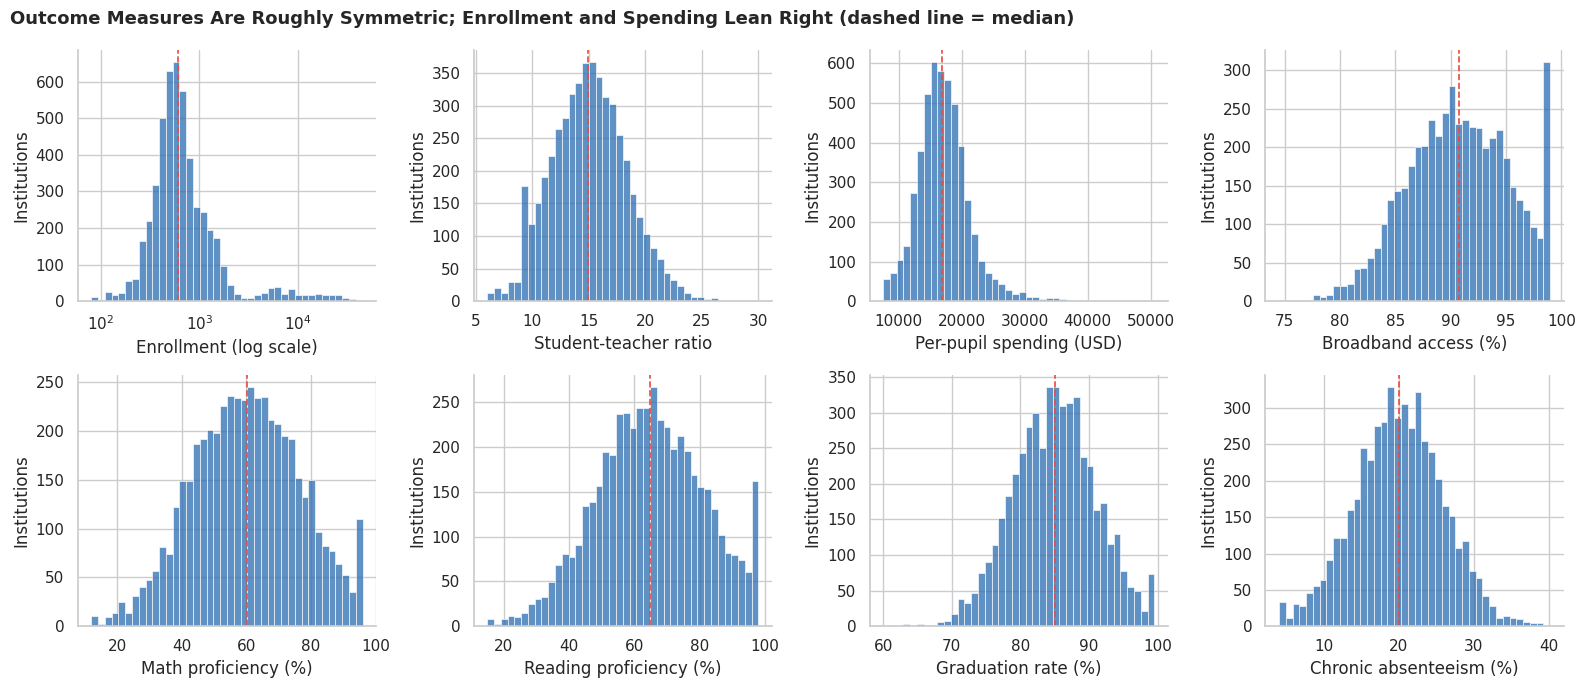

In [62]:
# Let's visualize the distributions

fig, axes = plt.subplots(2, 4, figsize=(16, 7))

labels = {'total_enrollment': 'Enrollment (log scale)', 'student_teacher_ratio': 'Student-teacher ratio',
          'per_pupil_expenditure_usd': 'Per-pupil spending (USD)', 'broadband_access_pct': 'Broadband access (%)',
          'math_proficiency_pct': 'Math proficiency (%)', 'reading_proficiency_pct': 'Reading proficiency (%)',
          'graduation_rate_pct': 'Graduation rate (%)', 'chronic_absenteeism_pct': 'Chronic absenteeism (%)'}

for ax, column in zip(axes.ravel(), uni_cols):
    sns.histplot(cleaned_data[column], bins=40, color ='#2B6CB0', ax=ax, log_scale=(column == 'total_enrollment'))
    ax.axvline(cleaned_data[column].median(), color = '#E74C3C', linestyle='--', linewidth=1.2)
    ax.set_xlabel(labels[column])
    ax.set_ylabel('Institutions')
    sns.despine(ax=ax)

fig.suptitle('Outcome Measures Are Roughly Symmetric; Enrollment and Spending Lean Right (dashed line = median)',
             fontsize=13, fontweight='bold', x=0.01, ha='left')
plt.tight_layout()
save_fig('02_univariate')
plt.show();

**Univariate Findings**

- **Enrollment** is heavily right-skewed (skew 6.4) because a few large universities sit among many small schools. Among K-12 schools alone the skew falls to 1.4, so enrollment is best viewed on a log scale or within a level.

- **Per-pupil spending** leans right (skew 1.0; 0.6 for K-12) with a long tail of high-spending institutions, mostly colleges. The typical institution spends about 16,800 USD per student.

- **Student-teacher ratio** is close to symmetric around 15 students per teacher.

- **Broadband access** is high (median 90.8%) and bunches against its cap at 99%, as noted in notebook 02.

- **Math proficiency** (mean 60.0%), **reading proficiency** (mean 64.8%), **graduation rate** (mean 84.9%) and **chronic absenteeism** (mean 20.0%) are all close to symmetric, so means and medians tell the same story and ordinary correlations are reasonable to use. The small spikes at the top end of math, reading, graduation and broadband are capped values.

*Phase 2: Bivariate Analysis*

- Now, we look at pairs of variables.

- For Outcome questions, we will use the 4,642 K-12 schools and Spearman's Correlation, which measures how consistently two variables rise or fall together and is not affected by outliers.

- A value near 0 means little relationship, and values beyond about 0.3 in either direction are worth paying attention to.

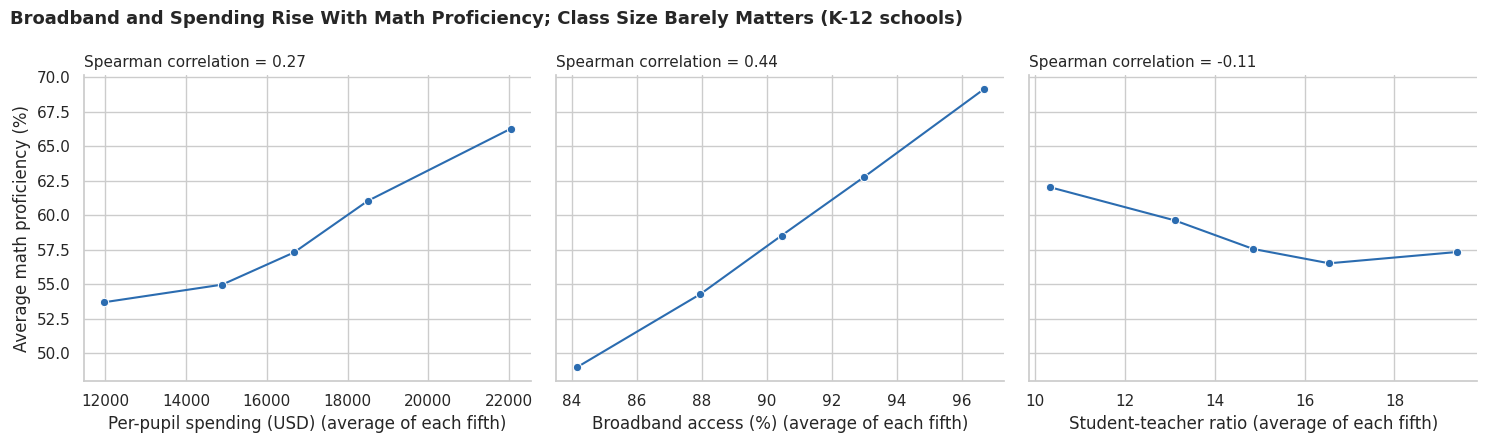

In [63]:
# We will compare Funding, broadban, and staffing
# Versus Academic performance.

# We will make use of bins for this,
# by splitting each driver into five equal sized groups
# and compare the average math proficiency

drivers = {'per_pupil_expenditure_usd': 'Per-pupil spending (USD)',
           'broadband_access_pct': 'Broadband access (%)',
           'student_teacher_ratio': 'Student-teacher ratio'}

fig, axes = plt.subplots(1, 3, figsize = (15, 4.5), sharey = True)
for ax, (column, label) in zip(axes, drivers.items()):
    groups = pd.qcut(k12[column], 5, duplicates='drop')
    binned = k12.groupby(groups, observed=True).agg(x=(column, 'mean'), math =('math_proficiency_pct', 'mean'))
    rho = k12[column].corr(k12['math_proficiency_pct'], method='spearman')
    sns.lineplot(data = binned, x ='x', y ='math', marker ='o', color ='#2B6CB0', ax=ax)
    ax.set_title(f"Spearman correlation = {rho:.2f}", fontsize=11, loc='left')
    ax.set_xlabel(label + ' (average of each fifth)')
    ax.set_ylabel('Average math proficiency (%)')
    sns.despine(ax=ax)

fig.suptitle('Broadband and Spending Rise With Math Proficiency; Class Size Barely Matters (K-12 schools)',
             fontsize=13, fontweight='bold', x=0.01, ha='left')
plt.tight_layout()
save_fig('03_drivers_vs_math')
plt.show();

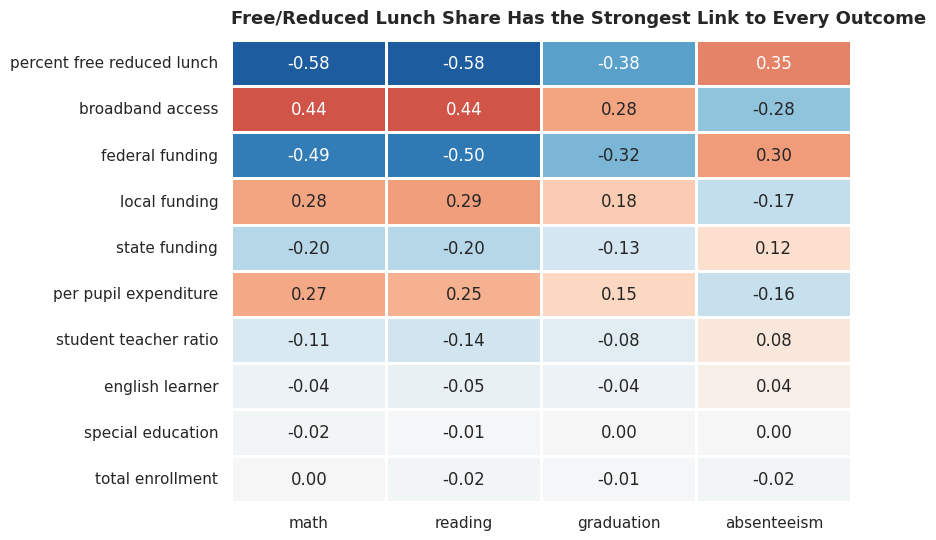

In [64]:
# Next, we will compare Socioeconomic conditions versus acdemic outcomes

socio_drivers = ['percent_free_reduced_lunch', 'broadband_access_pct', 'federal_funding_pct', 'local_funding_pct',
               'state_funding_pct', 'per_pupil_expenditure_usd', 'student_teacher_ratio',
               'english_learner_pct', 'special_education_pct', 'total_enrollment']
acad_outcomes = ['math_proficiency_pct', 'reading_proficiency_pct', 'graduation_rate_pct', 'chronic_absenteeism_pct']

corr_table = k12[socio_drivers + acad_outcomes].corr(method='spearman').loc[socio_drivers, acad_outcomes].round(2)
corr_table.index = [c.replace('_pct', '').replace('_usd', '').replace('_', ' ') for c in corr_table.index]
corr_table.columns = ['math', 'reading', 'graduation', 'absenteeism']

plt.figure(figsize=(8, 6))
sns.heatmap(corr_table, annot = True, fmt ='.2f', cmap ='RdBu_r', center = 0, vmin = -0.7, vmax = 0.7,
            linewidths=1, cbar=False)
plt.title('Free/Reduced Lunch Share Has the Strongest Link to Every Outcome',
          fontsize=13, fontweight='bold', loc='left', pad=12)
plt.ylabel('')
save_fig('04_correlation_heatmap')
plt.show();


In [65]:
# Next, we will group K-12 schools into four equal-sized bands
# by free/reduced lunch share (a measure of student poverty)

k12 = cleaned_data[cleaned_data['institution_group'] == 'K-12 school'].copy()
k12['lunch_band'] = pd.qcut(k12['percent_free_reduced_lunch'], 4,
                            labels = ['Lowest 25%', 'Second', 'Third', 'Highest 25%'])
print(k12.groupby('lunch_band', observed = True)['percent_free_reduced_lunch'].agg(['min', 'max']).round(1))
print('\n')

band_outcomes = k12.groupby('lunch_band', observed = True)[acad_outcomes].mean().round(1)
band_outcomes

              min   max
lunch_band             
Lowest 25%    0.0  26.7
Second       26.8  45.2
Third        45.3  60.9
Highest 25%  61.0  98.0




,math_proficiency_pct,reading_proficiency_pct,graduation_rate_pct,chronic_absenteeism_pct
lunch_band,,,,
Lowest 25%,70.9,75.7,87.6,17.6
Second,62.1,66.8,85.5,19.4
Third,55.2,60.2,83.8,21.0
Highest 25%,46.4,51.4,81.5,23.0


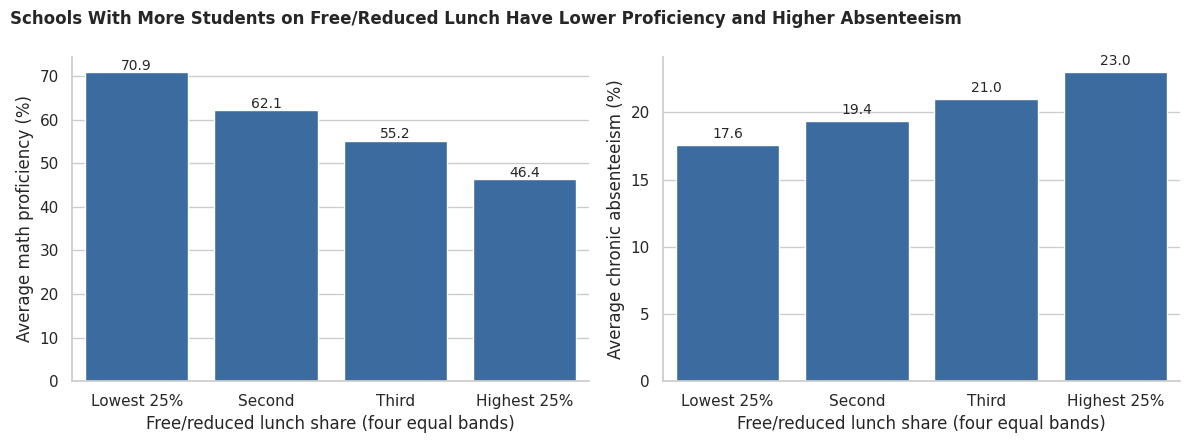

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, column, label in [(axes[0], 'math_proficiency_pct', 'Average math proficiency (%)'),
                          (axes[1], 'chronic_absenteeism_pct', 'Average chronic absenteeism (%)')]:

    sns.barplot(x = band_outcomes.index, y = band_outcomes[column], color = '#2B6CB0', ax=ax)
    for i, v in enumerate(band_outcomes[column]):
        ax.text(i, v + 0.5, f"{v:.1f}", ha='center', fontsize=10)
    ax.set_xlabel('Free/reduced lunch share (four equal bands)')
    ax.set_ylabel(label)
    sns.despine(ax=ax)

fig.suptitle('Schools With More Students on Free/Reduced Lunch Have Lower Proficiency and Higher Absenteeism',
             fontsize=12, fontweight='bold', x=0.01, ha='left')
plt.tight_layout()
save_fig('05_lunch_band_outcomes')
plt.show();

**Funding, Broadband, Staffing and Socioeconomic Conditions Observations**

- **Free/reduced lunch share is the strongest link to outcomes** (Spearman -0.58 with math and reading, -0.38 with graduation, +0.35 with absenteeism). Math proficiency falls from 70.9% in the lowest-lunch-share quarter of schools to 46.4% in the highest.

- **Broadband access** also tracks outcomes (0.44 with math). **Per-pupil spending** shows a weaker positive link (0.27). **Student-teacher ratio** is almost flat (-0.11).

- **Federal funding share** is strongly negative with outcomes (-0.49 with math), but it moves almost in step with lunch share (correlation 0.84 among K-12 schools), and it is exactly zero for private non-profit and religious schools. It is probably acting as a stand-in for poverty and ownership and not as a funding effect. We test this in Step 3.

- English-learner share, special-education share and enrollment have almost no relationship with outcomes among K-12 schools.

- Graduation rate follows the same direction as math and reading but more weakly, and we keep in mind it has an unclear meaning below high school.

In [67]:
# Next, we look at Title 1 Status versus Outcomes
# K-12 schools by Title I status:
# outcomes and the lunch share of each group

title_order = ['Not Applicable', 'Not Title I Eligible', 'Title I Targeted', 'Title I Schoolwide']
title_summary = k12.groupby('title_i_status')[['math_proficiency_pct', 'reading_proficiency_pct',
                                               'graduation_rate_pct', 'chronic_absenteeism_pct',
                                               'percent_free_reduced_lunch']].mean().round(1).loc[title_order]
title_summary['schools'] = k12['title_i_status'].value_counts().loc[title_order]
title_summary

,math_proficiency_pct,reading_proficiency_pct,graduation_rate_pct,chronic_absenteeism_pct,percent_free_reduced_lunch,schools
title_i_status,,,,,,
Not Applicable,69.9,74.5,87.5,18.0,17.8,750
Not Title I Eligible,67.2,71.9,86.9,18.3,22.9,767
Title I Targeted,58.9,63.6,84.6,20.0,44.0,945
Title I Schoolwide,51.7,56.8,82.8,21.8,60.8,2180


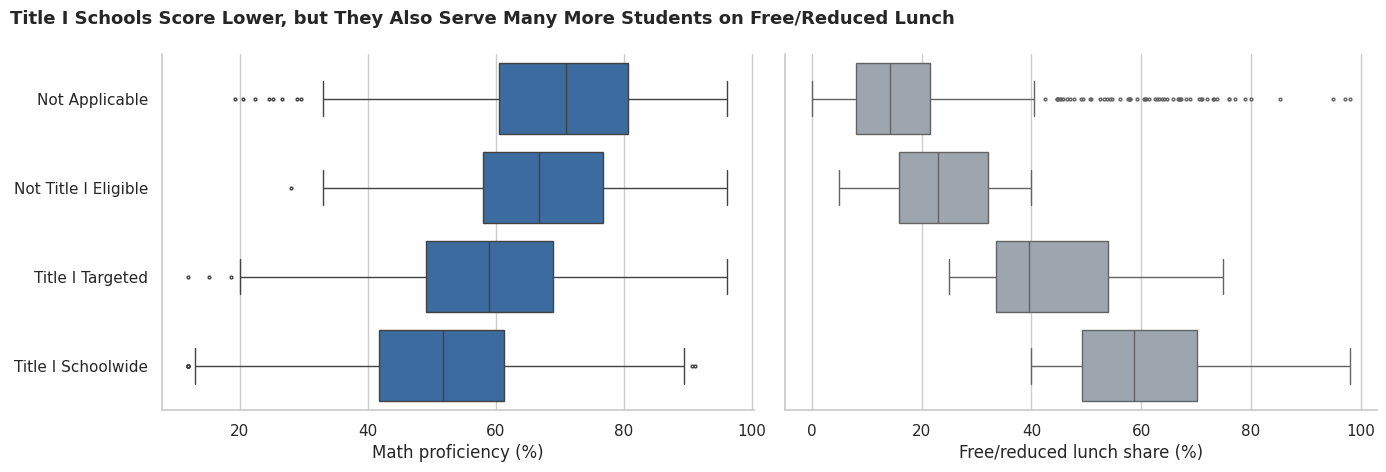

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=False)
sns.boxplot(data = k12, y ='title_i_status', x ='math_proficiency_pct', order = title_order, color = '#2B6CB0',
            fliersize=2, ax=axes[0])
axes[0].set_xlabel('Math proficiency (%)')
axes[1].set_xlabel('Free/reduced lunch share (%)')
sns.boxplot(data = k12, y ='title_i_status', x ='percent_free_reduced_lunch', order = title_order, color = '#9AA5B1',
            fliersize =2, ax =axes[1])
for ax in axes:
    ax.set_ylabel('')
    sns.despine(ax=ax)
axes[1].set_yticklabels([])

fig.suptitle('Title I Schools Score Lower, but They Also Serve Many More Students on Free/Reduced Lunch',
             fontsize =13, fontweight ='bold', x= 0.01, ha='left')
plt.tight_layout()
save_fig('06_title_i')
plt.show();

In [69]:
# Is the Title I gap just the lunch-share gap?
# We wil compare public and charter schools within the same lunch band.
# (Private schools are left out because they are all "Not Applicable" and have very low lunch shares.)

public_k12 = k12[k12['control'].isin(['Public', 'Public Charter'])].copy()
public_k12['lunch_band'] = pd.qcut(public_k12['percent_free_reduced_lunch'], 4,
                                   labels =['Lowest 25%', 'Second', 'Third', 'Highest 25%'])

same_band = public_k12.pivot_table(index ='lunch_band', columns ='title_i_status',
                                   values ='math_proficiency_pct', aggfunc ='mean', observed =True).round(1)
counts = public_k12.pivot_table(index ='lunch_band', columns='title_i_status',
                                values ='math_proficiency_pct', aggfunc='count', observed=True)

print("Average math proficiency by lunch band and Title I status (public and charter schools):\n")
print(same_band)
print('\n')
print("\nNumber of schools in each cell:\n")
print(counts)

Average math proficiency by lunch band and Title I status (public and charter schools):

title_i_status  Not Title I Eligible  Title I Schoolwide  Title I Targeted
lunch_band                                                                
Lowest 25%                      68.3                 NaN              65.4
Second                          61.0                58.7              60.1
Third                            NaN                53.5              52.4
Highest 25%                      NaN                45.5              48.2



Number of schools in each cell:

title_i_status  Not Title I Eligible  Title I Schoolwide  Title I Targeted
lunch_band                                                                
Lowest 25%                     653.0                 NaN             320.0
Second                         114.0               544.0             315.0
Third                            NaN               781.0             197.0
Highest 25%                      NaN              

**Business Translation: Title I and Outcomes**

- On the surface, Title I Schoolwide schools average 51.7% in math against 67.2% for schools not eligible for Title I, a gap of about 15 points. Absenteeism and graduation follow the same pattern.

- But Title I Schoolwide schools also serve far more students on free/reduced lunch (60.8% against 22.9%). Title I status is largely a label for the poverty level of a school.

- Comparing public and charter schools **within the same lunch band** shrinks the gap to about 1 to 3 points in every band where the groups can be compared (for example 61.0, 58.7 and 60.1 in the second band). Most of the Title I difference in outcomes therefore goes along with the lunch share and not with the label itself.

- The "Not Applicable" K-12 schools are all private schools. They score highest on average (69.9% in math) with a low lunch share (17.8%), but this comes from Private Non-Profit and Private Religious schools (about 13% lunch share, 70% to 73% in math). Private For-Profit schools look like public schools (49% lunch share, 57% in math). Results for private schools should not be set against Title I schools as if ownership were the only difference.

- This is not an evaluation of the Title I programme. It only shows that, in this dataset, Title I status adds little once the lunch share is known.

In [70]:
# Next, we will compare STEM certification with Institutional characteristics
# by loking at certification rates across levels,
# Ownership and Title 1 status

# Using Wilson's 95% confidence interval for a proportion:
# Which shows how much a rate could move by chance alone


def wilson_interval(successes, n, z=1.96):
    p = successes / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

def rate_table(data, column, order = None):
    table = data.groupby(column)['is_certified'].agg(certified ='sum', institutions ='count')
    table['rate_pct'] = (table['certified'] / table['institutions'] * 100).round(1)
    bounds = [wilson_interval(r.certified, r.institutions) for r in table.itertuples()]
    table['low_pct'] = [round(b[0] * 100, 1) for b in bounds]
    table['high_pct'] = [round(b[1] * 100, 1) for b in bounds]
    return table.loc[order] if order is not None else table.sort_values('rate_pct', ascending=False)

overall_rate = cleaned_data['is_certified'].mean() * 100
level_rates = rate_table(cleaned_data, 'level', level_order)
level_rates


,certified,institutions,rate_pct,low_pct,high_pct
level,,,,,
Elementary School,278,2225,12.5,11.2,13.9
Middle School,118,996,11.8,10.0,14.0
High School,269,1209,22.2,20.0,24.7
K-12 Combined,24,212,11.3,7.7,16.3
2-Year College,17,154,11.0,7.0,17.0
4-Year University,46,204,22.5,17.4,28.8


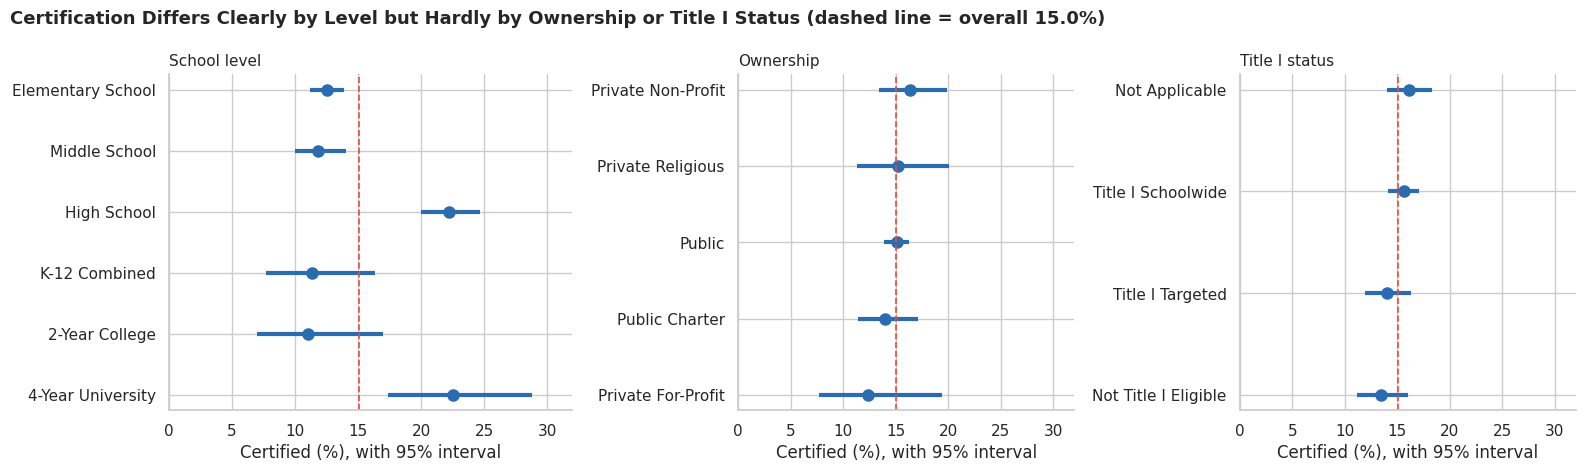

In [71]:
def rate_plot(ax, table, title):
    table = table.iloc[::-1]
    ax.hlines(table.index, table['low_pct'], table['high_pct'], color='#2B6CB0', linewidth=3)
    ax.plot(table['rate_pct'], table.index, 'o', color='#2B6CB0', markersize=8)
    ax.axvline(overall_rate, color='#E74C3C', linestyle='--', linewidth=1.2)
    ax.set_xlabel('Certified (%), with 95% interval')
    ax.set_title(title, fontsize=11, loc='left')
    sns.despine(ax=ax)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={'width_ratios': [1.2, 1, 1]})
rate_plot(axes[0], level_rates, 'School level')
rate_plot(axes[1], rate_table(cleaned_data, 'control'), 'Ownership')
rate_plot(axes[2], rate_table(cleaned_data, 'title_i_status'), 'Title I status')
for ax in axes:
    ax.set_xlim(0, 32)

fig.suptitle('Certification Differs Clearly by Level but Hardly by Ownership or Title I Status (dashed line = overall 15.0%)',
             fontsize=13, fontweight='bold', x=0.01, ha='left')
plt.tight_layout()
save_fig('07_certification_by_category')
plt.show();

In [72]:
# Do the numeric characteristics separate certified from non-certified K-12 schools?
# For each characteristic:
# We will split schools into four equal groups
# and compare the certification rate of the lowest and highest.

test_cols = {'total_enrollment': 'Enrollment', 'student_teacher_ratio': 'Student-teacher ratio',
             'per_pupil_expenditure_usd': 'Per-pupil spending', 'percent_free_reduced_lunch': 'Free/reduced lunch share',
             'broadband_access_pct': 'Broadband access', 'math_proficiency_pct': 'Math proficiency',
             'reading_proficiency_pct': 'Reading proficiency', 'chronic_absenteeism_pct': 'Chronic absenteeism',
             'federal_funding_pct': 'Federal funding share', 'english_learner_pct': 'English-learner share'}

quartile_rates = {}
for column, name in test_cols.items():
    groups = pd.qcut(k12[column], 4, labels=['Q1', 'Q2', 'Q3', 'Q4'], duplicates='drop')
    quartile_rates[name] = (k12.groupby(groups, observed=True)['is_certified'].mean() * 100).round(1)

quartile_table = pd.DataFrame(quartile_rates).T
quartile_table['gap_high_vs_low_quartile'] = (quartile_table.max(axis=1) - quartile_table.min(axis=1)).round(1)
quartile_table.sort_values('gap_high_vs_low_quartile', ascending=False)

,Q1,Q2,Q3,Q4,gap_high_vs_low_quartile
Enrollment,11.6,13.4,13.9,20.4,8.8
Chronic absenteeism,15.9,14.1,16.4,12.9,3.5
Broadband access,14.6,15.3,15.8,13.7,2.1
Math proficiency,15.9,14.6,15.0,13.8,2.1
Student-teacher ratio,15.8,15.6,13.8,14.2,2.0
English-learner share,14.6,14.7,14.1,16.0,1.9
Federal funding share,16.1,14.5,14.6,14.3,1.8
Reading proficiency,15.0,14.2,15.3,14.8,1.1
Per-pupil spending,14.6,15.2,15.3,14.3,1.0
Free/reduced lunch share,14.7,15.2,14.9,14.6,0.6


In [73]:
# How big a gap would pure chance produce?
# For this, we will shuffle the certification labels 5,000 times
# and measure the gap each time.
# (Quarters have about 1,160 schools each,
# so one shuffle test applies to every characteristic.)

rng = np.random.default_rng(42)
quarter_codes = pd.qcut(k12['percent_free_reduced_lunch'], 4, labels=False).values
certified = k12['is_certified'].values

random_gaps = []
for _ in range(5000):
    shuffled = rng.permutation(certified)
    rates = [shuffled[quarter_codes == q].mean() * 100 for q in range(4)]
    random_gaps.append(max(rates) - min(rates))

chance_limit = np.percentile(random_gaps, 95)
print(f"Typical (median) gap from chance alone: {np.median(random_gaps):.1f} points")
print(f"95% of random shuffles give a gap of {chance_limit:.1f} points or less")

Typical (median) gap from chance alone: 2.1 points
95% of random shuffles give a gap of 3.8 points or less


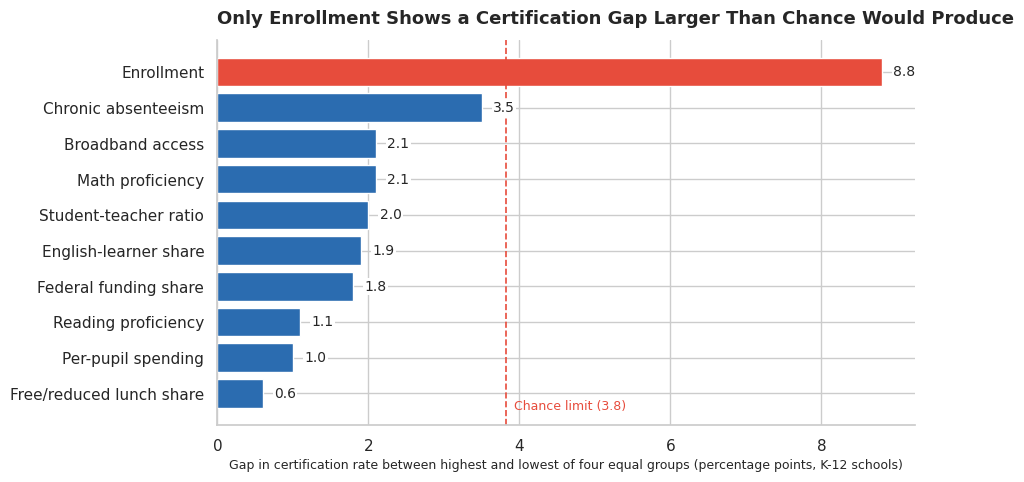

In [74]:
gap_plot = quartile_table['gap_high_vs_low_quartile'].sort_values()

plt.figure(figsize=(9, 5))
colors = ['#E74C3C' if name == 'Enrollment' else '#2B6CB0' for name in gap_plot.index]
plt.barh(gap_plot.index, gap_plot.values, color=colors)
plt.axvline(chance_limit, color ='#E74C3C', linestyle='--', linewidth=1.2)
plt.text(chance_limit + 0.1, -0.45, f"Chance limit ({chance_limit:.1f})", color = '#E74C3C', fontsize=9)
for i, v in enumerate(gap_plot.values):
    plt.text(v + 0.15, i, f"{v:.1f}", va='center', fontsize=10, bbox = dict(facecolor='white', edgecolor ='none', pad=1))
sns.despine()
plt.title('Only Enrollment Shows a Certification Gap Larger Than Chance Would Produce',
          fontsize=13, fontweight='bold', loc='left', pad=12)
plt.xlabel('Gap in certification rate between highest and lowest of four equal groups (percentage points, K-12 schools)', fontsize=9)
save_fig('08_certification_quartile_spread')
plt.show();

In [75]:
# Enrollment is the only one with a gap.
# Is it real, or does it come from school level
# (High Schools are larger AND more often certified)?
# We will look inside each level.

within_level = {}
for level in ['Elementary School', 'Middle School', 'High School']:
    subset = k12[k12['level'] == level]
    groups = pd.qcut(subset['total_enrollment'], 4, labels=['Smallest 25%', 'Second', 'Third', 'Largest 25%'])
    within_level[level] = (subset.groupby(groups, observed=True)['is_certified'].mean() * 100).round(1)

print("Certification rate (%) by enrollment quarter, within each level:\n")
pd.DataFrame(within_level).T

Certification rate (%) by enrollment quarter, within each level:



total_enrollment,Smallest 25%,Second,Third,Largest 25%
Elementary School,10.4,12.0,13.8,13.8
Middle School,10.8,10.8,12.8,13.0
High School,23.0,20.3,24.2,21.5


In [76]:
# Is the variation between states more than chance would produce?
 # (many states have few institutions)

state_table = cleaned_data.groupby('state_code')['is_certified'].agg(certified='sum', institutions='count')
state_table['rate_pct'] = (state_table['certified'] / state_table['institutions'] * 100).round(1)

expected = state_table['institutions'] * cleaned_data['is_certified'].mean()
chi2 = (((state_table['certified'] - expected) ** 2) / (state_table['institutions'] * cleaned_data['is_certified'].mean()
        * (1 - cleaned_data['is_certified'].mean()))).sum()
dof = len(state_table) - 1
print(f"States: {len(state_table)} | institutions per state: {state_table['institutions'].min()} to {state_table['institutions'].max()}")
print(f"State rates range from {state_table['rate_pct'].min()}% to {state_table['rate_pct'].max()}%")
print(f"Chi-square = {chi2:.1f} on {dof} degrees of freedom, p = {1 - stats.chi2.cdf(chi2, dof):.2f}\n")
state_table.sort_values('rate_pct').iloc[[0, 1, 2, -3, -2, -1]]

States: 51 | institutions per state: 11 to 531
State rates range from 6.2% to 27.3%
Chi-square = 45.6 on 50 degrees of freedom, p = 0.65



,certified,institutions,rate_pct
state_code,,,
WY,1,16,6.2
NE,3,39,7.7
OR,5,61,8.2
SD,4,17,23.5
KS,12,46,26.1
RI,3,11,27.3


**What Relates to STEM Certification**

- **School level is the clearest pattern.** High Schools (22.2%) and 4-Year Universities (22.5%) are certified at about twice the rate of Elementary (12.5%), Middle (11.8%), K-12 Combined (11.3%) and 2-Year Colleges (11.0%). The intervals for the two high-rate groups do not overlap with those of Elementary or Middle schools, so this gap is not just chance.

- **Ownership and Title I status show little.** Rates sit between about 12% and 16% for every ownership and Title I group, and their intervals overlap the overall 15.0% line. Notebook 05 will test the Title I link formally.

- **Almost no numeric characteristic separates certified from non-certified schools.** Across four equal groups of K-12 schools, the certification rate differs by only 0.6 to 3.5 percentage points for every characteristic except enrollment, with no steady direction (the largest is chronic absenteeism: 15.9%, 14.1%, 16.4%, 12.9%). Shuffling the labels at random produces gaps up to 3.8 points 95% of the time, so all nine of these gaps are within what chance alone gives.

- **Enrollment is the one exception (8.8 points, well beyond the 3.8-point chance limit),** but it mostly reflects school level, since High Schools are larger and more often certified. Within each level the pattern is much weaker: 3.4 points from smallest to largest quarter for Elementary schools, 2.2 for Middle schools, and no steady pattern for High Schools.

- **State differences are what chance alone would give.** State rates range from 6% to 27%, but states have between 11 and 531 institutions, and the spread is consistent with random variation (chi-square 45.6 on 50 degrees of freedom, p = 0.65).

- **What this means for the model:** most of the predictable signal for certification appears to be school level. We should expect modest results from a model that uses the other characteristics, and we should always compare it against a baseline that uses level alone.

*Phase 3.3: Multivariate Analysis*

- Here, we will check whether a relationship remains after another factor is taken into account.

- Because free/reduced lunch share is so strongly tied to outcomes, we test whether spending, broadband access, federal funding share and class size still relate to math proficiency once lunch share is held fixed.

- We will use K-12 schools.

In [77]:
# Partial correlation:
# the link between a driver and math proficiency AFTER removing what lunch share explains of each.
# We use ranks so it matches the Spearman correlations shown earlier.

def partial_spearman(data, x, y, control):
    ranks = data[[x, y, control]].rank()
    def residual(target):
        model = LinearRegression().fit(ranks[[control]], ranks[target])
        return ranks[target] - model.predict(ranks[[control]])
    return np.corrcoef(residual(x), residual(y))[0, 1]

rows = []
for column, name in [('per_pupil_expenditure_usd', 'Per-pupil spending'),
                     ('broadband_access_pct', 'Broadband access'),
                     ('federal_funding_pct', 'Federal funding share'),
                     ('local_funding_pct', 'Local funding share'),
                     ('student_teacher_ratio', 'Student-teacher ratio')]:
    raw = k12[column].corr(k12['math_proficiency_pct'], method='spearman')
    adjusted = partial_spearman(k12, column, 'math_proficiency_pct', 'percent_free_reduced_lunch')
    rows.append((name, round(raw, 2), round(adjusted, 2)))

partial_table = pd.DataFrame(rows, columns=['driver', 'with_math_raw', 'with_math_after_lunch_share']).set_index('driver')
partial_table

,with_math_raw,with_math_after_lunch_share
driver,,
Per-pupil spending,0.27,0.18
Broadband access,0.44,0.00
Federal funding share,-0.49,-0.01
Local funding share,0.28,0.00
Student-teacher ratio,-0.11,0.01


In [78]:
# How much of math proficiency does each set of factors explain,
# and how large is the spending effect once lunch share is included?

y = k12['math_proficiency_pct']
models = {'Spending only': ['per_pupil_expenditure_usd'],
          'Spending + lunch share': ['per_pupil_expenditure_usd', 'percent_free_reduced_lunch'],
          'Spending + lunch share + broadband': ['per_pupil_expenditure_usd', 'percent_free_reduced_lunch',
                                                  'broadband_access_pct']}
results = []
for name, columns in models.items():
    X = (k12[columns] - k12[columns].mean()) / k12[columns].std()
    fit = LinearRegression().fit(X, y)
    row = {'model': name, 'R_squared': round(fit.score(X, y), 3)}
    for column, coef in zip(columns, fit.coef_):
        row[column] = round(coef, 2)
    results.append(row)

pd.DataFrame(results).set_index('model')

,R_squared,per_pupil_expenditure_usd,percent_free_reduced_lunch,broadband_access_pct
model,,,,
Spending only,0.083,4.61,NaN,NaN
Spending + lunch share,0.369,2.54,-8.83,NaN
Spending + lunch share + broadband,0.369,2.54,-8.72,0.15


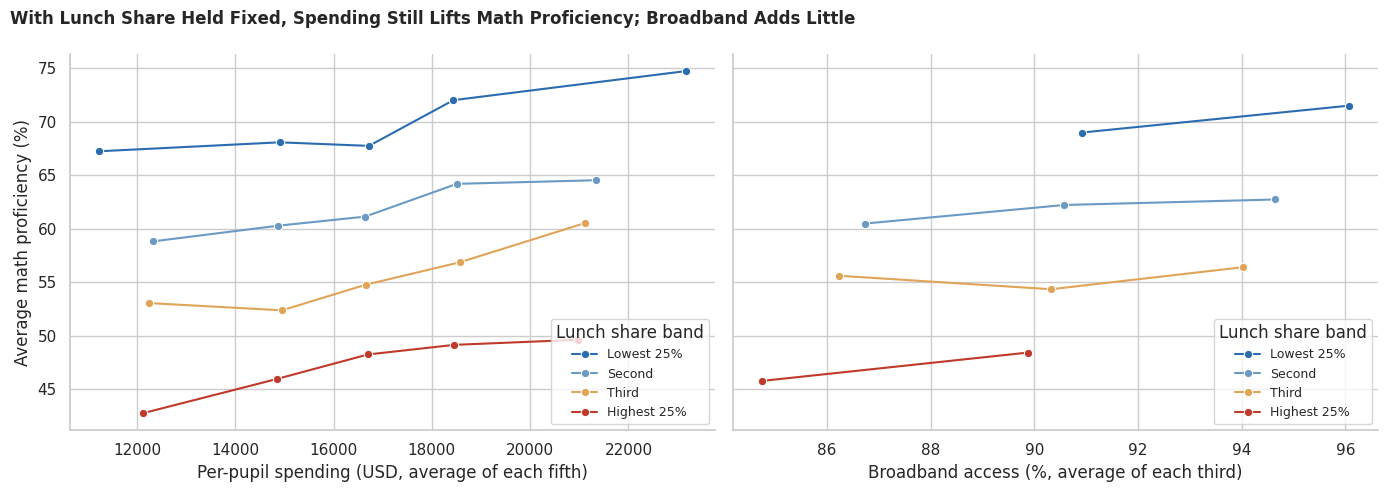

Smallest group shown: 120 schools (spending), 160 schools (broadband)


In [79]:
# Visual check:
# We will hold lunch share fixed (four bands) and look at math proficiency across spending and broadband groups.
# Cells with fewer than 30 schools are dropped so that averages are not based on tiny groups.

MIN_SCHOOLS = 30

def band_lines(ax, column, label, groups):
    data = k12.assign(driver_group=pd.qcut(k12[column], groups, labels=False, duplicates='drop'))
    table = (data.groupby(['lunch_band', 'driver_group'], observed=True)
                 .agg(x=(column, 'mean'), math=('math_proficiency_pct', 'mean'), n=('institution_id', 'count'))
                 .reset_index())
    table = table[table['n'] >= MIN_SCHOOLS]
    sns.lineplot(data=table, x='x', y='math', hue='lunch_band', marker='o',
                 palette=['#2B6CB0', '#6B9AC4', '#E0A458', '#C0392B'], ax=ax)
    ax.set_xlabel(label)
    ax.set_ylabel('Average math proficiency (%)')
    ax.legend(title='Lunch share band', fontsize=9, loc='lower right')
    sns.despine(ax=ax)
    return table

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
spend_table = band_lines(axes[0], 'per_pupil_expenditure_usd', 'Per-pupil spending (USD, average of each fifth)', 5)
broadband_table = band_lines(axes[1], 'broadband_access_pct', 'Broadband access (%, average of each third)', 3)

fig.suptitle('With Lunch Share Held Fixed, Spending Still Lifts Math Proficiency; Broadband Adds Little',
             fontsize=12, fontweight='bold', x=0.01, ha='left')
plt.tight_layout()
save_fig('09_multivariate_math')
plt.show();
print(f"Smallest group shown: {spend_table['n'].min()} schools (spending), {broadband_table['n'].min()} schools (broadband)")

In [80]:
# How much does math proficiency change from the lowest to the highest spending (or broadband) group within each lunch band?

def change_within_band(table):
    return table.groupby('lunch_band', observed=True).apply(lambda t: round(t['math'].iloc[-1] - t['math'].iloc[0], 1), include_groups=False)

print("\nChange in math proficiency (points), lowest to highest group within each lunch band:")
print(pd.DataFrame({'spending': change_within_band(spend_table), 'broadband': change_within_band(broadband_table)}))
print(f"\nFor comparison, the gap between the lowest and highest lunch band is "
      f"{band_outcomes['math_proficiency_pct'].iloc[0] - band_outcomes['math_proficiency_pct'].iloc[-1]:.1f} points")


Change in math proficiency (points), lowest to highest group within each lunch band:
             spending  broadband
lunch_band                      
Lowest 25%        7.5        2.5
Second            5.7        2.2
Third             7.5        0.8
Highest 25%       6.9        2.6

For comparison, the gap between the lowest and highest lunch band is 24.5 points


**Multivariate Findings**

- **Spending still matters, but less than it first appears.** The link between per-pupil spending and math proficiency drops from 0.27 to 0.18 after lunch share is accounted for, and the effect of spending per standard deviation falls from about 4.6 to 2.5 points. In every lunch band, the highest-spending group scores about 6 to 7.5 points above the lowest-spending group (5.7, 6.9, 7.5 and 7.5 points).

- **Broadband access mostly reflects poverty.** Its link to math falls from 0.44 to 0.00 after lunch share is accounted for. Adding broadband to a model that already has lunch share does not improve it (R-squared stays at 0.369). Within a lunch band the broadband lines rise only slightly (0.8 to 2.6 points from the lowest to the highest broadband group, against a 24.5-point gap between the lowest and highest lunch bands). The apparent advantage of high broadband access in the raw data seems to come from the fact that schools with high broadband access also serve fewer students in poverty.

- **Federal funding share is a poverty marker.** Its strong negative link with math (-0.49) disappears once lunch share is accounted for (-0.01). The same holds for local funding share (0.00) and for student-teacher ratio (0.01).

- **Lunch share does most of the work.** Spending alone explains about 8% of the variation in math proficiency, and spending with lunch share explains about 37%.

- Several candidate features (broadband, federal funding share, Title I status) carry largely the same information as lunch share. They are not independent signals, which we need to remember when judging which features "contribute most" in the model.

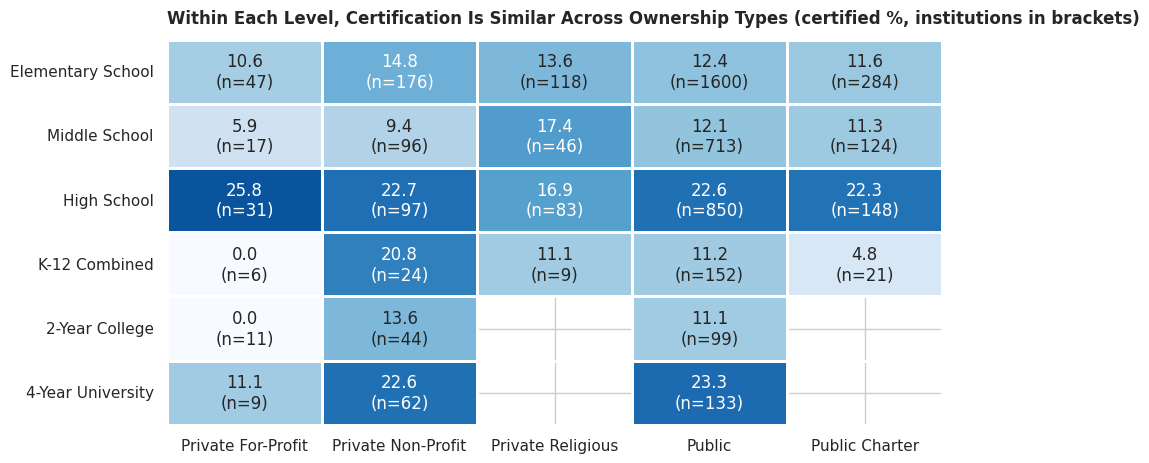

In [81]:
# Does anything beyond school level help explain certification?
# We will take a multivariate look at certification:
# school level combined with ownership.

level_control = cleaned_data.pivot_table(index='level', columns ='control', values = 'is_certified',
                                     aggfunc=['mean', 'count'])
rates = (level_control['mean'] * 100).round(1).reindex(level_order)
sizes = level_control['count'].reindex(level_order).fillna(0).astype(int)

plt.figure(figsize=(10, 5))
annot = rates.astype(str).where(rates.notna(), '') + '\n(n=' + sizes.astype(str) + ')'
annot = annot.where(rates.notna(), '')

sns.heatmap(rates, annot = annot, fmt='', cmap='Blues', vmin=0, vmax=30, cbar=False, linewidths=1)
plt.title('Within Each Level, Certification Is Similar Across Ownership Types (certified %, institutions in brackets)',
          fontsize=12, fontweight='bold', loc='left', pad=12)
plt.xlabel('')
plt.ylabel('')
save_fig('10_level_by_control')
plt.show();

**Business Translation: Level and Ownership Together**

- Once school level is fixed, certification rates look similar across ownership types in the large groups (for example, among High Schools: Public 22.6%, Public Charter 22.3%, Private Non-Profit 22.7%; Private Religious is lower at 16.9% but has only 83 schools, and its range of uncertainty includes 22%). The bigger swings, such as 0% or 25.8%, come from groups with fewer than about 35 institutions and should not be read as findings.

- This supports one clear picture: school level carries most of the visible signal, and the other recorded characteristics add little that can be seen in simple comparisons.

**What was found:**

- **Outcomes:** free/reduced lunch share is the strongest link to math, reading, graduation and absenteeism. Broadband access, federal funding share and Title I status mostly reflect the same poverty signal, and their links shrink to near zero once lunch share is held fixed. Per-pupil spending keeps a smaller positive link.

- **STEM certification:** school level is the one clear pattern (about 22% for High Schools and 4-Year Universities against about 11% to 12.5% for the other levels). Ownership, Title I status, spending, staffing, broadband, lunch share, proficiency and state show differences no larger than chance would produce.

- **Implication for modelling:** expect a model using these characteristics to predict certification only modestly, with most of the predictive value coming from school level.

**Statistical Analysis**

- The exploratory analysis suggested that school level is the only clear pattern in STEM certification.

- Here we test that formally, so we know which patterns are real and which could be chance.

*Rules used throughout this statistical analysis:*

- A result is called statistically significant when the p-value is below 0.05 after correcting for the number of tests run. Every test reports an effect size as well as a p-value, because with 5,000 institutions even tiny differences can be significant, and a p-value alone does not say whether a difference matters.

In [82]:
# Before we proceed,
# we will create a helper functions to be used for the statistical analysis

def holm_adjust(p_values):
    # Holm step-down correction: controls the chance of any false alarm across a set of tests
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    m = len(p_values)
    adjusted = np.empty(m)
    running_max = 0.0
    for rank, index in enumerate(order):
        running_max = max(running_max, (m - rank) * p_values[index])
        adjusted[index] = min(1.0, running_max)
    return adjusted

def chi_square_test(data, column):
    # Chi-square test of independence between a category and certification, with Cramer's V
    table = pd.crosstab(data[column], data['is_certified'])
    chi2, p, dof, expected = stats.chi2_contingency(table, correction=False)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    return {'table': table, 'chi2': chi2, 'p': p, 'dof': dof, 'expected': expected, 'cramers_v': v}

def format_p(p):
    return '< 0.001' if p < 0.001 else f'{p:.3f}'

*We will begin by answering the following questions:*

**Question 1.**

*Is STEM certification associated with Title I status?*

**Data Inovlved:**
- Two categories (certified or not; four Title I groups)

**Statistical Method:**
- Chi-square test of independence, Cramér's V, then a check that adjusts for school level

**Why this method:**
- Compares observed counts with the counts expected if the two were unrelated. Cramér's V shows how large the association is. Level is checked because Title I groups contain different mixes of levels.


**Null hypothesis (H0):**

- STEM certification and Title I status are independent. The certification rate is the same in every Title I group.


**Alternative hypothesis (H1):**

- The certification rate differs between at least two Title I groups.


In [83]:
# Contingency table: certified or not, by Title I status

title_test = chi_square_test(cleaned_data, 'title_i_status')
title_table = title_test['table'].copy()
title_table.columns = ['Not certified', 'Certified']
title_table['Certification rate (%)'] = (title_table['Certified'] / title_table.sum(axis=1) * 100).round(1)
title_table

,Not certified,Certified,Certification rate (%)
title_i_status,,,
Not Applicable,930,178,16.1
Not Title I Eligible,664,103,13.4
Title I Schoolwide,1841,339,15.6
Title I Targeted,813,132,14.0


In [84]:
# Check the test's assumption:
# every expected count should be at least 5

print(f"Smallest expected count: {title_test['expected'].min():.1f}  (rule: at least 5, so the test is reliable)")

print(f"\nChi-square = {title_test['chi2']:.2f}, degrees of freedom = {title_test['dof']}, p-value = {title_test['p']:.3f}")
print(f"Cramer's V (effect size) = {title_test['cramers_v']:.3f}")

Smallest expected count: 115.4  (rule: at least 5, so the test is reliable)

Chi-square = 3.76, degrees of freedom = 3, p-value = 0.288
Cramer's V (effect size) = 0.027


In [85]:
# Which groups, if any, depart from what independence predicts?

observed = title_test['table'].values
expected = title_test['expected']
row_share = observed.sum(axis=1, keepdims=True) / observed.sum()
col_share = observed.sum(axis=0, keepdims=True) / observed.sum()
adjusted_residuals = (observed - expected) / np.sqrt(expected * (1 - row_share) * (1 - col_share))
print(f"Largest adjusted residual (absolute): {np.abs(adjusted_residuals).max():.2f}")

Largest adjusted residual (absolute): 1.36


In [86]:
# How many certified institutions would we expect in each group
# if Title I status were unrelated to certification?

compare = pd.DataFrame({
    'observed_certified': title_test['table'][1],
    'expected_certified': pd.Series(expected[:, 1], index=title_test['table'].index).round(1),
})
compare['difference'] = (compare['observed_certified'] - compare['expected_certified']).round(1)
compare

,observed_certified,expected_certified,difference
title_i_status,,,
Not Applicable,178,166.6,11.4
Not Title I Eligible,103,115.4,-12.4
Title I Schoolwide,339,327.9,11.1
Title I Targeted,132,142.1,-10.1


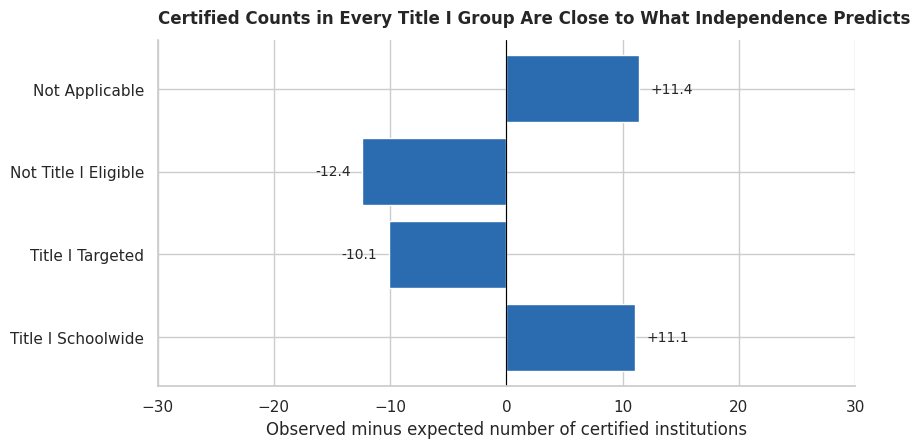

In [87]:
# Let's visualize this

plt.figure(figsize=(9, 4.5))
order = ['Not Applicable', 'Not Title I Eligible', 'Title I Targeted', 'Title I Schoolwide']
diff = compare['difference'].loc[order]
plt.barh(order[::-1], diff.values[::-1], color ='#2B6CB0')
for i, v in enumerate(diff.values[::-1]):
    plt.text(v + (1 if v >= 0 else -1), i, f"{v:+.1f}", va='center', ha='left' if v >= 0 else 'right', fontsize=10)
plt.axvline(0, color='black', linewidth=0.8)

sns.despine()

plt.title('Certified Counts in Every Title I Group Are Close to What Independence Predicts',
          fontsize=12, fontweight='bold', loc='left', pad=12)
plt.xlabel('Observed minus expected number of certified institutions')
plt.xlim(-30, 30)
save_fig('11_title_i_observed_vs_expected')
plt.show();

In [88]:
# The Title I groups contain different mixes of school levels.
# Could level hide or create a link?

level_mix = (pd.crosstab(cleaned_data['title_i_status'], cleaned_data['level'], normalize='index') * 100).round(1)
level_mix[['Elementary School', 'Middle School', 'High School', 'K-12 Combined', '2-Year College', '4-Year University']]

level,Elementary School,Middle School,High School,K-12 Combined,2-Year College,4-Year University
title_i_status,,,,,,
Not Applicable,30.8,14.4,19.0,3.5,13.9,18.4
Not Title I Eligible,49.2,22.4,24.1,4.3,0.0,0.0
Title I Schoolwide,47.4,21.1,26.8,4.7,0.0,0.0
Title I Targeted,50.1,21.7,24.2,4.0,0.0,0.0


In [89]:
# We will test Title I status AFTER allowing for school level (likelihood-ratio(lr) test).
# Model A uses level only.
# Model B uses level and Title I status.
# Does adding Title I improve the fit more than chance would?

def log_likelihood(features, outcome):
    model = LogisticRegression(C = np.inf, max_iter = 5000).fit(features, outcome)
    # C = np.inf means no shrinkage, i.e. an ordinary logistic regression
    return -log_loss(outcome, model.predict_proba(features)[:, 1], normalize=False)

y_all = cleaned_data['is_certified'].values
level_dummies = pd.get_dummies(cleaned_data['level'], drop_first = True).astype(float)
title_dummies = pd.get_dummies(cleaned_data['title_i_status'], drop_first = True).astype(float)

lr_stat = 2 * (log_likelihood(pd.concat([level_dummies, title_dummies], axis=1), y_all)
               - log_likelihood(level_dummies, y_all))
lr_df = title_dummies.shape[1]
lr_p = 1 - stats.chi2.cdf(lr_stat, lr_df)
print(f"Title I status after allowing for level:\nchi-square = {lr_stat:.2f}, df = {lr_df}, p-value = {lr_p:.3f}")

Title I status after allowing for level:
chi-square = 2.08, df = 3, p-value = 0.556


In [90]:
# A cleaner comparison:
# public and charter K-12 schools only (all three genuine Title I categories, no colleges or private schools)

public_k12 = k12[k12['control'].isin(['Public', 'Public Charter'])]
public_test = chi_square_test(public_k12, 'title_i_status')
print(f"Public and charter K-12 schools only (n = {len(public_k12):,}):\nchi-square = {public_test['chi2']:.2f}, "
      f"df = {public_test['dof']}, p-value = {public_test['p']:.3f}, Cramer's V = {public_test['cramers_v']:.3f}")

results.append({'question': 'Certification vs Title I status, allowing for level', 'test': 'Likelihood-ratio test',
                'statistic': round(lr_stat, 2), 'p_value': lr_p, 'effect_size': 'n/a'})
results.append({'question': 'Certification vs Title I status, public and charter K-12 only', 'test': 'Chi-square (3 groups)',
                'statistic': round(public_test['chi2'], 2), 'p_value': public_test['p'],
                'effect_size': f"Cramer's V = {public_test['cramers_v']:.3f}"})

Public and charter K-12 schools only (n = 3,892):
chi-square = 2.63, df = 2, p-value = 0.268, Cramer's V = 0.026


In [91]:
# How large an association could this test have detected?
# (power analysis for the Title I chi-square test)
# We find the smallest Cramer's V that the test would catch 80% of the time.

n_total = len(cleaned_data)
critical = stats.chi2.ppf(1 - 0.05, title_test['dof'])
detectable_v = None

for v in np.arange(0.005, 0.2, 0.001):
    power = 1 - stats.ncx2.cdf(critical, title_test['dof'], v**2 * n_total)
    if power >= 0.80:
        detectable_v = v
        break
print(f"The test would detect an association of Cramer's V = {detectable_v:.3f} or larger 80% of the time.")
print(f"Observed Cramer's V = {title_test['cramers_v']:.3f}")

The test would detect an association of Cramer's V = 0.047 or larger 80% of the time.
Observed Cramer's V = 0.027


**Business Translation: Title I Status and Certification**

- **No evidence of an association.** The certification rate is between 13.4% and 16.1% across the four Title I groups. The chi-square test gives p = 0.288, well above 0.05, and the effect size is tiny (Cramér's V = 0.027). We cannot reject the idea that certification is unrelated to Title I status. The test's conditions were met (the smallest expected count is 115).

- **No group stands out.** The largest adjusted residual is below 2, and every group has within about 12 certified institutions of what independence predicts.

- **Level does not change the answer.** The Title I groups do contain different mixes of levels (for example, "Not Applicable" includes all colleges), but after allowing for level the result is still not significant (p = 0.556). Among public and charter K-12 schools alone, the result is the same (p = 0.268).

- **The test was sensitive enough to matter.** With 5,000 institutions it could have detected an association of Cramér's V of about 0.05, so any real link with Title I status is smaller than that and of little practical importance.

- **In plain terms:** knowing whether a school is Title I tells us almost nothing about whether it is STEM-certified.

**Question 2.**

*Does STEM certification differ by school level?*

**Data Involved:**
- Two categories (certified or not; six levels)

**Statistical Method:**
- Chi-square test, pairwise Fisher tests with Holm correction, bootstrap confidence interval for the size of the gap.

**Why this method:**
- The chi-square test says whether any difference exists. Pairwise tests say which levels differ, and Holm correction stops 15 comparisons from producing false alarms. The interval shows how big the gap is.


**Null hypothesis (H0):**

- The certification rate is the same at every school level.

**Alternative hypothesis (H1):**

- The certification rate differs for at least one level.


In [92]:
level_test = chi_square_test(cleaned_data, 'level')

print(f"Smallest expected count: {level_test['expected'].min():.1f}  (rule: at least 5)")
print(f"Chi-square = {level_test['chi2']:.2f}, degrees of freedom = {level_test['dof']}, p-value = {format_p(level_test['p'])}")
print(f"Cramer's V (effect size) = {level_test['cramers_v']:.3f}")

Smallest expected count: 23.2  (rule: at least 5)
Chi-square = 81.64, degrees of freedom = 5, p-value = < 0.001
Cramer's V (effect size) = 0.128


In [93]:
# The chi-square test says SOME levels differ.
# Which pairs?
# We will compare all 15 pairs with Fisher's exact test
# and correct for running 15 tests at once (Holm).

pair_rows = []
for a, b in itertools.combinations(level_order, 2):
    group_a = cleaned_data[cleaned_data['level'] == a]['is_certified']
    group_b = cleaned_data[cleaned_data['level'] == b]['is_certified']
    table = [[group_a.sum(), len(group_a) - group_a.sum()], [group_b.sum(), len(group_b) - group_b.sum()]]
    p = stats.fisher_exact(table)[1]
    pair_rows.append((a, b, group_a.mean() * 100, group_b.mean() * 100, p))

pairwise = pd.DataFrame(pair_rows, columns=['level_a', 'level_b', 'rate_a_pct', 'rate_b_pct', 'p_value'])
pairwise['p_holm'] = holm_adjust(pairwise['p_value'])
pairwise['significant'] = pairwise['p_holm'] < 0.05
pairwise.sort_values('p_value').round(4).reset_index(drop=True)

,level_a,level_b,rate_a_pct,rate_b_pct,p_value,p_holm,significant
0,Elementary School,High School,12.4944,22.2498,0.0000,0.0000,True
1,Middle School,High School,11.8474,22.2498,0.0000,0.0000,True
2,Middle School,4-Year University,11.8474,22.5490,0.0001,0.0016,True
3,Elementary School,4-Year University,12.4944,22.5490,0.0001,0.0018,True
4,High School,K-12 Combined,22.2498,11.3208,0.0002,0.0018,True
5,High School,2-Year College,22.2498,11.0390,0.0010,0.0103,True
6,K-12 Combined,4-Year University,11.3208,22.5490,0.0025,0.0225,True
7,2-Year College,4-Year University,11.0390,22.5490,0.0050,0.0396,True
8,Elementary School,Middle School,12.4944,11.8474,0.6424,1.0000,False
9,Elementary School,2-Year College,12.4944,11.0390,0.7045,1.0000,False


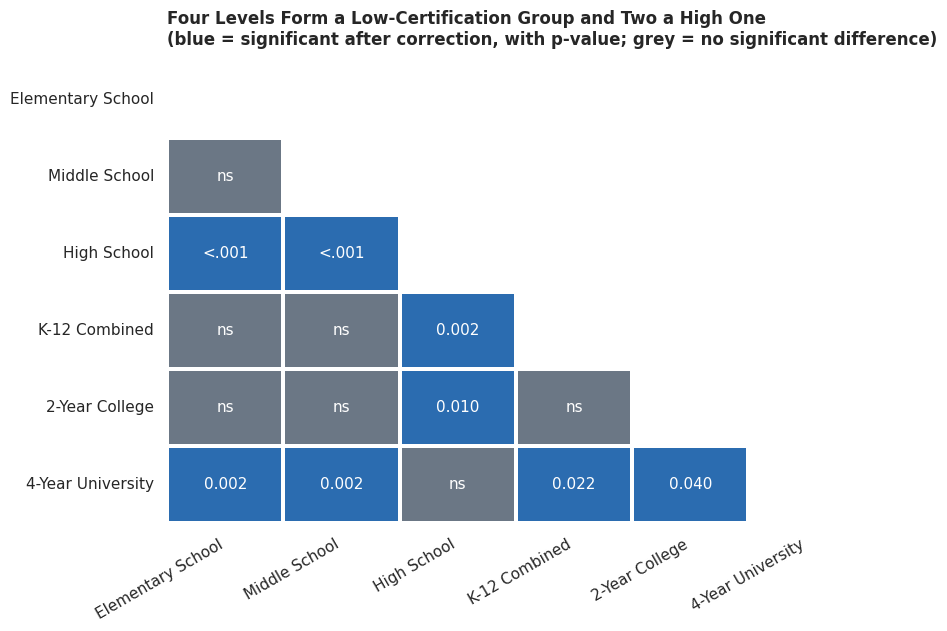

In [94]:
# Let's visualize this

matrix = pd.DataFrame('', index = level_order, columns = level_order)
signif = pd.DataFrame(0, index = level_order, columns = level_order)

for row in pairwise.itertuples():
    text = 'ns' if not row.significant else format_p(row.p_holm).replace('< 0.001', '<.001')
    matrix.loc[row.level_b, row.level_a] = text
    signif.loc[row.level_b, row.level_a] = 1 if row.significant else -1

mask = signif == 0
plt.figure(figsize=(9, 6))
sns.heatmap(signif, mask = mask, annot = matrix, fmt='', cmap = ListedColormap(['#6B7785', '#2B6CB0']),
            cbar = False, linewidths = 1.5, vmin = -1, vmax = 1, annot_kws = {'color': 'white', 'fontsize': 11})

plt.gca().grid(False) # Turns off the gridlines

plt.title('Four Levels Form a Low-Certification Group and Two a High One\n'
          '(blue = significant after correction, with p-value; grey = no significant difference)',
          fontsize = 12, fontweight = 'bold', loc = 'left', pad = 12)
plt.xlabel('')
plt.ylabel('')
plt.xticks(rotation=30, ha='right')
save_fig('12_level_pairwise')
plt.show();

In [95]:
# How big is the gap between the two groups the pairwise tests point to?
# Bootstrap:
# We will resample institutions 5,000 times and see how much the gap moves.

high_group = cleaned_data['level'].isin(['High School', '4-Year University']).values
certified = cleaned_data['is_certified'].values

rate_high = certified[high_group].mean()
rate_low = certified[~high_group].mean()
gap = rate_high - rate_low

boot_gaps = np.array([rng.choice(certified[high_group], high_group.sum()).mean()
                      - rng.choice(certified[~high_group], (~high_group).sum()).mean() for _ in range(5000)])
ci_low, ci_high = np.percentile(boot_gaps, [2.5, 97.5])

print(f"High Schools and 4-Year Universities: {rate_high:.1%} certified ({high_group.sum():,} institutions)")
print(f"All other levels:                     {rate_low:.1%} certified ({(~high_group).sum():,} institutions)")
print(f"Gap: {gap * 100:.1f} percentage points (95% interval: {ci_low * 100:.1f} to {ci_high * 100:.1f})")
print(f"High-level institutions are {rate_high / rate_low:.2f} times as likely to be certified")

High Schools and 4-Year Universities: 22.3% certified (1,413 institutions)
All other levels:                     12.2% certified (3,587 institutions)
Gap: 10.1 percentage points (95% interval: 7.7 to 12.5)
High-level institutions are 1.83 times as likely to be certified


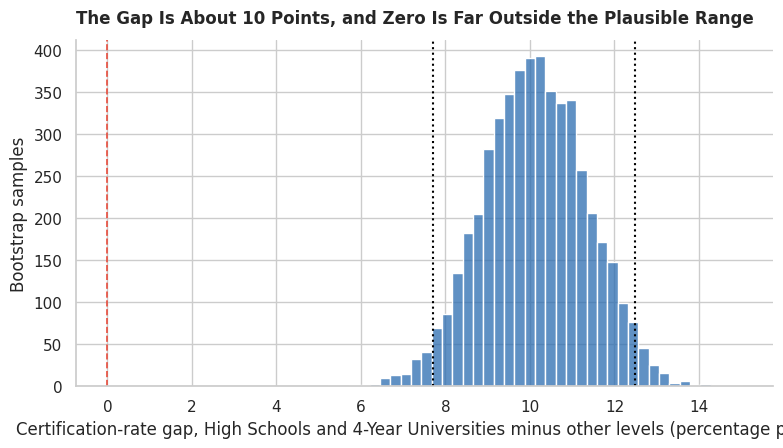

In [96]:
# Let's visualize this gap

results.append({'question': 'Certification: High School + 4-Year University vs other levels', 'test': 'Bootstrap interval for difference',
                'statistic': round(gap * 100, 1), 'p_value': np.nan,
                'effect_size': f"Gap {gap * 100:.1f} points (95% CI {ci_low * 100:.1f} to {ci_high * 100:.1f}); ratio {rate_high / rate_low:.2f}"})

plt.figure(figsize=(9, 4.5))
sns.histplot(boot_gaps * 100, bins=40, color = '#2B6CB0')
plt.axvline(0, color = '#E74C3C', linestyle='--', linewidth=1.2)
plt.axvline(ci_low * 100, color='black', linestyle=':')
plt.axvline(ci_high * 100, color='black', linestyle=':')

sns.despine()

plt.title(f'The Gap Is About {gap * 100:.0f} Points, and Zero Is Far Outside the Plausible Range',
          fontsize=12, fontweight='bold', loc='left', pad=12)
plt.xlabel('Certification-rate gap, High Schools and 4-Year Universities minus other levels (percentage points)')
plt.ylabel('Bootstrap samples')
save_fig('13_level_gap_bootstrap')
plt.show();

**Business Translation: School Level and Certification**

- **School level is clearly related to certification.** The chi-square test gives p < 0.001 (chi-square = 81.6 on 5 degrees of freedom). The effect is small to moderate (Cramér's V = 0.128), which is the strongest association found in this project.

- **The 15 pairwise comparisons split the levels into two groups.** High Schools (22.2%) and 4-Year Universities (22.5%) are each significantly different from Elementary, Middle, K-12 Combined and 2-Year College institutions (11.0% to 12.5%), even after correcting for 15 tests. High Schools and 4-Year Universities do not differ from each other (adjusted p = 1.0), and neither do any two of the four lower-rate levels.

- **The gap is about 10 points.** High Schools and 4-Year Universities are certified at 22.3% against 12.2% for the other levels, a gap of 10.1 percentage points (95% interval 7.8 to 12.5), or about 1.8 times as often.

- **A caution about the grouping.** We chose to compare these two groups after seeing the EDA charts. The pairwise tests, which compare every pair with a correction, give the same split without relying on that choice, so the grouping is supported.

- **The model implication:** a model that knows only school level can already separate these two groups. Whatever the other features add must be judged on top of that.

**Question 3.**

*Do Ownership, Locale or State matter?*

**Data involved:**
- Two categories (certified or not; several groups).

**Statistical Method:**
- Chi-square tests with Holm correction across all five category tests (state uses a shuffle test)

**Why this method:**
- Same logic as Question 1. Many states have few institutions, so the shuffle version of the test is used for state.

In [97]:
# We will test the remaining category variables the same way.
# Together with Title I and level this makes a family of five tests.

family = [('Title I status', 'title_i_status'), ('School level', 'level'), ('Ownership', 'control'),
          ('Locale type', 'nces_locale'), ('State', 'state_code')]

family_rows = []
for name, column in family:
    test = chi_square_test(cleaned_data, column)
    family_rows.append({'variable': name, 'groups': test['table'].shape[0], 'chi2': test['chi2'], 'df': test['dof'],
                        'p_value': test['p'], 'cramers_v': test['cramers_v'], 'smallest_expected': test['expected'].min()})
family_table = pd.DataFrame(family_rows)
family_table[['variable', 'groups', 'chi2', 'df', 'cramers_v', 'p_value', 'smallest_expected']].round(3)

,variable,groups,chi2,df,cramers_v,p_value,smallest_expected
0,Title I status,4,3.763,3,0.027,0.288,115.357
1,School level,6,81.637,5,0.128,0.000,23.162
2,Ownership,5,1.885,4,0.019,0.757,18.198
3,Locale type,8,4.800,7,0.031,0.684,37.149
4,State,51,45.581,50,0.095,0.651,1.654


In [98]:
# State has many small groups (some expected counts are below 5),
# so the chi-square approximation is unreliable.
# Instead, we will shuffle the certification labels across institutions 5,000 times and see how often chance alone
# gives a chi-square value as large as the real one.

state_codes = pd.factorize(cleaned_data['state_code'])[0]
certified_float = cleaned_data['is_certified'].values.astype(float)

def state_chi2(outcome):
    certified_by_state = np.bincount(state_codes, weights=outcome)
    size_by_state = np.bincount(state_codes)
    expected_by_state = size_by_state * outcome.mean()
    return (((certified_by_state - expected_by_state) ** 2) / (size_by_state * outcome.mean() * (1 - outcome.mean()))).sum()

observed_state_chi2 = state_chi2(certified_float)
shuffled = np.array([state_chi2(rng.permutation(certified_float)) for _ in range(5000)])
state_p_shuffle = (1 + (shuffled >= observed_state_chi2).sum()) / (5000 + 1)

print(f"State: observed chi-square = {observed_state_chi2:.1f}; shuffle-test p-value = {state_p_shuffle:.3f}")
family_table.loc[family_table['variable'] == 'State', 'p_value'] = state_p_shuffle

State: observed chi-square = 45.6; shuffle-test p-value = 0.652


In [99]:
# We will correct for running five tests (Holm),
# then record the results

family_table['p_holm'] = holm_adjust(family_table['p_value'])
family_table['significant'] = family_table['p_holm'] < 0.05

for row in family_table.itertuples():
    results.append({'question': f'Certification vs {row.variable}', 'test': 'Chi-square' + (' (shuffle p-value)' if row.variable == 'State' else ''),
                    'statistic': round(row.chi2, 2), 'p_value': row.p_value, 'p_adjusted': row.p_holm,
                    'effect_size': f"Cramer's V = {row.cramers_v:.3f}"})
family_table[['variable', 'cramers_v', 'p_value', 'p_holm', 'significant']].round(3)

,variable,cramers_v,p_value,p_holm,significant
0,Title I status,0.027,0.288,1.0,False
1,School level,0.128,0.000,0.0,True
2,Ownership,0.019,0.757,1.0,False
3,Locale type,0.031,0.684,1.0,False
4,State,0.095,0.652,1.0,False


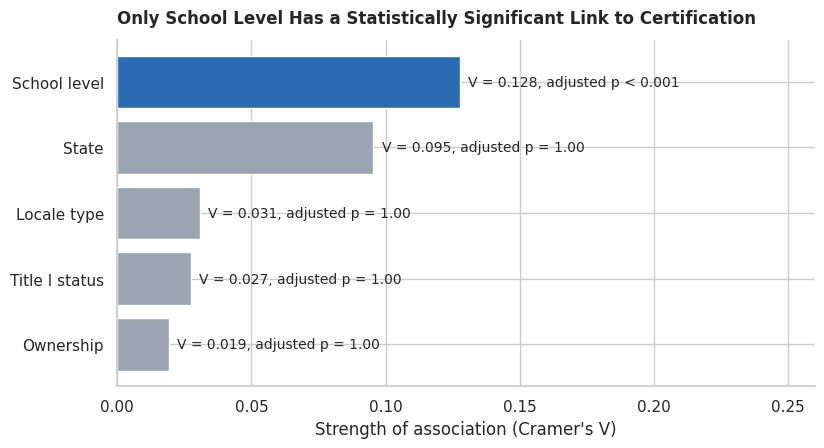

In [100]:
# let's visualize this

plot_data = family_table.sort_values('cramers_v')
colors = ['#2B6CB0' if sig else '#9AA5B1' for sig in plot_data['significant']]

plt.figure(figsize=(9, 4.5))
plt.barh(plot_data['variable'], plot_data['cramers_v'], color = colors)
for i, row in enumerate(plot_data.itertuples()):
    label = f"V = {row.cramers_v:.3f}, adjusted p {'< 0.001' if row.p_holm < 0.001 else '= ' + format(row.p_holm, '.2f')}"
    plt.text(row.cramers_v + 0.003, i, label, va='center', fontsize=10)

sns.despine()

plt.title('Only School Level Has a Statistically Significant Link to Certification',
          fontsize=12, fontweight='bold', loc='left', pad=12)
plt.xlabel("Strength of association (Cramer's V)")
plt.xlim(0, 0.26)
save_fig('14_category_associations')
plt.show();

**Business Translation: Ownership, Locale and State**

- **Only school level is significant.** After correcting for five tests, school level is the only category with a statistically significant link to certification (adjusted p < 0.001). Title I status (p = 0.288), ownership (p = 0.757), locale type (p = 0.684) and state (shuffle test p = 0.641) are not significant, and their effect sizes are tiny (Cramér's V of 0.019 to 0.031 for the first three).

- **State needs a caution.** State has a larger Cramér's V (0.095) only because it has 51 small groups, which produces larger values even from pure chance. The shuffle test, which accounts for the small groups, confirms that state differences are no larger than chance would give.

- **In plain terms:** where an institution is, who owns it and what Title I status it holds do not separate certified from non-certified institutions in this dataset.

**Question 4.**

*Do numeric characteristics differ between certified and non-certified K-12 schools, once level is allowed for?*

**Data involved:**
- One yes/no outcome and 12 numeric measures, several skewed or capped.

**Statistical Method:**
- Mann-Whitney test on values compared within each level, AUC effect size with bootstrap interval, Holm correction.

**Why this method:**
- Mann-Whitney does not assume a bell-shaped distribution, which suits skewed and capped data. Comparing values within each level stops the level pattern from showing up as a false link. AUC says how well one characteristic alone could separate the two groups (0.5 means not at all).

**Null hypothesis (H0):**

- For each characteristic, certified and non-certified K-12 schools have the same distribution of values, once school level is allowed for.

**Alternative hypothesis (H1):**

- The distributions differ.

**NB:**

- Each value is first converted into a score relative to its own school level (how far above or below the average for Elementary, Middle, High or K-12 Combined schools it sits).

- This prevents the level pattern, for example High Schools being larger and more often certified, from appearing as a link with enrollment.

In [101]:
# Let's define the numerical variables

numeric_cols = {'total_enrollment': 'Enrollment', 'student_teacher_ratio': 'Student-teacher ratio',
                'per_pupil_expenditure_usd': 'Per-pupil spending', 'percent_free_reduced_lunch': 'Free/reduced lunch share',
                'broadband_access_pct': 'Broadband access', 'federal_funding_pct': 'Federal funding share',
                'math_proficiency_pct': 'Math proficiency', 'reading_proficiency_pct': 'Reading proficiency',
                'graduation_rate_pct': 'Graduation rate', 'chronic_absenteeism_pct': 'Chronic absenteeism',
                'english_learner_pct': 'English-learner share', 'special_education_pct': 'Special-education share'}

outcome = k12['is_certified'].values
n_certified, n_not = int(outcome.sum()), int(len(outcome) - outcome.sum())

In [102]:
# Let's use a function to measure the probability
# that a randomly selected STEM-certified school has a higher value of a specific characteristic
# than a randomly selected non-certified school.

def auc_from_ranks(values, outcome):
    # AUC = chance that a randomly chosen certified school has a higher value than a randomly chosen non-certified one
    ranks = stats.rankdata(values)
    n1 = outcome.sum()
    n0 = len(outcome) - n1
    return (ranks[outcome == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

In [103]:
rows = []

for column, name in numeric_cols.items():
    within_level = k12.groupby('level')[column].transform(lambda s: (s - s.mean()) / s.std()).values
    raw_auc = auc_from_ranks(k12[column].values, outcome)
    adj_auc = auc_from_ranks(within_level, outcome)
    p = stats.mannwhitneyu(within_level[outcome == 1], within_level[outcome == 0], alternative='two-sided').pvalue

    boot = []
    for _ in range(1000):
        sample = rng.integers(0, len(outcome), len(outcome))
        boot.append(auc_from_ranks(within_level[sample], outcome[sample]))
    low, high = np.percentile(boot, [2.5, 97.5])
    rows.append({'characteristic': name, 'auc_unadjusted': raw_auc, 'auc_level_adjusted': adj_auc,
                 'ci_low': low, 'ci_high': high, 'p_value': p})

numeric_table = pd.DataFrame(rows).sort_values('p_value').reset_index(drop=True)
numeric_table['p_holm'] = holm_adjust(numeric_table['p_value'])
numeric_table['significant'] = numeric_table['p_holm'] < 0.05
numeric_table.round(3)

,characteristic,auc_unadjusted,auc_level_adjusted,ci_low,ci_high,p_value,p_holm,significant
0,Student-teacher ratio,0.477,0.474,0.451,0.496,0.030,0.364,False
1,Enrollment,0.571,0.520,0.497,0.544,0.088,0.973,False
2,Math proficiency,0.485,0.485,0.462,0.507,0.213,1.000,False
3,English-learner share,0.512,0.512,0.489,0.536,0.307,1.000,False
4,Chronic absenteeism,0.488,0.488,0.465,0.513,0.333,1.000,False
5,Graduation rate,0.491,0.493,0.472,0.518,0.571,1.000,False
6,Federal funding share,0.491,0.494,0.469,0.516,0.598,1.000,False
7,Special-education share,0.494,0.494,0.471,0.517,0.609,1.000,False
8,Reading proficiency,0.498,0.498,0.475,0.520,0.849,1.000,False
9,Free/reduced lunch share,0.499,0.501,0.477,0.527,0.960,1.000,False


In [104]:
for row in numeric_table.itertuples():
    results.append({'question': f'Certified vs not certified: {row.characteristic} (K-12, level-adjusted)',
                    'test': 'Mann-Whitney U', 'statistic': np.nan, 'p_value': row.p_value, 'p_adjusted': row.p_holm,
                    'effect_size': f"AUC = {row.auc_level_adjusted:.3f} (95% CI {row.ci_low:.3f} to {row.ci_high:.3f})"})

print(f"Tests run: {len(numeric_table)}\nsignificant before correction: {(numeric_table['p_value'] < 0.05).sum()} "
      f"\nsignificant after Holm correction: {numeric_table['significant'].sum()}")
print(f"Chance of at least one p < 0.05 among {len(numeric_table)} tests when nothing is going on: "
      f"{1 - (1 - 0.05) ** len(numeric_table):.0%}")

Tests run: 12
significant before correction: 1 
significant after Holm correction: 0
Chance of at least one p < 0.05 among 12 tests when nothing is going on: 46%


In [105]:
# How big a difference could these tests have detected?

detectable_d = (stats.norm.ppf(1 - 0.05 / 2) + stats.norm.ppf(0.80)) * np.sqrt(1 / n_certified + 1 / n_not)
detectable_auc = stats.norm.cdf(detectable_d / np.sqrt(2))

print(f"\nWith {n_certified} certified and {n_not:,} non-certified K-12 schools, a single test detects a difference of about "
      f"{detectable_d:.2f} standard deviations (AUC about {detectable_auc:.3f}) 80% of the time.")


With 689 certified and 3,953 non-certified K-12 schools, a single test detects a difference of about 0.12 standard deviations (AUC about 0.533) 80% of the time.


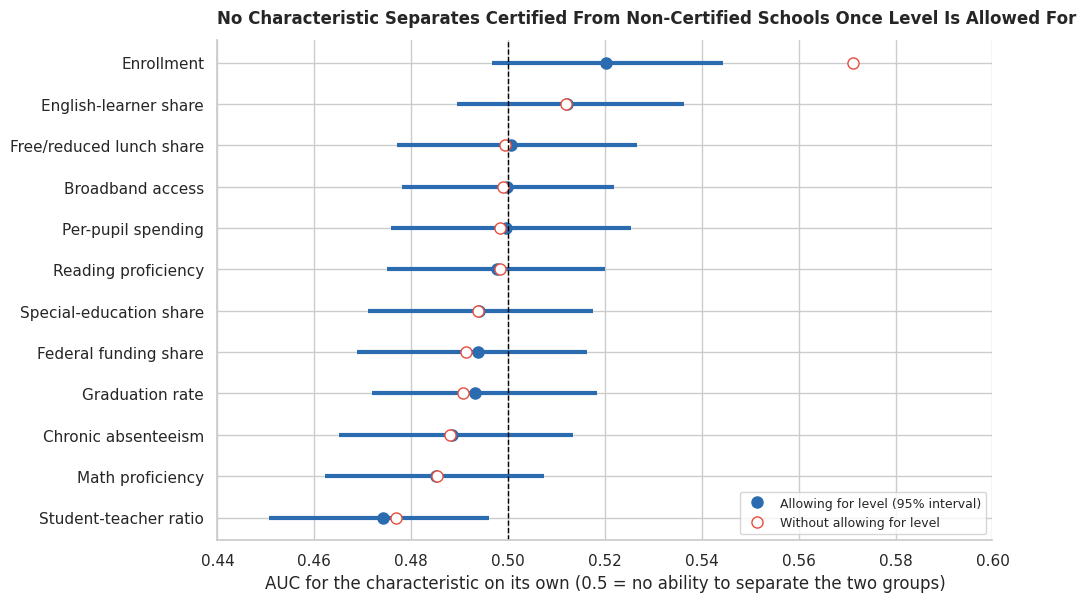

In [106]:
# Let's visualize this

plot_data = numeric_table.sort_values('auc_level_adjusted').reset_index(drop=True)
y_positions = np.arange(len(plot_data))

plt.figure(figsize=(10, 6.5))
plt.hlines(y_positions, plot_data['ci_low'], plot_data['ci_high'], color = '#2B6CB0', linewidth = 3)
plt.plot(plot_data['auc_level_adjusted'], y_positions, 'o', color = '#2B6CB0', markersize=8, label='Allowing for level (95% interval)')
plt.plot(plot_data['auc_unadjusted'], y_positions, 'o', markerfacecolor='white', markeredgecolor = '#E74C3C',
         markersize=8, label='Without allowing for level')
plt.axvline(0.5, color='black', linestyle='--', linewidth=1)
plt.yticks(y_positions, plot_data['characteristic'])
plt.xlim(0.44, 0.60)

sns.despine()

plt.title('No Characteristic Separates Certified From Non-Certified Schools Once Level Is Allowed For',
          fontsize=12, fontweight='bold', loc='left', pad=12)
plt.xlabel('AUC for the characteristic on its own (0.5 = no ability to separate the two groups)')
plt.legend(loc='lower right', fontsize=9)
save_fig('15_numeric_characteristics_auc')
plt.show();

**Business Translation: Numeric Characteristics**

- **None of the 12 characteristics is significantly related to certification** once level is allowed for and the 12 tests are corrected (every adjusted p-value is 0.36 or higher).

- **Effect sizes are close to nothing.** Used on its own, every characteristic gives an AUC between 0.47 and 0.52, where 0.5 means no ability at all to tell certified from non-certified schools.

- **One nominal result is expected by chance.** Student-teacher ratio has an unadjusted p-value of 0.030, but running 12 tests gives a 46% chance of at least one such result when nothing is going on, and it does not survive correction (adjusted p = 0.364). Its effect is also tiny (AUC 0.474).

- **Enrollment shows how level can mislead.** Without allowing for level, enrollment looks informative (AUC 0.571) because High Schools are larger and more often certified. After allowing for level, it falls to 0.520 and is not significant.

- **These tests were sensitive enough.** With 689 certified and 3,953 non-certified K-12 schools, a single test could detect a difference of about 0.12 standard deviations (AUC about 0.53) 80% of the time. Any real effect of one characteristic on its own is therefore smaller than that. Characteristics could still add a little when combined in a model, which the next stage will test.

- **Not significant is not the same as proven absent.** The result says these characteristics carry little information about certification in this dataset. It does not say they could never matter for certification in the real world.

**Question 5.**

*Do spending and broadband still relate to math proficiency once lunch share is held fixed?*

**Data Involved:**
- Numeric measures

**Statistical method:**
- Partial Spearman correlation with bootstrap confidence interval.

**Why this method:**
- Confirms the finding in the EDA with an interval, so we can see how precisely it is estimated.

**Null hypothesis (H0):**

- once free/reduced lunch share is held fixed, there is no relationship.

**Alternative hypothesis (H1):**

- A relationship remains.

In [107]:
# Let's create a partial Spearman's correlation function

def partial_spearman_from_arrays(x, y, control):
    # Rank all three variables and remove what the control explains from both x and y, and correlate what is left
    rx, ry, rc = stats.rankdata(x), stats.rankdata(y), stats.rankdata(control)
    design = np.column_stack([np.ones(len(rc)), rc])
    resid_x = rx - design @ np.linalg.lstsq(design, rx, rcond=None)[0]
    resid_y = ry - design @ np.linalg.lstsq(design, ry, rcond=None)[0]
    return np.corrcoef(resid_x, resid_y)[0, 1]

In [108]:
math = k12['math_proficiency_pct'].values
lunch = k12['percent_free_reduced_lunch'].values
partial_rows = []

for column, name in [('per_pupil_expenditure_usd', 'Per-pupil spending'), ('broadband_access_pct', 'Broadband access'),
                     ('federal_funding_pct', 'Federal funding share'), ('student_teacher_ratio', 'Student-teacher ratio')]:
    values = k12[column].values
    raw = stats.spearmanr(values, math)[0]
    adjusted = partial_spearman_from_arrays(values, math, lunch)

    boot = []
    for _ in range(1000):
        sample = rng.integers(0, len(math), len(math))
        boot.append(partial_spearman_from_arrays(values[sample], math[sample], lunch[sample]))
    low, high = np.percentile(boot, [2.5, 97.5])
    partial_rows.append({'driver': name, 'raw_correlation': raw, 'after_lunch_share': adjusted,
                         'ci_low': low, 'ci_high': high, 'interval_includes_zero': low <= 0 <= high})

partial_table = pd.DataFrame(partial_rows)

for row in partial_table.itertuples():
    results.append({'question': f'{row.driver} vs math proficiency, holding lunch share fixed (K-12)',
                    'test': 'Partial Spearman correlation (bootstrap CI)', 'statistic': round(row.after_lunch_share, 3),
                    'p_value': np.nan, 'effect_size': f"95% CI {row.ci_low:.3f} to {row.ci_high:.3f}"})
partial_table.round(3)

,driver,raw_correlation,after_lunch_share,ci_low,ci_high,interval_includes_zero
0,Per-pupil spending,0.269,0.178,0.151,0.205,False
1,Broadband access,0.438,0.000,-0.029,0.032,True
2,Federal funding share,-0.490,-0.006,-0.036,0.023,True
3,Student-teacher ratio,-0.114,0.011,-0.017,0.042,True


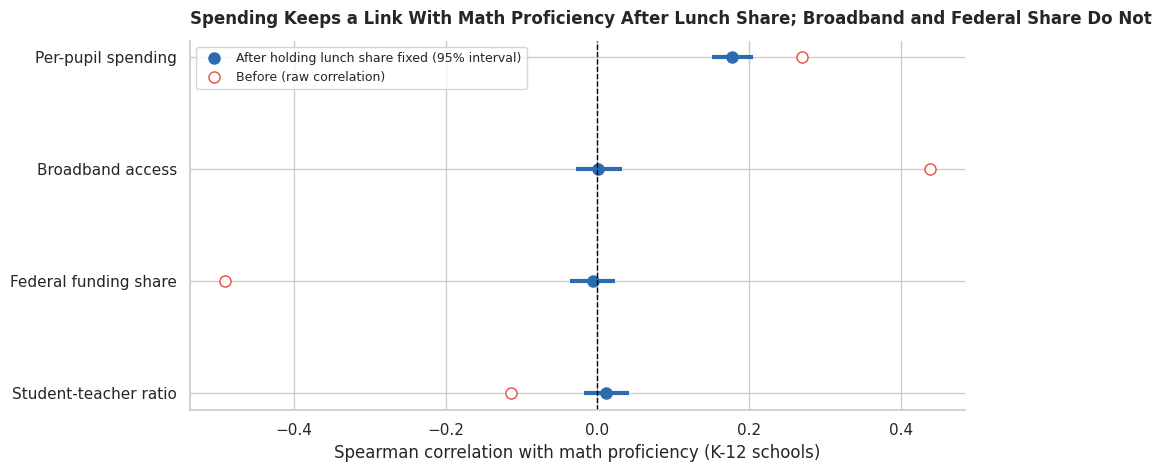

In [109]:
# Let's make a plot for the above

plot_data = partial_table.iloc[::-1].reset_index(drop=True)
y_positions = np.arange(len(plot_data))

plt.figure(figsize=(10, 4.8))
plt.hlines(y_positions, plot_data['ci_low'], plot_data['ci_high'], color = '#2B6CB0', linewidth = 3)
plt.plot(plot_data['after_lunch_share'], y_positions, 'o', color ='#2B6CB0', markersize=8, label = 'After holding lunch share fixed (95% interval)')
plt.plot(plot_data['raw_correlation'], y_positions, 'o', markerfacecolor = 'white', markeredgecolor = '#E74C3C', markersize = 8,
         label='Before (raw correlation)')
plt.axvline(0, color = 'black', linestyle = '--', linewidth = 1)
plt.yticks(y_positions, plot_data['driver'])

sns.despine()

plt.title('Spending Keeps a Link With Math Proficiency After Lunch Share; Broadband and Federal Share Do Not',
          fontsize = 12, fontweight = 'bold', loc = 'left', pad = 12)
plt.xlabel('Spearman correlation with math proficiency (K-12 schools)')
plt.legend(loc = 'upper left', fontsize = 9)
save_fig('16_partial_correlations')
plt.show();

**Business Translation: Spending, Broadband and Math Proficiency**

- **Spending keeps a real but smaller link.** The correlation between per-pupil spending and math proficiency falls from 0.27 to 0.18 after lunch share is held fixed, and its 95% interval (about 0.15 to 0.20) stays well above zero.

- **Broadband and federal funding share lose their link.** Broadband falls from 0.44 to 0.00 and federal funding share from -0.49 to -0.01. Their intervals include zero, so once lunch share is known they add no detectable information about math proficiency. Student-teacher ratio also has an interval that includes zero.

- **This is an association, not a cause.** It does not show that raising spending would raise proficiency.

- **Why it matters for the project:** this confirms that several candidate features share one underlying signal (lunch share).

In [110]:
# What the statistics mean for our prediction model
# It should be able to answer:
# How well could a model that knows ONLY school level separate certified from non-certified institutions?
# Let's  give every institution the certification rate of its level
# and measure how well that score ranks institutions (AUC).

level_rate = cleaned_data.groupby('level')['is_certified'].transform('mean')
level_only_auc = roc_auc_score(cleaned_data['is_certified'], level_rate)

print(f"AUC of a level-only score: {level_only_auc:.3f}  (0.5 = no better than guessing)")

AUC of a level-only score: 0.585  (0.5 = no better than guessing)


In [111]:
# For comparison:
# the best single numeric characteristic is
# level-adjusted (distance from 0.5 in either direction)

best = numeric_table.loc[(numeric_table['auc_level_adjusted'] - 0.5).abs().idxmax()]
print(f"Strongest single numeric characteristic after allowing for level: {best['characteristic']} "
      f"(AUC {best['auc_level_adjusted']:.3f})")

results.append({'question': 'Ability of school level alone to rank institutions by certification', 'test': 'AUC of level-rate score',
                'statistic': round(level_only_auc, 3), 'p_value': np.nan, 'effect_size': 'Baseline for the modelling stage'})

Strongest single numeric characteristic after allowing for level: Student-teacher ratio (AUC 0.474)


**Business Translation: Implications for the Model**

- **School level is the only statistically supported signal.** A score that uses nothing but school level already reaches an AUC of 0.585. This is a modest result, because even the one real pattern leaves most of the variation between institutions unexplained: about 22% of High Schools and 4-Year Universities are certified, so most institutions in the two highest-rate levels are still not certified.

- **Other characteristics add little on their own.** The strongest single numeric characteristic gives an AUC of 0.52 once level is allowed for. Combining many weak characteristics might add something, but the tests give no reason to expect a large gain.

- **What we will do in the modelling stage:** build a level-only baseline first, compare the full model against it, and report honestly how much the other characteristics add. A model that barely beats the level-only baseline is a legitimate finding about this dataset, not a failed project.

- **Accuracy will be a poor measure.** With 15.0% certified, predicting "not certified" for every institution would be right 85% of the time, so the model will be judged on precision, recall, F1-score and ROC-AUC.

In [112]:
# Let's save every result for the final report

results_table = pd.DataFrame(results)
for column in ['p_value', 'p_adjusted']:
    results_table[column] = results_table[column].apply(lambda p: '' if pd.isna(p) else format_p(p))
results_table.to_csv('/content/drive/MyDrive/AltSchool_Africa/4th_Semester/statistical_results.csv', index=False)
print(f"Saved {len(results_table)} results to reports/statistical_results.csv")
results_table[['question', 'test', 'p_value', 'p_adjusted', 'effect_size']]

Saved 28 results to reports/statistical_results.csv


,question,test,p_value,p_adjusted,effect_size
0,NaN,NaN,,,NaN
1,NaN,NaN,,,NaN
2,NaN,NaN,,,NaN
3,"Certification vs Title I status, allowing for ...",Likelihood-ratio test,0.556,,n/a
4,"Certification vs Title I status, public and ch...",Chi-square (3 groups),0.268,,Cramer's V = 0.026
5,Certification: High School + 4-Year University...,Bootstrap interval for difference,,,Gap 10.1 points (95% CI 7.7 to 12.5); ratio 1.83
6,Certification vs Title I status,Chi-square,0.288,1.000,Cramer's V = 0.027
7,Certification vs School level,Chi-square,< 0.001,< 0.001,Cramer's V = 0.128
8,Certification vs Ownership,Chi-square,0.757,1.000,Cramer's V = 0.019
9,Certification vs Locale type,Chi-square,0.684,1.000,Cramer's V = 0.031


**What was found:**

- **School level is the only characteristic with a statistically significant link to STEM certification** (p < 0.001, Cramér's V = 0.128). High Schools and 4-Year Universities are certified at 22.3% against 12.2% for the other levels, a gap of 10.1 percentage points (95% interval 7.8 to 12.5).

- **Title I status, ownership, locale and state show no link** after correcting for multiple tests, and their effect sizes are tiny. The Title I result holds after allowing for school level.

- **None of 12 numeric characteristics separates certified from non-certified K-12 schools** once level is allowed for. Each has an AUC between 0.47 and 0.52 on its own, and none is significant after correction.

- **Spending keeps a small positive link with math proficiency** once lunch share is held fixed, while broadband and federal funding share do not.

**Machine Learning**

*Phase 1: Frame the problem*

**Problem Type:**
- Binary classification. certified (1) or not (0)

**Objective:**
- Rank and flag institutions by their chance of being STEM-certified, using only institutional characteristics

**Primary Metrics:**
- ROC-AUC (how well the model ranks certified above non-certified) and PR-AUC (how well it finds the rare certified cases)

**Metrics at a threshold**
- Accuracy, precision, recall, F1 and the confusion matrix

**Why not Accuracy:**
- 85% of institutions are not certified, so a model that predicts "never certified" scores 85% accuracy and finds nothing.

**Baselines:**
1. Dummy model that always gives the base rate
2. logistic regression on school level only

**Minimum useful result:**
- The final model must beat the level-only baseline by more than chance. Beating a dummy model is not enough, because level is already known.

**Assumptions:**
- Institutions are treated as independent, and the cleaned data are treated as accurate.
- The cost of a missed certified institution versus a false alarm has not been given, so the threshold uses F1 as a neutral balance.

*Phase 2: Get the data and set the test set aside.*

- The data are split 80/20 with stratification, so both parts keep the same share of certified institutions.

- The test set is not used for any choice (features, models, settings or threshold) until the single final evaluation.

- All comparisons below use repeated cross-validation on the training set only.


**Leakage policy.**

*The main models use only the characteristics named in the problem definition. These columns are excluded:*

- Identifiers
- State and county (we found no link with certification, and 51 states with 4,000 rows invite overfitting).
- Academic outcomes (proficiency, graduation, absenteeism) and readiness measures (SAT, ACT, AP/IB, post-secondary enrollment). A certified school might raise these, so using them to predict certification would mix cause and effect. They will be tested separately.
- One column from each set that sums to 100 (race shares, funding shares), to avoid redundant inputs.

In [113]:
TARGET = "is_certified"
SEED = 42

CATEGORICAL = ["level", "control", "title_i_status", "nces_locale"]

NUMERIC = [
    "total_enrollment", "number_of_teachers", "student_teacher_ratio",
    "percent_free_reduced_lunch",
    "racial_white_pct", "racial_black_pct", "racial_hispanic_pct", "racial_asian_pct", "racial_native_pct",
    "special_education_pct", "english_learner_pct",
    "per_pupil_expenditure_usd", "federal_funding_pct", "state_funding_pct",
    "broadband_access_pct",
]

In [114]:
# Skewed counts and spending: log-transformed (helps linear models; trees are unaffected)

LOG_COLUMNS = ["total_enrollment", "number_of_teachers", "per_pupil_expenditure_usd"]

# Groups used to ask "which kind of characteristic contributes most?"

FEATURE_GROUPS = {
    "School level": ["level"],
    "Ownership": ["control"],
    "Title I status": ["title_i_status"],
    "Locale type": ["nces_locale"],
    "Size and staffing": ["total_enrollment", "number_of_teachers", "student_teacher_ratio"],
    "Socioeconomic (lunch share)": ["percent_free_reduced_lunch"],
    "Student needs": ["special_education_pct", "english_learner_pct"],
    "Demographics": ["racial_white_pct", "racial_black_pct", "racial_hispanic_pct",
                     "racial_asian_pct", "racial_native_pct"],
    "Funding": ["per_pupil_expenditure_usd", "federal_funding_pct", "state_funding_pct"],
    "Broadband access": ["broadband_access_pct"],
}

ALL_FEATURES = CATEGORICAL + NUMERIC
REDUCED_FEATURES = ["level"] + FEATURE_GROUPS["Size and staffing"]

# Columns kept out of the main models

EXCLUDED = {
    "institution_id, institution_name": "identifiers",
    "state_code, state_name, county": "location; no link to certification found and 51 states invite overfitting",
    "math_proficiency_pct, reading_proficiency_pct, graduation_rate_pct, chronic_absenteeism_pct":
        "academic outcomes that could follow from certification (tested separately as a sensitivity check)",
    "avg_sat_score, avg_act_score, ap_ib_participation_pct, postsecondary_enrollment_pct":
        "readiness measures that could follow from certification and exist only for some levels (tested separately)",
    "racial_two_or_more_pct, local_funding_pct": "dropped because each set adds up to 100 with the others",
}

In [115]:
def load_and_split(data, test_size = 0.2, seed = SEED):
    """Read the cleaned data and return a stratified train/test split of ALL columns.

    The test set is put aside here and is not used again until the final evaluation.
    """
    train, test = train_test_split(data, test_size = test_size, stratify = data[TARGET], random_state = seed)
    return train.reset_index(drop = True), test.reset_index(drop = True)

In [116]:
model_data = cleaned_data.copy()
train, test = load_and_split(model_data)
y_train, y_test = train[TARGET], test[TARGET]

summary = pd.DataFrame({'rows': [len(train), len(test)],
                        'certified': [int(y_train.sum()), int(y_test.sum())],
                        'certified %': [round(100*y_train.mean(), 2), round(100*y_test.mean(), 2)]},
                       index=['Training set', 'Test set (set aside)'])
print(summary)
print()
print('Features used in the main models:', len(ALL_FEATURES))
for cols, why in EXCLUDED.items():
    print(f'  Excluded: {cols}\n      reason: {why}')

                      rows  certified  certified %
Training set          4000        602        15.05
Test set (set aside)  1000        150        15.00

Features used in the main models: 19
  Excluded: institution_id, institution_name
      reason: identifiers
  Excluded: state_code, state_name, county
      reason: location; no link to certification found and 51 states invite overfitting
  Excluded: math_proficiency_pct, reading_proficiency_pct, graduation_rate_pct, chronic_absenteeism_pct
      reason: academic outcomes that could follow from certification (tested separately as a sensitivity check)
  Excluded: avg_sat_score, avg_act_score, ap_ib_participation_pct, postsecondary_enrollment_pct
      reason: readiness measures that could follow from certification and exist only for some levels (tested separately)
  Excluded: racial_two_or_more_pct, local_funding_pct
      reason: dropped because each set adds up to 100 with the others


*Phase 3: Prepare the data*

In [117]:
# Create a function for the preprocessor

def build_preprocessor(categorical, numeric, scale = True):
    """Preparation steps for the chosen columns.

    Categories -> one-hot encoding. Numbers -> median fill (only a safeguard here, as these
    columns have no gaps), log transform for skewed columns, optional standardisation.
    """
    transformers = []
    if categorical:
        transformers.append(("cat", OneHotEncoder(handle_unknown = "ignore"), list(categorical)))

    log_cols = [c for c in numeric if c in LOG_COLUMNS]
    plain_cols = [c for c in numeric if c not in LOG_COLUMNS]

    def number_steps(with_log):
        steps = [("fill", SimpleImputer(strategy="median"))]
        if with_log:
            steps.append(("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")))
        if scale:
            steps.append(("scale", StandardScaler()))
        return Pipeline(steps)

    if log_cols:
        transformers.append(("log", number_steps(True), log_cols))
    if plain_cols:
        transformers.append(("num", number_steps(False), plain_cols))
    return ColumnTransformer(transformers)

In [118]:
# create a function for the ML pipeline

def make_pipeline(model, features = None, scale = True):
    """Preparation + model in one object, so nothing from the test data leaks into training."""
    features = features or ALL_FEATURES
    categorical = [c for c in features if c in CATEGORICAL]
    numeric = [c for c in features if c in NUMERIC or c not in CATEGORICAL]
    return Pipeline([("prep", build_preprocessor(categorical, numeric, scale)), ("model", model)])

*Phase 4: Shortlist promising models*

In [119]:
# 15 folds
cv = RepeatedStratifiedKFold(n_splits = 5, n_repeats = 3, random_state = 42)
K, TEST_FRACTION = 15, 0.25

# for the corrected paired test (1 fold test / 4 folds train = 0.25)
def corrected_paired_test(a, b):
    # Nadeau-Bengio corrected resampled t-test.
    # Plain paired t-tests on CV folds are too optimistic
    # because the folds share training data.
    d = np.asarray(a) - np.asarray(b)
    if d.std(ddof = 1) == 0:
        return d.mean(), np.nan, np.nan
    t = d.mean() / np.sqrt((1/K + TEST_FRACTION) * d.var(ddof = 1))
    return d.mean(), t, 2*(1 - stats.t.cdf(abs(t), K-1))

def run_cv(model, features, X = None, y = None):
    X = train if X is None else X
    y = y_train if y is None else y
    r = cross_validate(model, X[features], y, cv=cv, scoring=['roc_auc', 'average_precision'], n_jobs=1)
    return r['test_roc_auc'], r['test_average_precision']

cv_auc, cv_ap = {}, {}
def evaluate(name, model, features):
    t0 = time.time()
    cv_auc[name], cv_ap[name] = run_cv(model, features)
    print(f'{name:<38s} AUC {cv_auc[name].mean():.3f} (SD {cv_auc[name].std():.3f}) PR-AUC {cv_ap[name].mean():.3f}   [{time.time()-t0:.0f}s]')

In [120]:
LEVEL = ['level']
candidates = {
    'Dummy (always the base rate)':  (DummyClassifier(strategy = 'prior'), LEVEL, True),
    'Level-only logistic (baseline)': (LogisticRegression(max_iter = 2000), LEVEL, True),
    'Logistic regression (all features)': (LogisticRegression(max_iter = 2000), ALL_FEATURES, True),
    'Logistic, balanced class weights': (LogisticRegression(max_iter = 2000, class_weight = 'balanced'), ALL_FEATURES, True),
    'Decision tree (depth 4)': (DecisionTreeClassifier(max_depth = 4, min_samples_leaf = 30, random_state = 42), ALL_FEATURES, False),
    'Random forest (min leaf 20)': (RandomForestClassifier(n_estimators = 300, min_samples_leaf = 20, n_jobs = -1, random_state = 42), ALL_FEATURES, False),
    'Random forest (defaults)': (RandomForestClassifier(n_estimators = 300, n_jobs = -1, random_state = 42), ALL_FEATURES, False),
    'Gradient boosting (shallow)': (GradientBoostingClassifier(n_estimators = 100, max_depth = 2, learning_rate = 0.05, random_state = 42), ALL_FEATURES, False),
}

for name, (model, feats, scale) in candidates.items():
    evaluate(name, make_pipeline(model, feats, scale = scale), feats)

base = cv_auc['Level-only logistic (baseline)']
rows = []
for name in candidates:
    diff, t, p = corrected_paired_test(cv_auc[name], base)
    rows.append({'Model': name, 'CV ROC-AUC': round(cv_auc[name].mean(), 3), 'SD': round(cv_auc[name].std(), 3),
                 'CV PR-AUC': round(cv_ap[name].mean(), 3),
                 'AUC vs level-only': round(diff, 3), 'corrected p': 'baseline' if name.startswith('Level-only') else round(p, 3)})

shortlist_table = pd.DataFrame(rows)
shortlist_table

Dummy (always the base rate)           AUC 0.500 (SD 0.000) PR-AUC 0.151   [0s]
Level-only logistic (baseline)         AUC 0.567 (SD 0.028) PR-AUC 0.183   [1s]
Logistic regression (all features)     AUC 0.573 (SD 0.028) PR-AUC 0.201   [4s]
Logistic, balanced class weights       AUC 0.574 (SD 0.027) PR-AUC 0.202   [1s]
Decision tree (depth 4)                AUC 0.548 (SD 0.025) PR-AUC 0.175   [1s]
Random forest (min leaf 20)            AUC 0.564 (SD 0.026) PR-AUC 0.194   [33s]
Random forest (defaults)               AUC 0.534 (SD 0.024) PR-AUC 0.177   [49s]
Gradient boosting (shallow)            AUC 0.563 (SD 0.023) PR-AUC 0.185   [19s]


,Model,CV ROC-AUC,SD,CV PR-AUC,AUC vs level-only,corrected p
0,Dummy (always the base rate),0.500,0.000,0.151,-0.067,0.001
1,Level-only logistic (baseline),0.567,0.028,0.183,0.000,baseline
2,Logistic regression (all features),0.573,0.028,0.201,0.006,0.615
3,"Logistic, balanced class weights",0.574,0.027,0.202,0.006,0.612
4,Decision tree (depth 4),0.548,0.025,0.175,-0.019,0.379
5,Random forest (min leaf 20),0.564,0.026,0.194,-0.003,0.876
6,Random forest (defaults),0.534,0.024,0.177,-0.033,0.075
7,Gradient boosting (shallow),0.563,0.023,0.185,-0.004,0.79


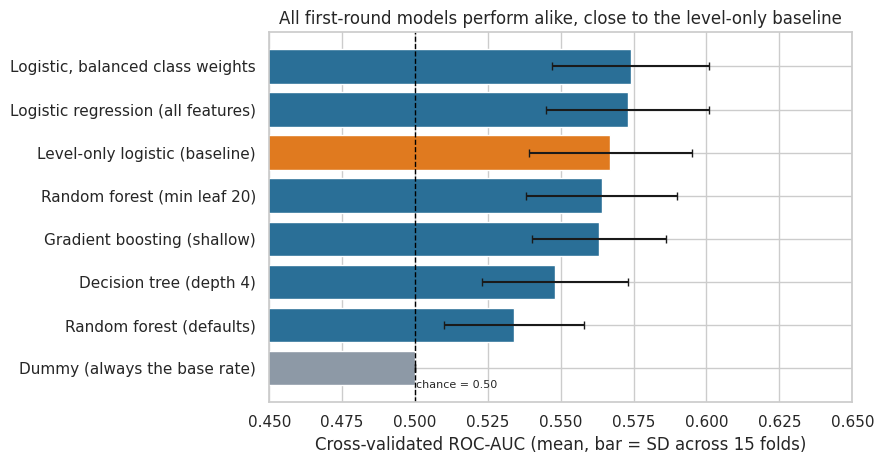

In [121]:
# let's visualize this
order = shortlist_table.sort_values('CV ROC-AUC')

fig, ax = plt.subplots(figsize=(9, 4.8))
colors = ['#e07a1f' if 'baseline' in m else ('#8d99a6' if 'Dummy' in m else '#2a6f97') for m in order['Model']]
ax.barh(order['Model'], order['CV ROC-AUC'], xerr = order['SD'], color = colors, capsize = 3)
ax.axvline(0.5, color='black', lw=1, ls='--'); ax.text(0.5005, -0.45, 'chance = 0.50', fontsize = 8)
ax.set_xlim(0.45, 0.65)
ax.set_xlabel('Cross-validated ROC-AUC (mean, bar = SD across 15 folds)')
ax.set_title('All first-round models perform alike, close to the level-only baseline')
plt.tight_layout();
plt.savefig(f'/content/drive/MyDrive/AltSchool_Africa/4th_Semester/model_shortlist.png', bbox_inches = 'tight');
plt.show()

**What the shortlist shows:**

- Every model scores between 0.53 and 0.57 ROC-AUC. Chance is 0.50.
- The level-only baseline (0.567) is already as good as nearly everything else. The full logistic regression (0.573) is not significantly better than it (corrected p = 0.615).
- More flexible models did not help: the untuned random forest is worse (0.534) and the shallow boosting model is level with the baseline (0.564).
- Balancing the class weights changed nothing meaningful (0.574 versus 0.573).

**Business translation:** a model that uses every characteristic is barely better than one that knows only the school level. The extra characteristics add little predictive information.

**Error and feature analysis:**

In [122]:
# Feature selection / error analysis:
# what does each group of features add on top of school level?

def group_features(extra_cols):
    return ['level'] + [c for c in extra_cols if c != 'level']

group_rows = []
for g, cols in FEATURE_GROUPS.items():
    if g == 'School level':
        continue
    feats = group_features(cols)
    a, _ = run_cv(make_pipeline(LogisticRegression(max_iter = 2000), feats), feats)
    diff, t, p = corrected_paired_test(a, base)
    group_rows.append({'Level plus': g, 'CV ROC-AUC': round(a.mean(), 3), 'Gain over level-only': round(diff, 3), 'corrected p': round(p, 3)})

group_table = pd.DataFrame(group_rows).sort_values('Gain over level-only', ascending = False).reset_index(drop = True)
group_table['p after Holm (9 tests)'] = np.minimum(1, (group_table['corrected p'].rank(method='first').rsub(len(group_table)+1)) * group_table['corrected p']).round(3)

# proper Holm: sort ascending p, multiply by (m - rank), enforce monotone
ps = group_table['corrected p'].values; m = len(ps); idx = np.argsort(ps); holm = np.empty(m); run = 0
for r, i in enumerate(idx):
    run = max(run, min(1, (m - r) * ps[i])); holm[i] = run
group_table['p after Holm (9 tests)'] = holm.round(3)
group_table

,Level plus,CV ROC-AUC,Gain over level-only,corrected p,p after Holm (9 tests)
0,Size and staffing,0.587,0.020,0.008,0.072
1,Student needs,0.579,0.012,0.207,1.000
2,Demographics,0.573,0.006,0.414,1.000
3,Title I status,0.573,0.006,0.347,1.000
4,Socioeconomic (lunch share),0.567,-0.000,0.950,1.000
5,Broadband access,0.564,-0.003,0.610,1.000
6,Funding,0.562,-0.005,0.349,1.000
7,Ownership,0.561,-0.006,0.319,1.000
8,Locale type,0.558,-0.009,0.255,1.000


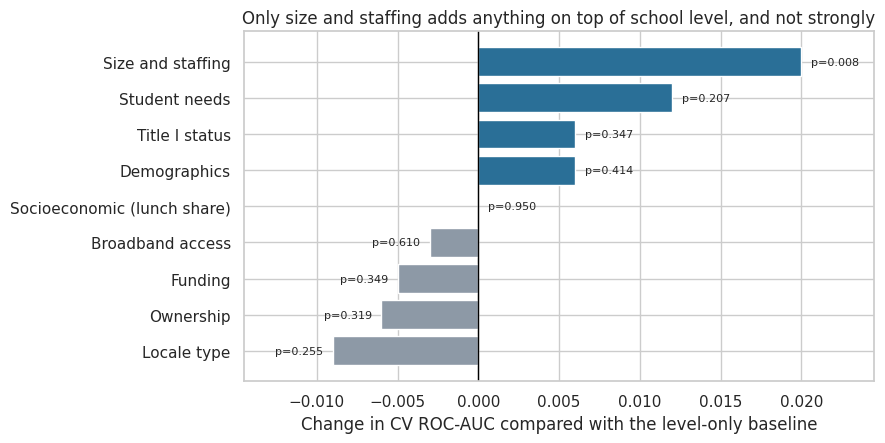

In [123]:
# let's visualize this
g = group_table.sort_values('Gain over level-only')

fig, ax = plt.subplots(figsize = (9, 4.6))
ax.barh(g['Level plus'], g['Gain over level-only'], color = ['#2a6f97' if v > 0 else '#8d99a6' for v in g['Gain over level-only']])
ax.axvline(0, color = 'black', lw = 1)
for i, (v, p) in enumerate(zip(g['Gain over level-only'], g['corrected p'])):
    ax.text(v + (0.0006 if v >= 0 else -0.0006), i, f'p={p:.3f}', va='center', ha='left' if v >= 0 else 'right', fontsize=8)

ax.set_xlim(-0.0145, 0.0245);
ax.set_xlabel('Change in CV ROC-AUC compared with the level-only baseline')
ax.set_title('Only size and staffing adds anything on top of school level, and not strongly')
plt.tight_layout();
plt.savefig(f'/content/drive/MyDrive/AltSchool_Africa/4th_Semester/feature_group_gain.png', bbox_inches = 'tight');
plt.show();

**Reading the table:**

- Size and staffing (enrollment, number of teachers, student-teacher ratio) is the only group with a gain that is nominally significant: +0.020 AUC, corrected p = 0.008. After correcting for nine groups the p-value is 0.072, so it is **suggestive, not confirmed**.

- No other group adds a measurable amount. Funding, ownership and locale type are slightly below the baseline, which is what pure noise looks like.


In [124]:
# L1 (lasso) logistic regression as a second view of feature selection
# Which shrinks unhelpful coefficients to zero

l1_rows = []
for Cval in [0.01, 0.03, 0.1, 0.3]:
    pipe = make_pipeline(LogisticRegression(penalty = 'l1', solver = 'liblinear', C = Cval, max_iter = 3000), ALL_FEATURES)
    a, _ = run_cv(pipe, ALL_FEATURES)
    pipe.fit(train[ALL_FEATURES], y_train)
    names = pipe['prep'].get_feature_names_out(); coef = pipe['model'].coef_[0]
    kept = [n.split('__')[1] for n, c in zip(names, coef) if abs(c) > 1e-8]
    l1_rows.append({'C (smaller = stronger penalty)': Cval, 'CV ROC-AUC': round(a.mean(), 3), 'columns kept': len(kept), 'examples kept': ', '.join(kept[:6])})

pd.DataFrame(l1_rows)

,C (smaller = stronger penalty),CV ROC-AUC,columns kept,examples kept
0,0.01,0.528,1,number_of_teachers
1,0.03,0.577,5,"level_High School, number_of_teachers, racial_..."
2,0.10,0.580,13,"level_High School, level_Middle School, title_..."
3,0.30,0.577,21,"level_2-Year College, level_Elementary School,..."


The lasso agrees in direction: with a strong penalty the single column it keeps is `number_of_teachers`, and the best AUC (0.580 at C = 0.1) is no better than the simpler size-plus-level model found above.

**Business translation:** the only characteristic beyond school level with any sign of predictive value is institution size, and even that evidence is weak.

*Phase 5: Fine-Tiune the Models*

- Three model families are tuned with randomised search (5-fold cross-validation, ROC-AUC): logistic regression (strength of regularisation), random forest and gradient boosting.

- Random search is used because it explores the settings more efficiently than a grid.

- A soft-voting ensemble of the three tuned models is added, and the reduced logistic model is tested with the same regularisation strength.


In [125]:
cv5 = StratifiedKFold(5, shuffle = True, random_state = 42)
searches = {
    'Logistic regression (tuned)': (make_pipeline(LogisticRegression(max_iter = 3000), ALL_FEATURES, True),
                                    {'model__C': loguniform(1e-3, 1e2)}, 15),
    'Random forest (tuned)': (make_pipeline(RandomForestClassifier(n_estimators = 200, n_jobs = -1, random_state = 42), ALL_FEATURES, False),
                              {'model__min_samples_leaf': randint(10, 80), 'model__max_depth': [3, 5, 8, None],
                               'model__max_features': ['sqrt', 0.3, 0.5]}, 12),
    'Gradient boosting (tuned)': (make_pipeline(GradientBoostingClassifier(random_state = 42), ALL_FEATURES, False),
                                  {'model__n_estimators': randint(30, 250), 'model__learning_rate': loguniform(0.01, 0.2),
                                   'model__max_depth': randint(1, 4), 'model__subsample': uniform(0.5, 0.5),
                                   'model__min_samples_leaf': randint(10, 80)}, 12),
}

tuned = {}

for name, (pipe, dist, n_iter) in searches.items():
    t0 = time.time()
    s = RandomizedSearchCV(pipe, dist, n_iter = n_iter, scoring = 'roc_auc', cv=cv5, random_state=42, n_jobs=1).fit(train[ALL_FEATURES], y_train)
    tuned[name] = s.best_estimator_
    params = {k.replace('model__', ''): (round(v, 4) if isinstance(v, float) else v) for k, v in s.best_params_.items()}
    print(f'{name:<30s} search AUC {s.best_score_:.3f}  {params}  [{time.time()-t0:.0f}s]')

Logistic regression (tuned)    search AUC 0.575  {'C': np.float64(0.0115)}  [10s]
Random forest (tuned)          search AUC 0.574  {'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 58}  [98s]
Gradient boosting (tuned)      search AUC 0.576  {'learning_rate': np.float64(0.0131), 'max_depth': 2, 'min_samples_leaf': 60, 'n_estimators': 137, 'subsample': np.float64(0.7571)}  [75s]


In [126]:
# Candidates for the final choice
# (all scored on the SAME 15 folds so they can be compared fairly)

final_pool = {}
for name, est in tuned.items():
    final_pool[name] = (est, ALL_FEATURES)

final_pool['Soft-voting ensemble (LR + RF + GB)'] = (
    VotingClassifier([('lr', tuned['Logistic regression (tuned)']), ('rf', tuned['Random forest (tuned)']),
                      ('gb', tuned['Gradient boosting (tuned)'])], voting = 'soft'), ALL_FEATURES)

# Reduced model chosen from the group analysis:
# level + size and staffing, with the tuned strength

C_best = tuned['Logistic regression (tuned)']['model'].C
final_pool['Reduced logistic (level + size/staffing)'] = (
    make_pipeline(LogisticRegression(C=C_best, max_iter=3000), REDUCED_FEATURES, True), REDUCED_FEATURES)

for name, (est, feats) in final_pool.items():
    evaluate(name, est, feats)

rows = []
for name in final_pool:
    d_lvl, _, p_lvl = corrected_paired_test(cv_auc[name], base)
    rows.append({'Model': name, 'CV ROC-AUC': round(cv_auc[name].mean(), 4), 'SD': round(cv_auc[name].std(), 4),
                 'CV PR-AUC': round(cv_ap[name].mean(), 4), 'gain over level-only': round(d_lvl, 4), 'corrected p': round(p_lvl, 3)})

print('\n')
final_table = pd.DataFrame(rows).sort_values('CV ROC-AUC', ascending=False).reset_index(drop=True)
final_table

Logistic regression (tuned)            AUC 0.580 (SD 0.033) PR-AUC 0.207   [2s]
Random forest (tuned)                  AUC 0.577 (SD 0.033) PR-AUC 0.201   [13s]
Gradient boosting (tuned)              AUC 0.579 (SD 0.027) PR-AUC 0.202   [22s]
Soft-voting ensemble (LR + RF + GB)    AUC 0.581 (SD 0.031) PR-AUC 0.206   [36s]
Reduced logistic (level + size/staffing) AUC 0.590 (SD 0.029) PR-AUC 0.213   [1s]




,Model,CV ROC-AUC,SD,CV PR-AUC,gain over level-only,corrected p
0,Reduced logistic (level + size/staffing),0.5904,0.0288,0.2128,0.0234,0.080
1,Soft-voting ensemble (LR + RF + GB),0.5810,0.0312,0.2062,0.0139,0.348
2,Logistic regression (tuned),0.5797,0.0330,0.2065,0.0127,0.383
3,Gradient boosting (tuned),0.5786,0.0267,0.2020,0.0115,0.434
4,Random forest (tuned),0.5774,0.0330,0.2006,0.0103,0.552


**Reading the table:**

- All five candidates land between 0.577 and 0.590. The differences between them are far smaller than the fold-to-fold spread (SD about 0.03).

- Tuning moved the full logistic model from 0.573 to 0.580 and the random forest from 0.564 to 0.577, mostly by making them simpler (strong regularisation, shallow trees). Complexity was hurting, not helping.

- The ensemble (0.581) does not beat its best member by a meaningful amount.

- The reduced logistic model scores highest (0.590), but its gain over the level-only baseline is not significant after the correction (p = 0.080).


In [127]:
# We will decide on a selection rule before looking at the test set:
# 1. Take the candidate with the highest cross-validated ROC-AUC on the training data.
# 2. If another candidate is within 0.005 AUC of it, prefer the one with fewer input columns / simpler form.

best_auc = final_table['CV ROC-AUC'].max()
near = final_table[final_table['CV ROC-AUC'] >= best_auc - 0.005]['Model'].tolist()

complexity = {'Reduced logistic (level + size/staffing)': 1, 'Logistic regression (tuned)': 2,
              'Random forest (tuned)': 3, 'Gradient boosting (tuned)': 3, 'Soft-voting ensemble (LR + RF + GB)': 4}

FINAL_NAME = sorted(near, key = lambda n: (complexity[n], -cv_auc[n].mean()))[0]

print('Within 0.005 of the best:', near)
print('FINAL MODEL ->', FINAL_NAME)

final_model, final_features = final_pool[FINAL_NAME]
final_model = clone(final_model).fit(train[final_features], y_train)

Within 0.005 of the best: ['Reduced logistic (level + size/staffing)']
FINAL MODEL -> Reduced logistic (level + size/staffing)


- The reduced logistic model (school level, enrollment, number of teachers, student-teacher ratio) is the highest scorer and no other candidate is within 0.005, so it is the final model. It is also the simplest and the easiest to explain.


In [128]:
# The decision threshold is chosen on TRAINING data only
# from out-of-fold(oof) predictions (every row is predicted by a model that did not see it)

oof = cross_val_predict(clone(final_pool[FINAL_NAME][0]),
                        train[final_features], y_train,
                        cv=StratifiedKFold(5, shuffle=True, random_state=7),
                        method='predict_proba')[:, 1]

grid = np.unique(np.round(np.quantile(oof, np.linspace(0.02, 0.98, 97)), 5))
f1s = [f1_score(y_train, oof >= t) for t in grid]
THRESH = float(grid[int(np.argmax(f1s))])
flag_rate = float((oof >= THRESH).mean())

print(f'Threshold that maximises out-of-fold F1: {THRESH:.3f}  (flags {flag_rate:.0%} of training institutions)')
print(f'Out-of-fold F1 at that threshold: {max(f1s):.3f}')
print(f'F1 if EVERY institution is flagged as certified: {f1_score(y_train, np.ones(len(y_train))):.3f}')

Threshold that maximises out-of-fold F1: 0.155  (flags 32% of training institutions)
Out-of-fold F1 at that threshold: 0.287
F1 if EVERY institution is flagged as certified: 0.262


- The best out-of-fold F1 is only 0.287, compared with 0.262 for simply flagging every institution.

- At this threshold about a third of institutions are flagged. This confirms that, whatever the threshold, the model separates certified from non-certified institutions only weakly.

*Phase 6: Evaluate once on the Test set*

In [129]:
# The one time test evaluation

def metric_row(name, prob, thr):
    pred = (prob >= thr).astype(int)
    return {'Model': name, 'ROC-AUC': roc_auc_score(y_test, prob), 'PR-AUC': average_precision_score(y_test, prob),
            'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred, zero_division = 0),
            'Recall': recall_score(y_test, pred), 'F1': f1_score(y_test, pred), 'Share flagged': pred.mean()}

p_final = final_model.predict_proba(test[final_features])[:, 1]

dummy = make_pipeline(DummyClassifier(strategy='prior'), LEVEL, True).fit(train[LEVEL], y_train)
lvl = make_pipeline(LogisticRegression(max_iter=2000), LEVEL, True).fit(train[LEVEL], y_train)
p_dummy = dummy.predict_proba(test[LEVEL])[:, 1]
p_lvl = lvl.predict_proba(test[LEVEL])[:, 1]

# The level-only baseline gets its own best threshold from ITS out-of-fold predictions,
# to keep the comparison fair

oof_l = cross_val_predict(make_pipeline(LogisticRegression(max_iter=2000), LEVEL, True), train[LEVEL], y_train,
                          cv=StratifiedKFold(5, shuffle=True, random_state=7), method='predict_proba')[:, 1]
gl = np.unique(np.round(oof_l, 5)); thr_l = float(gl[int(np.argmax([f1_score(y_train, oof_l >= t) for t in gl]))])

results = pd.DataFrame([
    metric_row('Dummy (base rate)', p_dummy, 0.5),
    metric_row('Level-only logistic', p_lvl, thr_l),
    metric_row(f'FINAL: {FINAL_NAME}', p_final, THRESH),
]).set_index('Model')
results.round(3)

,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1,Share flagged
Model,,,,,,,
Dummy (base rate),0.500,0.150,0.850,0.000,0.000,0.000,0.000
Level-only logistic,0.585,0.185,0.694,0.225,0.427,0.295,0.284
FINAL: Reduced logistic (level + size/staffing),0.596,0.207,0.672,0.220,0.467,0.299,0.318


True negatives: 602 
False positives: 248 
False negatives: 80 
True positives: 70
Of 318 institutions flagged, 70 are certified (22.0%); the base rate is 15.0%
Of 150 certified institutions, 70 were found (46.7%)


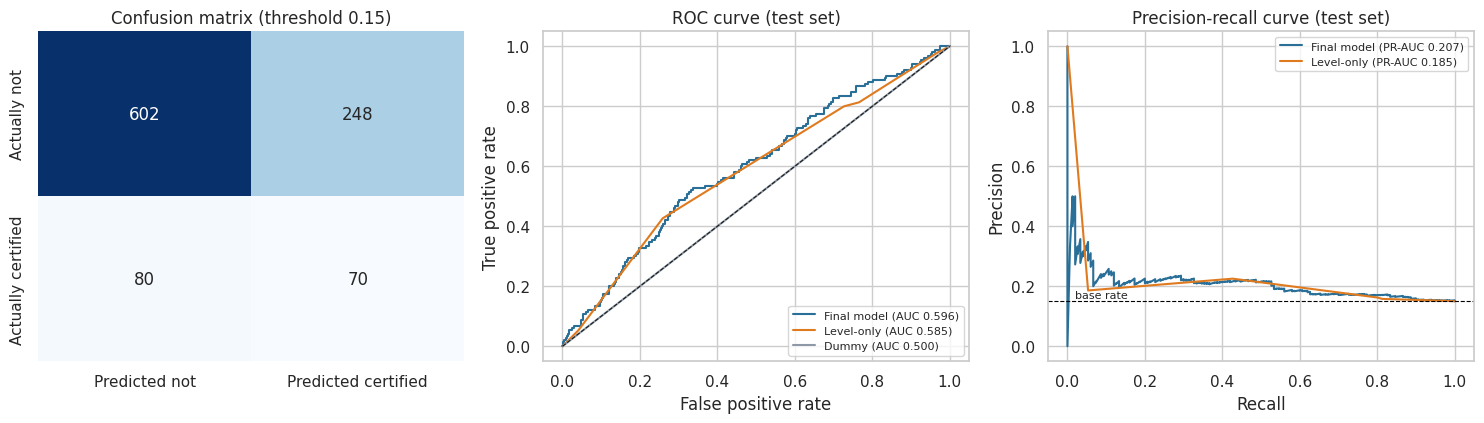

In [130]:
pred_final = (p_final >= THRESH).astype(int)
cm = confusion_matrix(y_test, pred_final)
tn, fp, fn, tp = cm.ravel()

print(f'True negatives: {tn} \nFalse positives: {fp} \nFalse negatives: {fn} \nTrue positives: {tp}')
print(f'Of {tp+fp} institutions flagged, {tp} are certified ({tp/(tp+fp):.1%}); the base rate is {y_test.mean():.1%}')
print(f'Of {tp+fn} certified institutions, {tp} were found ({tp/(tp+fn):.1%})')

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
sns.heatmap(cm, annot = True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Predicted not', 'Predicted certified'], yticklabels=['Actually not', 'Actually certified'])

axes[0].set_title(f'Confusion matrix (threshold {THRESH:.2f})')
for lab, p, col in [('Final model', p_final, '#2a6f97'), ('Level-only', p_lvl, '#e07a1f'), ('Dummy', p_dummy, '#8d99a6')]:
    fpr, tpr, _ = roc_curve(y_test, p); axes[1].plot(fpr, tpr, color=col, label=f'{lab} (AUC {roc_auc_score(y_test, p):.3f})')

axes[1].plot([0, 1], [0, 1], 'k--', lw=0.8); axes[1].set_xlabel('False positive rate'); axes[1].set_ylabel('True positive rate')
axes[1].set_title('ROC curve (test set)'); axes[1].legend(loc='lower right', fontsize=8)
for lab, p, col in [('Final model', p_final, '#2a6f97'), ('Level-only', p_lvl, '#e07a1f')]:
    pr, rc, _ = precision_recall_curve(y_test, p); axes[2].plot(rc, pr, color=col, label=f'{lab} (PR-AUC {average_precision_score(y_test, p):.3f})')
axes[2].axhline(y_test.mean(), color='black', ls='--', lw=0.8); axes[2].text(0.02, y_test.mean()+0.01, 'base rate', fontsize=8)
axes[2].set_xlabel('Recall'); axes[2].set_ylabel('Precision'); axes[2].set_title('Precision-recall curve (test set)'); axes[2].legend(fontsize=8)

plt.tight_layout();
plt.savefig(f'/content/drive/MyDrive/AltSchool_Africa/test_performance.png', bbox_inches='tight');
plt.show()

**Reading the results:**

| Measure | Final model | Level-only baseline | Dummy |
|---|---|---|---|
| ROC-AUC | 0.596 | 0.585 | 0.500 |
| PR-AUC (base rate 0.150) | 0.207 | 0.185 | 0.150 |
| Precision | 0.220 | 0.225 | 0.000 |
| Recall | 0.467 | 0.427 | 0.000 |
| F1 | 0.299 | 0.295 | 0.000 |
| Accuracy | 0.672 | 0.694 | 0.850 |

- The final model beats chance (AUC 0.596 against 0.500), and its CV estimate (0.590) held up on unseen data. That is a sign the result is not an artefact of overfitting.

- Of 318 institutions flagged, 70 are certified: a precision of 22.0% against a 15.0% base rate, about 1.5 times better than picking at random. It finds 46.7% of the 150 certified institutions, at the cost of 248 false alarms.

- **Accuracy is lower than for the dummy model (0.672 against 0.850).** This is expected, not a defect: the dummy model reaches 85% by never flagging anything, so it finds no certified institution at all. This is the reason accuracy is not the primary metric here.

- The final model and the level-only baseline are almost identical on every measure.

In [131]:
# How uncertain is the test result?
# Paired bootstrap over test institutions (same resample for every model)

rng = np.random.default_rng(42)
n = len(y_test); yv = y_test.values
B = 2000
boot = {'final': [], 'level': [], 'diff': []}

for _ in range(B):
    i = rng.integers(0, n, n)
    if yv[i].sum() in (0, n):
        continue
    a, b = roc_auc_score(yv[i], p_final[i]), roc_auc_score(yv[i], p_lvl[i])
    boot['final'].append(a); boot['level'].append(b); boot['diff'].append(a - b)
ci = lambda v: tuple(np.round(np.percentile(v, [2.5, 97.5]), 3))

print('Final model AUC        :', round(roc_auc_score(yv, p_final), 3), '95% interval', ci(boot['final']))
print('Level-only AUC         :', round(roc_auc_score(yv, p_lvl), 3), '95% interval', ci(boot['level']))
print('Final minus level-only :', round(roc_auc_score(yv, p_final) - roc_auc_score(yv, p_lvl), 3), '95% interval', ci(boot['diff']))
print('Share of resamples where the final model beats level-only:', round(float((np.array(boot['diff']) > 0).mean()), 3))

Final model AUC        : 0.596 95% interval (np.float64(0.544), np.float64(0.644))
Level-only AUC         : 0.585 95% interval (np.float64(0.535), np.float64(0.632))
Final minus level-only : 0.011 95% interval (np.float64(-0.03), np.float64(0.055))
Share of resamples where the final model beats level-only: 0.698


- The final model's AUC is 0.596 (95% interval 0.544 to 0.644). Its advantage over the level-only baseline is +0.011, with an interval from -0.030 to +0.055.

- The interval includes zero, and the final model comes out ahead in only about 70% of resamples. **On this test set, the model does not demonstrably beat the baseline.** The cross-validation gain (+0.023, p = 0.080) pointed the same way but was also not conclusive.

**Business translation:**

- The model does somewhat better than guessing, but nearly all of that comes from knowing the school level, which the organization already knows. Size and staffing may add a little; this data cannot confirm it.

In [132]:
# Does it work equally well for every kind of institution?

seg = []
for col in ['level', 'control']:
    for g, idx in test.groupby(col).groups.items():
        yy = y_test.loc[idx]; pp = pd.Series(p_final, index=test.index).loc[idx]
        auc = roc_auc_score(yy, pp) if yy.nunique() == 2 and yy.sum() >= 5 else np.nan
        seg.append({'Group': col, 'Value': g, 'Test rows': len(idx), 'Certified': int(yy.sum()),
                    'Actual rate %': round(100*yy.mean(), 1),
                    'Mean predicted %': round(100*pp.mean(), 1),
                    'Within-group AUC': round(auc, 3) if auc == auc else 'too few'})

segment_table = pd.DataFrame(seg)
segment_table

,Group,Value,Test rows,Certified,Actual rate %,Mean predicted %,Within-group AUC
0,level,2-Year College,29,3,10.3,17.7,too few
1,level,4-Year University,43,8,18.6,22.1,0.664
2,level,Elementary School,454,56,12.3,12.9,0.524
3,level,High School,241,56,23.2,19.5,0.489
4,level,K-12 Combined,35,2,5.7,12.7,too few
5,level,Middle School,198,25,12.6,13.1,0.566
6,control,Private For-Profit,22,3,13.6,15.7,too few
7,control,Private Non-Profit,86,20,23.3,16.6,0.603
8,control,Private Religious,42,5,11.9,15.6,0.389
9,control,Public,731,108,14.8,14.9,0.596


- The model is reasonably calibrated by group on average: for example it predicts 19.5% for High Schools (actual 23.2%) and 12.9% for Elementary Schools (actual 12.3%).

- Within a group, ranking is weak. Within High Schools the AUC is 0.489, which is no better than chance, and within Elementary Schools it is 0.524. This means that once the school level is known, the model cannot tell which High Schools or Elementary Schools are certified.

- The higher within-group AUC for 4-Year Universities (0.664) rests on 8 certified institutions and should not be trusted.

- Groups with fewer than 5 certified institutions in the test set are marked "too few" and not scored.

*Phase 7: Interpret the final model*

In [133]:
if hasattr(final_model[-1] if hasattr(final_model, '__getitem__') else final_model, 'coef_'):
    names = final_model['prep'].get_feature_names_out(); coefs = final_model['model'].coef_[0]
    ct = pd.DataFrame({'term': [n.split('__')[1] for n in names], 'coefficient': coefs, 'odds ratio': np.exp(coefs)}).round(3)
    ct = ct.reindex(ct['coefficient'].abs().sort_values(ascending=False).index).reset_index(drop=True)
    display(ct)
else:
    print('The final model is not linear; see permutation importance below.')

,term,coefficient,odds ratio
0,level_High School,0.276,1.318
1,level_Middle School,-0.121,0.886
2,level_2-Year College,-0.094,0.910
3,total_enrollment,0.083,1.087
4,number_of_teachers,0.082,1.086
5,level_Elementary School,-0.072,0.931
6,student_teacher_ratio,-0.071,0.932
7,level_4-Year University,0.024,1.025
8,level_K-12 Combined,-0.014,0.986


- Being a High School is the strongest term (odds ratio 1.32), in line with the 22% certification rate found in the exploratory data analysis.

- Larger institutions (more enrollment or more teachers) have slightly higher odds (about 1.09 per standard deviation each), and a higher student-teacher ratio slightly lower odds (0.93). Enrollment and teacher numbers move together, so these two should be read as one "size" signal, not as separate effects.

- All effects are small. No coefficient suggests a strong link.


In [134]:
# Grouped permutation importance on the test set

rng = np.random.default_rng(42)
base_auc = roc_auc_score(y_test, final_model.predict_proba(test[final_features])[:, 1])

rows = []
for g, cols in FEATURE_GROUPS.items():
    cols_in = [c for c in cols if c in final_features]
    drops = []
    for _ in range(30):
        Xp = test[final_features].copy()
        perm = rng.permutation(len(Xp))
        for c in cols_in:
            Xp[c] = Xp[c].values[perm]
        drops.append(base_auc - roc_auc_score(y_test, final_model.predict_proba(Xp)[:, 1]))
    rows.append({'Feature group': g, 'in model': bool(cols_in), 'AUC drop (mean)': np.mean(drops), 'SD': np.std(drops)})

perm_table = pd.DataFrame(rows).sort_values('AUC drop (mean)', ascending=False).reset_index(drop=True)
perm_table.round(4)

,Feature group,in model,AUC drop (mean),SD
0,School level,True,0.0457,0.0146
1,Size and staffing,True,0.0325,0.0166
2,Ownership,False,0.0000,0.0000
3,Title I status,False,0.0000,0.0000
4,Locale type,False,0.0000,0.0000
5,Socioeconomic (lunch share),False,0.0000,0.0000
6,Student needs,False,0.0000,0.0000
7,Demographics,False,0.0000,0.0000
8,Funding,False,0.0000,0.0000
9,Broadband access,False,0.0000,0.0000


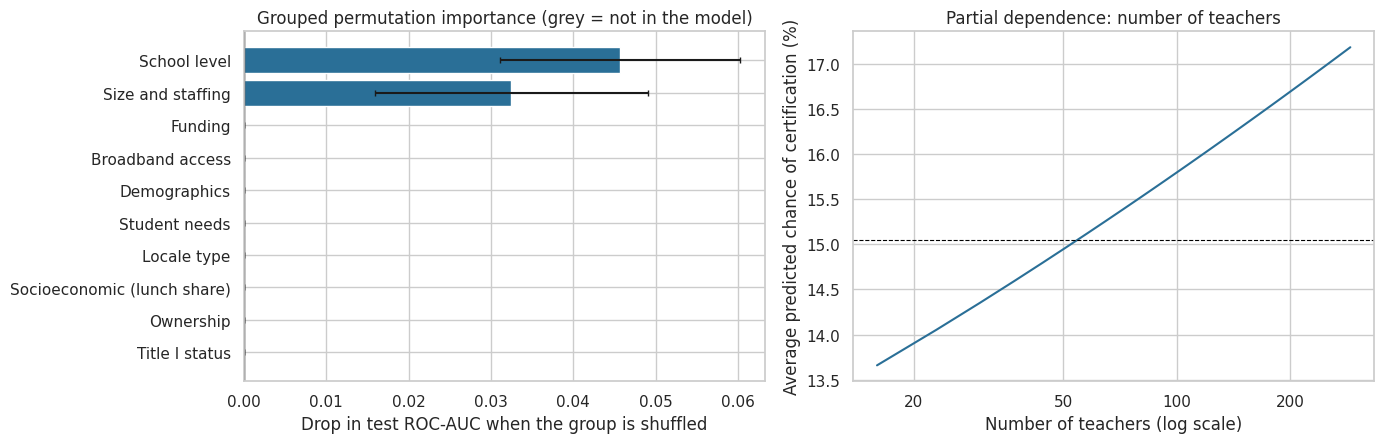

In [135]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
pt = perm_table.sort_values('AUC drop (mean)')
axes[0].barh(pt['Feature group'], pt['AUC drop (mean)'], xerr=pt['SD'],
             color=['#2a6f97' if b else '#8d99a6' for b in pt['in model']], capsize=2)
axes[0].axvline(0, color='black', lw=1);
axes[0].set_xlabel('Drop in test ROC-AUC when the group is shuffled')
axes[0].set_title('Grouped permutation importance (grey = not in the model)')

# Partial dependence: how the predicted chance changes with number of teachers (other inputs left as they are)
feat = 'number_of_teachers' if 'number_of_teachers' in final_features else None
if feat:
    pdp = partial_dependence(final_model, test[final_features].astype({feat: float}), [feat], grid_resolution=40, kind='average')
    axes[1].plot(pdp['grid_values'][0], 100*pdp['average'][0], color = '#2a6f97')
    axes[1].set_xscale('log'); axes[1].xaxis.set_minor_formatter(plt.NullFormatter());
    axes[1].set_xticks([20, 50, 100, 200]); axes[1].set_xticklabels(['20', '50', '100', '200']);
    axes[1].set_xlabel('Number of teachers (log scale)');
    axes[1].set_ylabel('Average predicted chance of certification (%)')
    axes[1].set_title('Partial dependence: number of teachers'); axes[1].axhline(100*y_train.mean(), color='black', ls='--', lw=0.8)
else:
    axes[1].axis('off')

plt.tight_layout(); plt.savefig(f'/content/drive/MyDrive/AltSchool_Africa/4th_Semester/20_interpretation.png', bbox_inches='tight');
plt.show()

In [136]:
if 'number_of_teachers' in final_features:
    grid = pdp['grid_values'][0]; avg = 100*pdp['average'][0]
    print(f'Average predicted chance ranges from {avg.min():.1f}% (at {grid[avg.argmin()]:.0f} teachers) to {avg.max():.1f}% (at {grid[avg.argmax()]:.0f} teachers)')

Average predicted chance ranges from 13.7% (at 16 teachers) to 17.2% (at 289 teachers)


- School level (AUC drop 0.046) and size and staffing (0.033) are the only groups the model uses. The other groups show 0 because they were not in the final model.

- The error bars (SD 0.015 and 0.017) overlap, so the two groups cannot be ranked against each other reliably.

- The partial dependence plot shows the model's average predicted chance rising slowly with the number of teachers, from 13.7% (16 teachers) to 17.2% (289 teachers). It is a gentle slope, not a threshold effect. The line is straight on the log scale because the model is linear in log teachers.

*Phase 8: Sensitivity Checks*

In [137]:
# Sensitivity 1:
# add academic outcome measures (training data, same folds).
# If these jump the AUC, the earlier worry that they follow from certification is relevant.

OUTCOMES = ['math_proficiency_pct', 'reading_proficiency_pct', 'graduation_rate_pct', 'chronic_absenteeism_pct']
feats_o = ALL_FEATURES + OUTCOMES
a_o, _ = run_cv(make_pipeline(LogisticRegression(C=C_best, max_iter=3000), feats_o), feats_o)
a_ref, _ = run_cv(make_pipeline(LogisticRegression(C=C_best, max_iter=3000), ALL_FEATURES), ALL_FEATURES)
d, t, p = corrected_paired_test(a_o, a_ref)

print(f'All features:                 CV AUC {a_ref.mean():.3f}')
print(f'All features + 4 outcomes:    CV AUC {a_o.mean():.3f}   (change {d:+.3f}, corrected p {p:.3f})')

All features:                 CV AUC 0.580
All features + 4 outcomes:    CV AUC 0.579   (change -0.001, corrected p 0.721)


In [138]:
# Sensitivity 2:
# High Schools and K-12 Combined schools only,
# adding the readiness measures (SAT, ACT, AP/IB, post-secondary enrollment)

READY = ['avg_sat_score', 'avg_act_score', 'ap_ib_participation_pct', 'postsecondary_enrollment_pct']
sub = train[train['level'].isin(['High School', 'K-12 Combined'])].reset_index(drop=True)
ysub = sub[TARGET]
print(f'Subset: {len(sub)} institutions, {int(ysub.sum())} certified ({ysub.mean():.1%})')

def sub_cv(feats):
    r = cross_validate(make_pipeline(LogisticRegression(C=C_best, max_iter=3000),
                                     feats), sub[feats], ysub, cv=cv, scoring='roc_auc')
    return r['test_score']

s_base = sub_cv(ALL_FEATURES); s_ready = sub_cv(ALL_FEATURES + READY)
d, t, p = corrected_paired_test(s_ready, s_base)

print(f'Characteristics only:               CV AUC {s_base.mean():.3f}')
print(f'Characteristics + readiness measures: CV AUC {s_ready.mean():.3f}   (change {d:+.3f}, corrected p {p:.3f})')

Subset: 1145 institutions, 235 certified (20.5%)
Characteristics only:               CV AUC 0.537
Characteristics + readiness measures: CV AUC 0.529   (change -0.008, corrected p 0.077)


- Adding academic outcomes makes no difference (0.580 to 0.579, p = 0.721). So the decision to exclude them cost nothing, and there is no sign that they leak information about certification.

- Among High Schools and K-12 Combined schools alone, the characteristics give an AUC of 0.537, close to chance, and adding the readiness measures does not help (0.529, p = 0.077). Within the level that has the highest certification rate, the characteristics cannot tell which schools are certified.

**Business translation:**

- The weak result is not caused by leaving out the outcome variables. The available characteristics simply carry little information about which institutions are certified.

In [139]:
out = pd.concat([
    shortlist_table.assign(stage='first round (training CV)'),
    final_table.rename(columns={'gain over level-only': 'AUC vs level-only'}).assign(stage='tuned candidates (training CV)'),
], ignore_index=True)
out.to_csv('/content/drive/MyDrive/AltSchool_Africa/4th_Semester/model_cv_results.csv', index=False)
results.round(4).to_csv('/content/drive/MyDrive/AltSchool_Africa/4th_Semester/model_test_results.csv')
print('saved reports/model_cv_results.csv and reports/model_test_results.csv')

saved reports/model_cv_results.csv and reports/model_test_results.csv


**What we found:**

- Prediction from institutional characteristics is weak. The best model reaches a test ROC-AUC of 0.596 (95% interval 0.544 to 0.644) and PR-AUC of 0.207 against a base rate of 0.150.

- Most of that comes from school level. A model that uses level alone reaches 0.585, and the difference between the two (+0.011, interval -0.030 to +0.055) is not distinguishable from zero on this test set.

- Eight model types, tuning and an ensemble all landed within about 0.02 AUC of each other. More complex models did not help; tuning made them simpler.

- Size and staffing is the only group beyond level with any sign of value (+0.020 AUC, p = 0.008 uncorrected, 0.072 after correcting for nine groups).

- At the chosen threshold, the model flags 32% of institutions, catches 46.7% of the certified ones, and 22.0% of those flagged are certified (base rate 15.0%).

- Within a school level, the model cannot tell certified from non-certified institutions (High School AUC 0.489).

- Excluding academic outcomes and readiness measures did not change the conclusion.


**Business / Policy Insight**

In [140]:
# Let's define helper functions to calculate and present the STEM certification rates
# (along with their confidence intervals) across different categories, specifically by school level.

def wilson(k, n, z = 1.96):
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2*n)) / d; h = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / d
    return c - h, c + h

def rate_table(col, order = None):
    g = model_data.groupby(col).is_certified.agg(['size', 'sum']).rename(columns = {'size': 'institutions', 'sum': 'certified'})
    g['rate %'] = 100 * g['certified'] / g['institutions']
    ci = [wilson(k, n) for k, n in zip(g['certified'], g['institutions'])]
    g['low'] = [100*a for a, b in ci]; g['high'] = [100*b for a, b in ci]
    return g.loc[order] if order else g.sort_values('rate %', ascending = False)

by_level = rate_table('level')
by_level.round(1)

,institutions,certified,rate %,low,high
level,,,,,
4-Year University,204,46,22.5,17.4,28.8
High School,1209,269,22.2,20.0,24.7
Elementary School,2225,278,12.5,11.2,13.9
Middle School,996,118,11.8,10.0,14.0
K-12 Combined,212,24,11.3,7.7,16.3
2-Year College,154,17,11.0,7.0,17.0


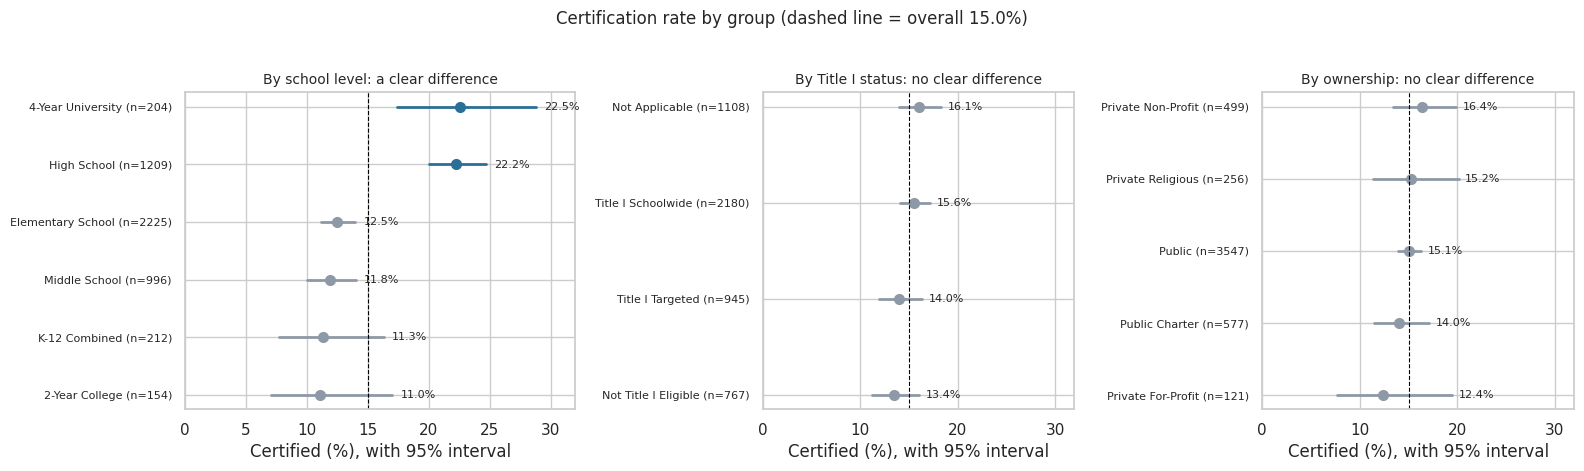

In [141]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={'width_ratios': [1.25, 1, 1]})
def dots(ax, tbl, title, hi=()):
    t = tbl.iloc[::-1]
    for i, (name, r) in enumerate(t.iterrows()):
        c = '#2a6f97' if name in hi else '#8d99a6'
        ax.plot([r['low'], r['high']], [i, i], color=c, lw=2); ax.plot(r['rate %'], i, 'o', color=c, ms=7)
        ax.text(r['high'] + 0.7, i, f"{r['rate %']:.1f}%", va='center', fontsize=8)
    ax.set_yticks(range(len(t))); ax.set_yticklabels([f'{n} (n={int(v)})' for n, v in zip(t.index, t['institutions'])], fontsize=8)
    ax.axvline(100*model_data.is_certified.mean(), color='black', ls='--', lw=0.8)
    ax.set_xlim(0, 32); ax.set_xlabel('Certified (%), with 95% interval'); ax.set_title(title, fontsize=10)

dots(axes[0], by_level, 'By school level: a clear difference', hi=('High School', '4-Year University'))
dots(axes[1], rate_table('title_i_status'), 'By Title I status: no clear difference')
dots(axes[2], rate_table('control'), 'By ownership: no clear difference')

fig.suptitle('Certification rate by group (dashed line = overall 15.0%)', y=1.02, fontsize=12)
plt.tight_layout();
plt.savefig(f'/content/drive/MyDrive/AltSchool_Africa/4th_Semester/certification_story.png', bbox_inches='tight');
plt.show()

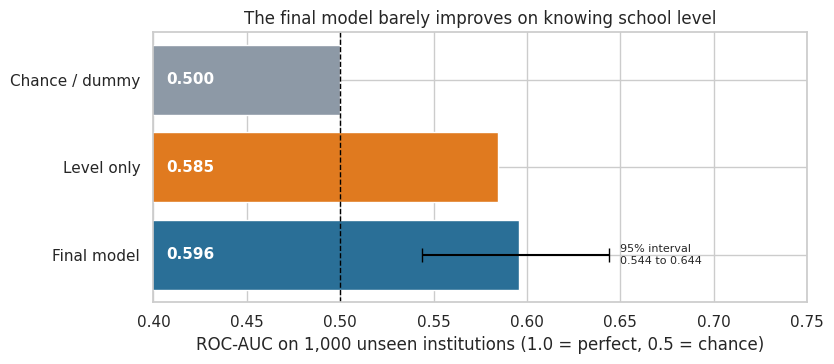



                                                 ROC-AUC  PR-AUC  Accuracy  Precision  Recall     F1  Share flagged
Model                                                                                                              
Dummy (base rate)                                  0.500   0.150     0.850      0.000   0.000  0.000          0.000
Level-only logistic                                0.585   0.185     0.694      0.225   0.427  0.295          0.284
FINAL: Reduced logistic (level + size/staffing)    0.596   0.207     0.672      0.220   0.467  0.299          0.318


In [142]:
test_res = pd.read_csv('/content/drive/MyDrive/AltSchool_Africa/4th_Semester/model_test_results.csv', index_col=0)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
labels = ['Chance / dummy', 'Level only', 'Final model']
vals = [test_res.loc['Dummy (base rate)', 'ROC-AUC'], test_res.loc['Level-only logistic', 'ROC-AUC'],
        test_res.filter(like='FINAL', axis=0)['ROC-AUC'].iloc[0]]

ax.barh(labels[::-1], vals[::-1], color = ['#2a6f97','#e07a1f', '#8d99a6']);
ax.set_xlim(0.4, 0.75)
ax.axvline(0.5, color='black', lw=1, ls='--')
ax.errorbar([vals[2]], [0], xerr=[[vals[2]-0.544], [0.644-vals[2]]], color='black', capsize=5, lw=1.5)
ax.text(0.65, 0, '95% interval\n0.544 to 0.644', fontsize=8, va='center')

for yy, v in zip([2, 1, 0], vals):
    ax.text(0.407, yy, f'{v:.3f}', va='center', fontsize=11, weight='bold', color='white')
ax.set_xlabel('ROC-AUC on 1,000 unseen institutions (1.0 = perfect, 0.5 = chance)')
ax.set_title('The final model barely improves on knowing school level')

plt.tight_layout();
plt.savefig(f'/content/drive/MyDrive/AltSchool_Africa/4th_Semester/model_value.png', bbox_inches='tight');
plt.show()
print('\n')
print(test_res.round(3).to_string())

### Insight 1: School level is the one characteristic that clearly goes with certification

**What it means:**
- High Schools and 4-Year Universities are certified at about twice the rate of other levels.

- Looking for certified institutions among them is more productive than looking elsewhere.

**Evidence:**

- High Schools 22.2% and 4-Year Universities 22.5%, against 11.0% to 12.5% for Elementary Schools, Middle Schools, 2-Year Colleges and K-12 Combined schools.

- The gap is 10.1 percentage points (95% interval 7.8 to 12.5), a ratio of 1.83. The chi-square test for level gives p < 0.001 (Cramér's V = 0.128) and survives correction for multiple tests.

**Possible explanations (not tested):**

- STEM certification may be more common where there are dedicated STEM courses, labs or specialist teachers, which are more typical in upper secondary and university settings. Certification criteria may also differ by level.

**Limitations:**

- The effect is real but moderate (Cramér's V = 0.128). The 4-Year University and 2-Year College groups are small (204 and 154 institutions).

- The High School plus 4-Year University grouping was chosen after seeing the EDA, although pairwise tests with correction support it.

**Investigate next:**

- Whether the certification criteria or the certifying body differ by level, and whether the pattern is the same in other years.



### Insight 2: Certification does not track resources or need in this data

**What it means:**
- Among the characteristics available, none of the resource, need or demographic measures separates certified from non-certified schools once level is allowed for.

- The data show no sign that certification is concentrated among better-funded or lower-need schools, or the reverse.

**Evidence:**

- Title I status: p = 0.288 (0.556 after allowing for level); rates range only from 13.4% to 16.1% across the four Title I categories.

- Ownership p = 0.757 and locale type p = 0.684; state p = 0.641 (shuffle test).

- Within K-12 schools, 0 of 12 numeric characteristics (spending, free/reduced lunch share, broadband, funding shares, special-education and English-learner shares, enrollment, student-teacher ratio and outcomes) separate certified from non-certified after correction. Their AUCs range from 0.474 to 0.520, where 0.5 means no difference.

**Possible explanations:**

- Certification may depend on factors not recorded here (programme content, teacher qualifications, local policy or decisions by school leaders). It is also possible that the certification flag in this dataset is not strongly tied to the recorded characteristics.

**Limitations:**

- "No detected pattern" does not prove "no pattern". The intervals are about plus or minus 0.025 around AUC 0.5, so only differences larger than that could be detected. Several measures are capped at limits (during data cleaning), which can hide differences at the extremes.

**Investigate next:**

- Collect measures of STEM programme provision and teacher qualifications, then repeat the comparison.

### Insight 3: Per-pupil spending moves with math proficiency, but not with certification

**What it means:**

- Where spending is higher, math proficiency tends to be higher, even after allowing for the share of students on free or reduced lunch.

- Certification does not show the same link to spending.


**Evidence:**

- Partial Spearman correlation between per-pupil spending and math proficiency, holding lunch share fixed: 0.178 (95% interval 0.148 to 0.203).

- Broadband access (0.000), federal funding share (-0.006) and student-teacher ratio (0.011) have intervals that include zero.

- Spending versus certification in K-12 schools: AUC 0.500, p = 0.978.

**Possible explanations:**

- Spending may reflect other differences in school districts, such as local wealth or cost of living, that also relate to achievement.

**Limitations:**

- The correlation of 0.18 is small to moderate. It is an association, and it was not adjusted for anything other than lunch share. It says nothing about whether raising spending would raise proficiency.

**Investigate next:**

- A controlled comparison with more adjustment variables, or a study of changes in spending over time within the same schools.

### Insight 4: A prediction model built on these characteristics adds little beyond school level

**What it means:**

- The available characteristics predict certification only slightly better than chance, and nearly all of that comes from school level.

- A model is not a reliable way to decide which institutions are or should be certified.


**Evidence:**

- On 1,000 unseen institutions, the final model's ROC-AUC is 0.596 (95% interval 0.544 to 0.644). The level-only baseline is 0.585, and the gap of +0.011 has an interval of -0.030 to +0.055.

- Eight model types, tuning and an ensemble all fell within about 0.02 AUC of each other, so the weak result does not come from a poor choice of model.

- Within High Schools, the model's AUC is 0.489, which is no better than chance.

- At the chosen cut-off the model flags 31.8% of institutions, finds 46.7% of certified ones, and 22.0% of those flagged are certified, against 15.0% overall (about 1.5 times better than random selection).

**Possible explanations:**

- The recorded characteristics may simply not contain the information that determines certification.

- The pattern could also be too weak to detect with 602 certified cases for training.

**Limitations:**

- The test set has only 150 certified cases, so small differences cannot be resolved. Size and staffing was the only group beyond level with any sign of value (+0.020 AUC; p = 0.008 uncorrected, 0.072 after correcting for nine groups), and it is not confirmed.

**Investigate next:**
-  Whether size and staffing (enrollment, number of teachers, student-teacher ratio) adds anything in new data, and whether features that describe STEM programmes improve prediction.

### Recommendations

**Recommendation 1: Use school level to focus outreach, not a prediction model**


**Finding**

- Level is the only characteristic that clearly goes with certification. A full model adds little beyond it.

**Evidence**

-  High Schools and 4-Year Universities certified at 22.2% and 22.5% against 11.0% to 12.5% elsewhere (gap 10.1 points, interval 7.8 to 12.5).

- Test AUC 0.596 for the model against 0.585 for level alone.

**Recommendation**
- If the aim is to find certified institutions, or those close to certification, start with High Schools and 4-Year Universities. Do not build or buy a prediction tool from these characteristics.

**Expected impact**
- Targeting about as good as the model's (the model's precision on the test set was 22.0%) with no model to maintain. Roughly one in five institutions in those groups is certified (22.2% and 22.5%), compared with about one in seven overall (15.0%).

**NB**
- This describes where certified institutions are today. It does not show that other levels are less able to become certified.

### Recommendation 2: Do not use these characteristics to rank institutions for support or funding decisions

**Finding**
- Resource, need and demographic characteristics do not separate certified from non-certified institutions. The model is close to chance within each level.

**Evidence**
- 0 of 12 numeric characteristics significant after correction; within High Schools the model's AUC is 0.489.

**Recommendation**
- Treat the model's scores as, at most, a rough screening aid. Do not use them to decide which institutions to fund, support or rank.

**Expected impact**
Avoids acting on scores that are close to chance. In the test set, flagging 318 institutions produced 70 correct and 248 false alarms.

**NB**
- The costs of a wrong flag were not provided. If false alarms are cheap, a screening aid may still be worth using.

### Recommendation 3: Examine whether certification reaches high-need schools, using better data

**Finding**
- Certification rates are similar across Title I categories and ownership types. The data show no gap, but also cannot explain what drives certification.


**Evidence**
- Title I p = 0.288 (0.556 after allowing for level), rates 13.4% to 16.1%; ownership p = 0.757.

**Recommendation**
- Before concluding that certification is equitable, add information on what certification involves (STEM courses, labs, teacher qualifications, year certified) and repeat the comparison with that information.


**Expected impact**
-  Would show whether the similar rates reflect a fair system or just an absence of the measures that matter. It also gives a model something to predict from.

**NB**
- Rates being equal across groups does not mean access or quality is equal. This dataset cannot test that.

### Recommendation 4: Test the size and staffing signal before acting on it

**Finding**
- Size and staffing is the only group beyond level with any sign of value.

**Evidence**
- +0.020 AUC over level alone (corrected p = 0.008, but 0.072 after allowing for nine groups tried); it is the only group the final model uses beyond level, and the final model's test gain was +0.011 (interval -0.030 to +0.055).

**Recommendation**
- Treat this as a hypothesis. Check it on a new year of data, or a fresh sample, before any decision depends on it.

**Expected impact**
- Prevents building on a pattern that may be chance, and, if confirmed, adds a second useful targeting characteristic.

**NB**
- Enrollment and teacher counts move together and also reflect school level, so a real signal could not be assigned to a single cause.

### Recommendation 5: Use per-pupil spending as a lead for further study of math outcomes

**Finding**
- Spending is the only resource measure with a steady association with math proficiency after allowing for lunch share.

**Evidence**
- Partial Spearman 0.178 (95% interval 0.148 to 0.203). Broadband, federal funding share and student-teacher ratio show nothing.

**Recommendation**
- If the organization's wider interest is academic outcomes, study spending further, with more adjustment variables or changes over time, and deprioritise broadband access and federal funding share as explanations in this data.

**Expected impact**
- Directs analysis time to the one lead the data support.

**NB**
- This is an association only. The data do not show that more spending raises proficiency.

**Summary of What was found:**

- School level is the one clear pattern: High Schools and 4-Year Universities are certified at about 22%, other levels at 11% to 12.5%.

- Resource, need and demographic characteristics do not separate certified from non-certified institutions.

- Spending goes with math proficiency (0.178) but not with certification.

- The best model reaches a test ROC-AUC of 0.596, against 0.585 for school level alone. The difference is not shown to be real.

## Suggested next steps for the stakeholder

| Priority | Action | Why |
|---|---|---|
| 1 | Add STEM programme variables (courses offered, labs, teacher qualifications, year of certification) | The present characteristics carry little information about certification |
| 2 | Re-test the size and staffing signal on new data | It is the only unresolved lead for prediction |
| 3 | Agree the cost of a missed institution versus a false alarm | Needed to set a meaningful threshold if a screening aid is used |
| 4 | Repeat the analysis in a later year | Tests whether the level pattern is stable |